# Case Study 3: Microgrid Assessment
### Kigeme microgrid and Nyabiheke Hall, Rwanda (July 2019 to March 2020)

**CMU-Africa 04-782 Energy Data Analytics** · Dukundimana Toussaint (tdukundi) and Rasheed Adarijo · Data: Zenodo record 4304799

**Main question (Q3).** Could spare capacity support additional services with limited investment?
Q1 (*is the system performing as expected?*) and Q2 (*is it meeting current service needs?*) are answered as safety checks on Q3.

| Part | Content | Questions |
|---|---|---|
| A | System level: data audit, energy balance, efficiencies, battery, PV calibration, unused solar, reliability | Q1, Q2, Q3 |
| B | Device level: circuit faults, streetlight baseline, Kigeme vs Hall fault rate | Q1, Q2 |
| C | Service delivery: load timing, meters, socket use | Q2 |
| D | Spare capacity: power, storage and refill tests, reserve-floor sensitivity | Q3 |
| E | Answers, recommendations, limitations | all |

**Data-quality rules (fixed before any calculation)**
1. Repeated timestamps: power and SOC are averaged; energy counters take the last value.
2. An interval counts for energy only if it is no longer than the site gap limit (Kigeme 10 min, Hall 30 min). Longer intervals are gaps: no energy, no coverage, nothing filled in.
3. A blank is never turned into zero. A zero counts only where the logger recorded 0.
4. Monthly figures and model comparisons use complete days only (at least 90% of the day covered).
5. Device meters are compared with system AC but never added to it.
6. Device fault detection holds each sparse reading as a state for at most 6 hours, then aggregates to weekly dark fractions.


## 0. Setup
Site ratings and analysis assumptions. Values not given in the case material are marked *assumed* in the table below.

| Setting | Kigeme | Hall | Note |
|---|---|---|---|
| PV / battery | 2.5 kWp / 21.1 kWh | 2.04 kWp / 10.6 kWh | case table |
| Inverter limit 25 C / 40 C | 960 / 900 W | 2,400 / 2,200 W | datasheets |
| Inverter VA rating | 1,200 VA | 3,000 VA | Kigeme assumed (1.2 kVA) |
| Reserve floor / hard cut-off | 50% / 20% | 50% / 20% | assumed |
| Low-sun stress case | PV x 0.7 | PV x 0.7 | assumed |

In [1]:

from pathlib import Path
import os
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Display and plotting settings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Automatically locate the project folder
# Works when Microgrid/ and Hall/ are beside the notebook
# or inside a parent project folder.
search_paths = [Path.cwd().resolve(), *Path.cwd().resolve().parents]

DATA = next(
    (
        path for path in search_paths
        if (path / "Microgrid").is_dir()
        and (path / "Hall").is_dir()
    ),
    None,
)

if DATA is None:
    raise FileNotFoundError(
        "Project data folders not found. Please extract the complete "
        "submission ZIP and keep Microgrid/ and Hall/ together "
        "in the project folder."
    )

# Define input and output directories
MICROGRID_DIR = DATA / "Microgrid"
HALL_DIR = DATA / "Hall"

DATA_DIR, MG_DIR, HL_DIR = DATA, MICROGRID_DIR, HALL_DIR

OUT = DATA / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

# Save tables and figures
def save(df, name):
    df.to_csv(OUT / f"{name}.csv", index=False)

def label_bars(ax, bars, fmt="{:.1f}"):
    ax.bar_label(
        bars,
        labels=[fmt.format(b.get_height()) for b in bars],
        padding=3,
        fontsize=10
    )

def show_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

# Site specifications
SITES = {
    "Kigeme": {
        "folder": "Microgrid",
        "kwp": 2.5,
        "batt_kwh": 21.1,
        "gap_min": 10,
        "limit_25": 960,
        "limit_40": 900,
        "va": 1200,
        "lat": -2.48507,
        "lon": 29.52711,
        "low_soc": 70,
        "color": "tab:blue"
    },
    "Nyabiheke Hall": {
        "folder": "Hall",
        "kwp": 2.04,
        "batt_kwh": 10.6,
        "gap_min": 30,
        "limit_25": 2400,
        "limit_40": 2200,
        "va": 3000,
        "lat": -1.57367,
        "lon": 30.26891,
        "low_soc": 65,
        "color": "tab:orange"
    },
}

NAMES = list(SITES)

# Analysis settings
MIN_DAY_COV = 0.90
MIN_HOUR_COV = 0.75
FLOOR = 0.50
SOC_CUTOFF = 20
STRESS_PV = 0.70
RESYNC_H = 168
PF_SYSTEM = 0.8
GEL_FULL_CYCLES = (375, 540)

# Operating schedules
SCHEDULES = {
    "Kigeme": [
        ("Nursery and street lights", 18, 30),
        ("Playground full", 17.5, 24),
        ("Playground half", 24, 29),
    ],
    "Nyabiheke Hall": [
        ("Outdoor lights", 18.5, 30),
    ],
}

# Confirm that the project files are accessible
print("Project folder:", DATA)
print("Data folder exists:", DATA.exists())

for folder in (MICROGRID_DIR, HALL_DIR):
    csv_files = list(folder.glob("*.csv"))
    print(f"{folder.name}: {len(csv_files)} CSV files found")

    if not csv_files:
        raise FileNotFoundError(
            f"No CSV files found in {folder}. "
            "Check that the data files are included in the ZIP."
        )

print("Output folder:", OUT)


Project folder: C:\Users\hp\Desktop\CMU\energy for data analytics\Case Study 3\Case study 3
Data folder exists: True
Microgrid: 16 CSV files found
Hall: 12 CSV files found
Output folder: C:\Users\hp\Desktop\CMU\energy for data analytics\Case Study 3\Case study 3\outputs


---
# Part A. System level (Q1, Q2, Q3)
All of Part A uses `System_data.csv` at each site: PV, controller, battery, inverter and AC load.

## 1. Load and audit the system data

In [2]:
def read_system(path):
    raw = pd.read_csv(path)
    names = {"Timestamp": "time",
             "Battery Monitor State of Charge": "soc",
             "Battery Monitor Discharged Energy": "e_dis",
             "Battery Monitor Charged Energy": "e_chg",
             "Solar Charger Battery Power": "pc",
             "Solar Charger PV Power": "pv",
             "System Overview AC Consumption": "ac",
             "System Overview Battery Power": "pb"}
    d = pd.DataFrame()
    for col in raw.columns:
        for start, short in names.items():
            if str(col).strip().startswith(start):
                d[short] = raw[col]
    d["time"] = pd.to_datetime(d["time"], errors="coerce")
    if d["time"].dt.tz is not None:
        d["time"] = d["time"].dt.tz_localize(None)
    for c in d.columns:
        if c != "time":
            d[c] = pd.to_numeric(d[c], errors="coerce")
    return d.dropna(subset=["time"]).sort_values("time", kind="stable").reset_index(drop=True)

RAW = {n: read_system(DATA / c["folder"] / "System_data.csv") for n, c in SITES.items()}
for n, r in RAW.items():
    print(f"{n:15s} {len(r):>8,} rows   {r['time'].min()}  to  {r['time'].max()}")

Kigeme           354,436 rows   2019-07-02 00:07:50  to  2020-03-31 23:59:37
Nyabiheke Hall    34,090 rows   2019-07-20 00:03:00  to  2020-03-31 23:49:54


In [3]:
def audit(raw, gap_min):
    u = raw.drop_duplicates("time")
    step = u["time"].diff().dt.total_seconds() / 60
    span_h = (raw["time"].max() - raw["time"].min()).total_seconds() / 3600
    lost_h = step[step > gap_min].sum() / 60
    r = {"rows": len(raw),
         "repeated timestamps": len(raw) - len(u),
         "median step (min)": step.median(),
         f"gaps > {gap_min} min": int((step > gap_min).sum()),
         "gaps > 6 h": int((step > 360).sum()),
         "longest gap (h)": step.max() / 60,
         "usable share of span": 1 - lost_h / span_h}
    for c in ["soc", "pv", "pc", "ac", "pb", "e_dis", "e_chg"]:
        r[f"blank {c} (%)"] = 100 * raw[c].isna().mean()
    r["AC recorded as 0 (% of rows)"] = 100 * (raw["ac"] == 0).mean()
    r["counter resets (drops > 0.5 kWh)"] = int((raw["e_dis"].dropna().diff() < -0.5).sum() + (raw["e_chg"].dropna().diff() < -0.5).sum())
    r["negative PV rows"] = int((raw["pv"] < 0).sum())
    return r

AUDIT = pd.DataFrame({n: audit(RAW[n], SITES[n]["gap_min"]) for n in NAMES})
display(AUDIT)
save(AUDIT, "01_quality_audit")

def longest_gaps(raw, k=5):
    u = raw.drop_duplicates("time").reset_index(drop=True)
    g = pd.DataFrame({"gap start": u["time"].shift(1), "gap end": u["time"],
                      "hours": u["time"].diff().dt.total_seconds() / 3600})
    return g.sort_values("hours", ascending=False).head(k).reset_index(drop=True)

for n in NAMES:
    print("\nLongest gaps:", n)
    display(longest_gaps(RAW[n]))

,Kigeme,Nyabiheke Hall
rows,"354,436.00","34,090.00"
repeated timestamps,0.00,"2,509.00"
median step (min),1.00,15.00
gaps > 10 min,"3,027.00",NaN
gaps > 6 h,1.00,0.00
longest gap (h),144.74,1.25
usable share of span,0.86,1.00
blank soc (%),0.00,0.00
blank pv (%),0.00,0.00
blank pc (%),0.00,0.00



Longest gaps: Kigeme


,gap start,gap end,hours
0,2019-09-12 12:34:25,2019-09-18 13:18:43,144.74
1,2019-07-17 07:55:25,2019-07-17 13:28:02,5.54
2,2019-12-31 23:59:17,2020-01-01 01:00:17,1.02
3,2019-09-12 11:16:02,2019-09-12 11:54:37,0.64
4,2019-09-12 12:05:19,2019-09-12 12:28:24,0.38



Longest gaps: Nyabiheke Hall


,gap start,gap end,hours
0,2019-12-31 23:51:02,2020-01-01 01:06:06,1.25
1,2019-12-13 17:00:23,2019-12-13 18:09:21,1.15
2,2019-12-13 19:00:27,2019-12-13 19:45:23,0.75
3,2019-12-23 06:21:13,2019-12-23 06:51:15,0.50
4,2020-01-12 16:28:03,2020-01-12 16:50:44,0.38


**Reading the audit.** Kigeme logs about once a minute but has one 144.7 h hole (12 Sept 12:34 to 18 Sept 13:18), so 86% of its span is usable. The Hall logs every 15 minutes, has 2,509 repeated-timestamp rows and almost no gaps (99.9% usable). The battery energy counters are mostly blank at both sites, so energy comes from integrating power and the counters serve only as a cross-check (Section 3.2). No counter resets or negative PV were found.

## 2. Interval energy
Each pair of consecutive readings is an interval. If it is within the gap limit, energy = mean power x actual duration (trapezoid). Battery power is split into charge (positive) and discharge (negative). The inverter DC input is **inferred** as controller output minus battery power (`Pc - Pb`), because neither inverter has a DC sensor.

In [4]:
POWER = ["pv", "pc", "ac", "pb"]

def merge_duplicates(raw, rule="mean"):
    if rule == "mean":
        agg = {c: "mean" for c in ["soc", "pc", "pv", "ac", "pb"]}
        agg.update({"e_dis": "last", "e_chg": "last"})
    else:
        agg = {c: rule for c in ["soc", "pc", "pv", "ac", "pb", "e_dis", "e_chg"]}
    return raw.groupby("time", as_index=False).agg(agg)

def make_intervals(d, gap_min):
    iv = pd.DataFrame({"t0": d["time"].iloc[:-1].values, "t1": d["time"].iloc[1:].values})
    iv["dt_h"] = (iv["t1"] - iv["t0"]).dt.total_seconds() / 3600
    iv["gap_ok"] = (iv["dt_h"] > 0) & (iv["dt_h"] <= gap_min / 60)
    for c in POWER:
        iv[c] = (d[c].values[:-1] + d[c].values[1:]) / 2
    iv["soc0"] = d["soc"].values[:-1]
    iv["soc1"] = d["soc"].values[1:]
    iv["soc_mid"] = (iv["soc0"] + iv["soc1"]) / 2
    iv["soc_hi"] = np.fmax(iv["soc0"], iv["soc1"])
    iv["ok"] = iv["gap_ok"] & iv[POWER].notna().all(axis=1)
    iv["cov_h"] = np.where(iv["ok"], iv["dt_h"], 0.0)
    iv["inv"] = iv["pc"] - iv["pb"]
    for c in POWER + ["inv"]:
        iv["E_" + c] = np.where(iv["ok"], iv[c] * iv["dt_h"], 0.0)
    iv["E_chg"] = np.where(iv["ok"], iv["pb"].clip(lower=0) * iv["dt_h"], 0.0)
    iv["E_dis"] = np.where(iv["ok"], (-iv["pb"]).clip(lower=0) * iv["dt_h"], 0.0)
    iv["mid"] = iv["t0"] + (iv["t1"] - iv["t0"]) / 2
    iv["date"] = iv["mid"].dt.normalize()
    iv["hour"] = iv["mid"].dt.hour
    return iv

DF = {n: merge_duplicates(RAW[n]) for n in NAMES}
IV = {n: make_intervals(DF[n], SITES[n]["gap_min"]) for n in NAMES}
for n in NAMES:
    print(f"{n:15s} readings after merging: {len(DF[n]):,}   usable interval hours: {IV[n]['cov_h'].sum():,.0f}")

Kigeme          readings after merging: 354,436   usable interval hours: 5,657
Nyabiheke Hall  readings after merging: 31,581   usable interval hours: 6,140


### 2.1 Sensitivity of the totals to the two handling rules

In [5]:
rows = []
for n in NAMES:
    for rule in ["mean", "first", "last"]:
        iv = make_intervals(merge_duplicates(RAW[n], rule), SITES[n]["gap_min"])
        rows.append({"site": n, "test": f"duplicate rule = {rule}", "AC kWh": iv["E_ac"].sum() / 1000, "PV kWh": iv["E_pv"].sum() / 1000})
    for gap in [SITES[n]["gap_min"] / 2, SITES[n]["gap_min"], SITES[n]["gap_min"] * 2, 60]:
        iv = make_intervals(DF[n], gap)
        cov = iv.groupby("date")["cov_h"].sum()
        rows.append({"site": n, "test": f"gap limit = {gap:.0f} min  ({int((cov >= MIN_DAY_COV * 24).sum())} of {len(cov)} days complete)",
                     "AC kWh": iv["E_ac"].sum() / 1000, "PV kWh": iv["E_pv"].sum() / 1000})
SENS = pd.DataFrame(rows).set_index(["site", "test"])
display(SENS)
save(SENS, "02_sensitivity")

AC kWh   PV kWh
site           test                                                            
Kigeme         duplicate rule = mean                            972.83 1,194.48
               duplicate rule = first                           972.83 1,194.48
               duplicate rule = last                            972.83 1,194.48
               gap limit = 5 min  (230 of 270 days complete)    966.92 1,173.79
               gap limit = 10 min  (230 of 270 days complete)   972.83 1,194.48
               gap limit = 20 min  (264 of 270 days complete) 1,100.97 1,333.38
               gap limit = 60 min  (264 of 270 days complete) 1,100.97 1,333.38
Nyabiheke Hall duplicate rule = mean                            603.27   790.66
               duplicate rule = first                           603.53   790.96
               duplicate rule = last                            603.14   790.35
               gap limit = 15 min  (154 of 256 days complete)   505.92   677.86
               gap limit = 30 min  (256 of 256 days complete)   603.27   790.66
               gap limit = 60 min  (256 of 256 days complete)   603.84   790.74
               gap limit = 60 min  (256 of 256 days complete)   603.84   790.74

**Result.** The duplicate rule changes total energy by less than 0.1%. The gap limit matters at Kigeme: a limit shorter than the logger's 10 to 20 minute irregularity discards good intervals, while anything above about 20 minutes changes little. The limits are therefore 10 minutes (Kigeme) and 30 minutes (Hall, two readings at its 15-minute cadence).

## 3. Energy balance and efficiencies (Q1)
Array yield $Y_A=E_{PV}/P_0$, final yield $Y_F=E_{AC}/P_0$, controller efficiency $\eta_c=E_c/E_{PV}$, inferred inverter efficiency $\hat\eta_{inv}=E_{AC}/\hat E_{inv,DC}$ and balance of system $\eta_{BoS}=E_{AC}/E_{PV}$. Every ratio sums numerator and denominator over the same accepted intervals.

In [6]:
def make_daily(iv, d):
    g = iv.groupby("date")
    day = pd.DataFrame({"cov_h": g["cov_h"].sum(),
                        "PV": g["E_pv"].sum() / 1000, "Pc": g["E_pc"].sum() / 1000, "AC": g["E_ac"].sum() / 1000,
                        "InvDC": g["E_inv"].sum() / 1000, "Chg": g["E_chg"].sum() / 1000, "Dis": g["E_dis"].sum() / 1000})
    s = d.groupby(d["time"].dt.normalize())["soc"]
    day["soc_min"], day["soc_max"], day["soc_mean"] = s.min(), s.max(), s.mean()
    day["complete"] = day["cov_h"] >= MIN_DAY_COV * 24
    return day

def make_hourly(iv):
    x = iv.copy()
    x["hr"] = x["mid"].dt.floor("h")
    g = x.groupby("hr")
    h = pd.DataFrame({"cov_h": g["cov_h"].sum()})
    for c in POWER + ["inv"]:
        h[c] = g["E_" + c].sum() / h["cov_h"].replace(0, np.nan)
    h["soc"] = g["soc_mid"].mean()
    h["soc_max"] = g["soc_hi"].max()
    h["E_chg"] = g["E_chg"].sum()
    h["E_dis"] = g["E_dis"].sum()
    h = h[h["cov_h"] >= MIN_HOUR_COV].copy()
    h["date"] = h.index.normalize()
    h["hour"] = h.index.hour
    h["month"] = h.index.to_period("M")
    h["dow"] = h.index.dayofweek
    return h

DAILY = {n: make_daily(IV[n], DF[n]) for n in NAMES}
HOURLY = {n: make_hourly(IV[n]) for n in NAMES}
for n in NAMES:
    print(f"{n:15s} days observed {len(DAILY[n])}, complete {int(DAILY[n]['complete'].sum())}, usable hours {len(HOURLY[n]):,}")

Kigeme          days observed 270, complete 230, usable hours 5,590
Nyabiheke Hall  days observed 256, complete 256, usable hours 6,137


In [7]:
def monthly_kpi(day, kwp):
    d = day[day["complete"]]
    g = d.groupby(d.index.to_period("M"))
    m = g[["PV", "Pc", "AC", "InvDC", "Chg", "Dis"]].sum()
    m["days"] = g.size()
    m["Y_A kWh/kWp/day"] = m["PV"] / m["days"] / kwp
    m["Y_F kWh/kWp/day"] = m["AC"] / m["days"] / kwp
    m["PV/AC"] = m["PV"] / m["AC"]
    m["eta controller"] = m["Pc"] / m["PV"]
    m["eta inverter (inferred)"] = m["AC"] / m["InvDC"]
    m["eta BoS"] = m["AC"] / m["PV"]
    return m

KPI = {}
for n in NAMES:
    KPI[n] = monthly_kpi(DAILY[n], SITES[n]["kwp"])
    print(f"\n{n}: monthly KPIs, complete days only")
    display(KPI[n].drop(columns=["Pc", "InvDC"]))
    save(KPI[n], f"03_kpi_{n.split()[0]}")

HEAD = {}
for n in NAMES:
    d = DAILY[n][DAILY[n]["complete"]]
    HEAD[n] = {"complete days": len(d), "PV kWh/day": d["PV"].mean(), "AC kWh/day": d["AC"].mean(),
               "PV / AC": d["PV"].sum() / d["AC"].sum(),
               "Y_A kWh/kWp/day": d["PV"].mean() / SITES[n]["kwp"], "Y_F kWh/kWp/day": d["AC"].mean() / SITES[n]["kwp"],
               "eta controller": d["Pc"].sum() / d["PV"].sum(),
               "eta inverter (inferred)": d["AC"].sum() / d["InvDC"].sum(),
               "eta BoS": d["AC"].sum() / d["PV"].sum(),
               "battery discharge kWh/day": d["Dis"].mean()}
HEAD = pd.DataFrame(HEAD)
display(HEAD)
save(HEAD, "03_headline")
ETA_C = {n: float(np.clip(HEAD.loc["eta controller", n], 0.85, 1.0)) for n in NAMES}
ETA_INV = {n: float(np.clip(HEAD.loc["eta inverter (inferred)", n], 0.6, 1.0)) for n in NAMES}


Kigeme: monthly KPIs, complete days only


,PV,AC,Chg,Dis,days,Y_A kWh/kWp/day,Y_F kWh/kWp/day,PV/AC,eta controller,eta inverter (inferred),eta BoS
date,,,,,,,,,,,
2019-08,134.41,106.68,108.36,95.39,26,2.07,1.64,1.26,0.97,0.90,0.79
2019-09,91.47,74.06,72.00,60.41,21,1.74,1.41,1.24,0.97,0.96,0.81
2019-10,169.88,143.74,130.78,114.63,31,2.19,1.85,1.18,0.98,0.96,0.85
2019-11,147.89,125.10,111.60,97.43,30,1.97,1.67,1.18,0.97,0.96,0.85
2019-12,154.47,129.99,116.29,100.32,31,1.99,1.68,1.19,0.97,0.97,0.84
2020-01,157.25,133.05,116.69,103.36,31,2.03,1.72,1.18,0.97,0.95,0.85
2020-02,146.15,119.70,108.91,92.52,29,2.02,1.65,1.22,0.97,0.95,0.82
2020-03,149.11,126.33,109.54,95.20,31,1.92,1.63,1.18,0.97,0.96,0.85



Nyabiheke Hall: monthly KPIs, complete days only


,PV,AC,Chg,Dis,days,Y_A kWh/kWp/day,Y_F kWh/kWp/day,PV/AC,eta controller,eta inverter (inferred),eta BoS
date,,,,,,,,,,,
2019-07,22.72,16.78,11.63,10.14,12,0.93,0.69,1.35,0.96,0.82,0.74
2019-08,62.21,44.64,38.16,32.49,31,0.98,0.71,1.39,0.96,0.82,0.72
2019-09,65.10,48.59,42.08,37.50,30,1.06,0.79,1.34,0.97,0.83,0.75
2019-10,74.84,55.47,46.58,40.41,31,1.18,0.88,1.35,0.97,0.84,0.74
2019-11,115.57,89.51,71.06,62.87,30,1.89,1.46,1.29,0.97,0.86,0.77
2019-12,139.35,108.26,85.60,74.99,31,2.20,1.71,1.29,0.97,0.87,0.78
2020-01,101.51,84.21,67.58,66.43,31,1.61,1.33,1.21,0.97,0.86,0.83
2020-02,111.75,82.85,77.99,65.06,29,1.89,1.40,1.35,0.97,0.87,0.74
2020-03,97.61,72.96,62.46,53.12,31,1.54,1.15,1.34,0.97,0.86,0.75


,Kigeme,Nyabiheke Hall
complete days,230.00,256.00
PV kWh/day,5.00,3.09
AC kWh/day,4.17,2.36
PV / AC,1.20,1.31
Y_A kWh/kWp/day,2.00,1.51
Y_F kWh/kWp/day,1.67,1.16
eta controller,0.97,0.97
eta inverter (inferred),0.95,0.85
eta BoS,0.83,0.76
battery discharge kWh/day,3.30,1.73


### 3.1 Inverter efficiency by load band
An average of 85% can be normal if most hours are at tens of watts, so efficiency is computed per band of hourly mean AC output (energy-weighted, bands with 20 or more hours).

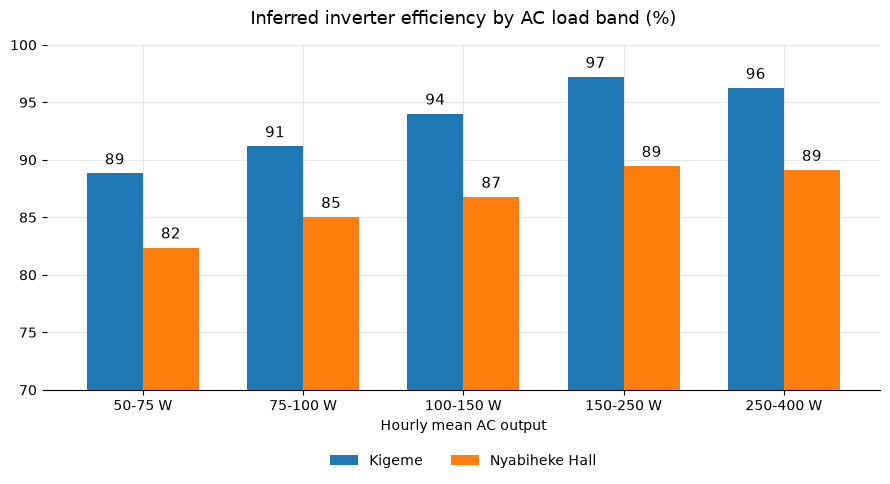

Kigeme


,hours,efficiency,share of AC energy
band,,,
0-25 W,3,0.40,0.00
25-50 W,7,0.80,0.00
50-75 W,257,0.89,0.02
75-100 W,1650,0.91,0.15
100-150 W,786,0.94,0.09
150-250 W,1172,0.97,0.26
250-400 W,1507,0.96,0.48
400-800 W,0,NaN,0.00
800-5000 W,0,NaN,0.00


Nyabiheke Hall


,hours,efficiency,share of AC energy
band,,,
0-25 W,1,0.51,0.00
25-50 W,1754,0.76,0.12
50-75 W,2410,0.82,0.23
75-100 W,334,0.85,0.05
100-150 W,709,0.87,0.14
150-250 W,577,0.89,0.18
250-400 W,161,0.89,0.09
400-800 W,159,0.90,0.15
800-5000 W,30,0.90,0.05


,Kigeme,Nyabiheke Hall
efficiency below 100 W,0.91,0.81
efficiency above 250 W,0.96,0.89
share of AC energy below 100 W,0.17,0.40


In [8]:
bands = [0, 25, 50, 75, 100, 150, 250, 400, 800, 5000]
labels = [f"{a}-{b} W" for a, b in zip(bands[:-1], bands[1:])]
BANDS, LIGHT = {}, {}

for n in NAMES:
    h = HOURLY[n].dropna(subset=["ac", "inv"])
    h = h[h["inv"] > 5].copy()
    h["band"] = pd.cut(h["ac"], bands, labels=labels)
    g = h.groupby("band", observed=False)
    BANDS[n] = pd.DataFrame({"hours": g.size(), "efficiency": g["ac"].sum() / g["inv"].sum(),
                             "share of AC energy": g["ac"].sum() / h["ac"].sum()})
    lo, hi = h[h["ac"] < 100], h[h["ac"] >= 250]
    LIGHT[n] = {"efficiency below 100 W": lo["ac"].sum() / lo["inv"].sum(),
                "efficiency above 250 W": hi["ac"].sum() / hi["inv"].sum() if len(hi) else np.nan,
                "share of AC energy below 100 W": lo["ac"].sum() / h["ac"].sum()}
LIGHT = pd.DataFrame(LIGHT)

eff = pd.DataFrame({n: 100 * BANDS[n]["efficiency"].where(BANDS[n]["hours"] >= 20) for n in NAMES}).dropna()

fig, ax = plt.subplots(figsize=(9, 5))
eff.plot.bar(ax=ax, color=[SITES[n]["color"] for n in NAMES], width=0.7, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", padding=4, fontsize=11)

ax.set(ylim=(70, 100), xlabel="Hourly mean AC output", ylabel="")
ax.set_title("Inferred inverter efficiency by AC load band (%)", pad=15, fontsize=13)
ax.set_axisbelow(True); ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=len(NAMES), frameon=False)

show_fig("03_inverter_by_load")
for n in NAMES:
    print(n); display(BANDS[n])
display(LIGHT)

### 3.2 Cross-check against the battery energy counters
For days with at least 3 counter readings, the counter range is compared with integrated charge and discharge energy.

In [9]:
def counter_check(d, day):
    g = d.groupby(d["time"].dt.normalize())
    out = {}
    for col, ref in [("e_dis", "Dis"), ("e_chg", "Chg")]:
        a = g[col].agg(["max", "min", "count"])
        counter = (a["max"] - a["min"]).where(a["count"] >= 3)
        j = pd.concat([counter.rename("counter"), day[ref].rename("integrated"), day["complete"]], axis=1).dropna()
        j = j[j["complete"].astype(bool) & (j["integrated"] > 0.05)]
        ratio = j["counter"] / j["integrated"]
        out[ref] = {"days compared": len(j), "median counter / integrated": ratio.median(), "10th pct": ratio.quantile(0.1), "90th pct": ratio.quantile(0.9)}
    return pd.DataFrame(out)

for n in NAMES:
    print(n); display(counter_check(DF[n], DAILY[n]))

Kigeme


,Dis,Chg
days compared,225.00,230.00
median counter / integrated,1.00,1.00
10th pct,0.99,0.99
90th pct,1.00,1.01


Nyabiheke Hall


,Dis,Chg
days compared,256.00,256.00
median counter / integrated,0.99,0.98
10th pct,0.87,0.94
90th pct,1.14,1.03


**Findings (Q1).** Integrated energy matches the counters: median ratio 0.995 at Kigeme (10th to 90th percentile 0.99 to 1.01) and 0.98 to 0.99 at the Hall, with wider daily scatter (0.87 to 1.14 for discharge) from the 15-minute step. The controller converts about 97% of PV at both sites. The inverters differ: Kigeme 95%, Hall 85% (both inferred). About 40% of Hall AC energy is delivered below 100 W, where inverters are weak, but above 250 W the Hall is still 89% against 96%, so light load explains part of the gap, not all. Remaining candidates are the inverter model (Hall unit 48/3000 against a 24/3000 reference curve), DC-side offsets in the inferred input, or a real loss. A clamp meter at the DC terminals would settle it.

## 4. When the system generates, consumes and stores (Q1, Q2)

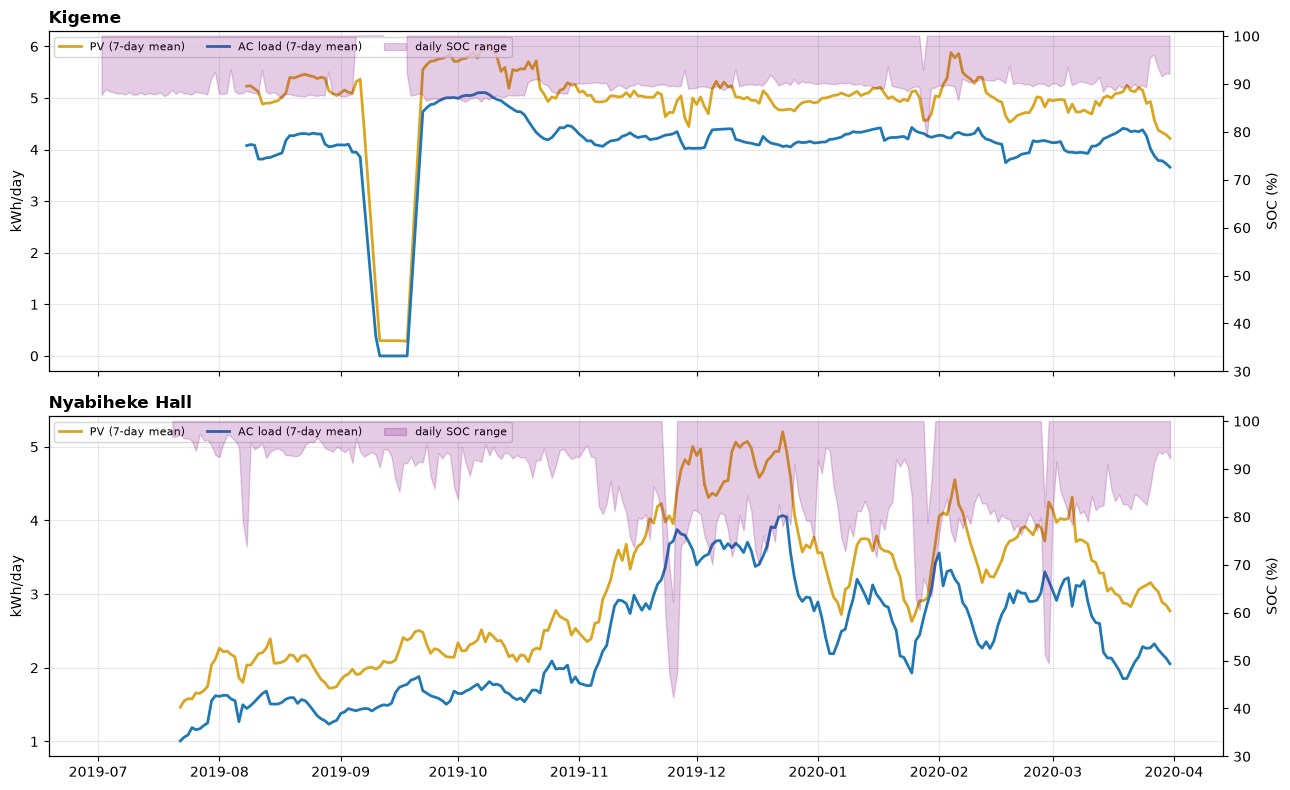

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, n in zip(axes, NAMES):
    d = DAILY[n]
    dd = d.where(d["complete"])
    ax.plot(dd.index, dd["PV"].rolling(7, min_periods=3).mean(), color="goldenrod", lw=2, label="PV (7-day mean)")
    ax.plot(dd.index, dd["AC"].rolling(7, min_periods=3).mean(), color="tab:blue", lw=2, label="AC load (7-day mean)")
    ax.set_ylabel("kWh/day"); ax.set_title(n, loc="left", fontweight="bold")
    a2 = ax.twinx()
    a2.fill_between(d.index, d["soc_min"], d["soc_max"], color="purple", alpha=0.2, label="daily SOC range")
    a2.set_ylim(30, 101); a2.set_ylabel("SOC (%)"); a2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, fontsize=8)
show_fig("04_daily_series")

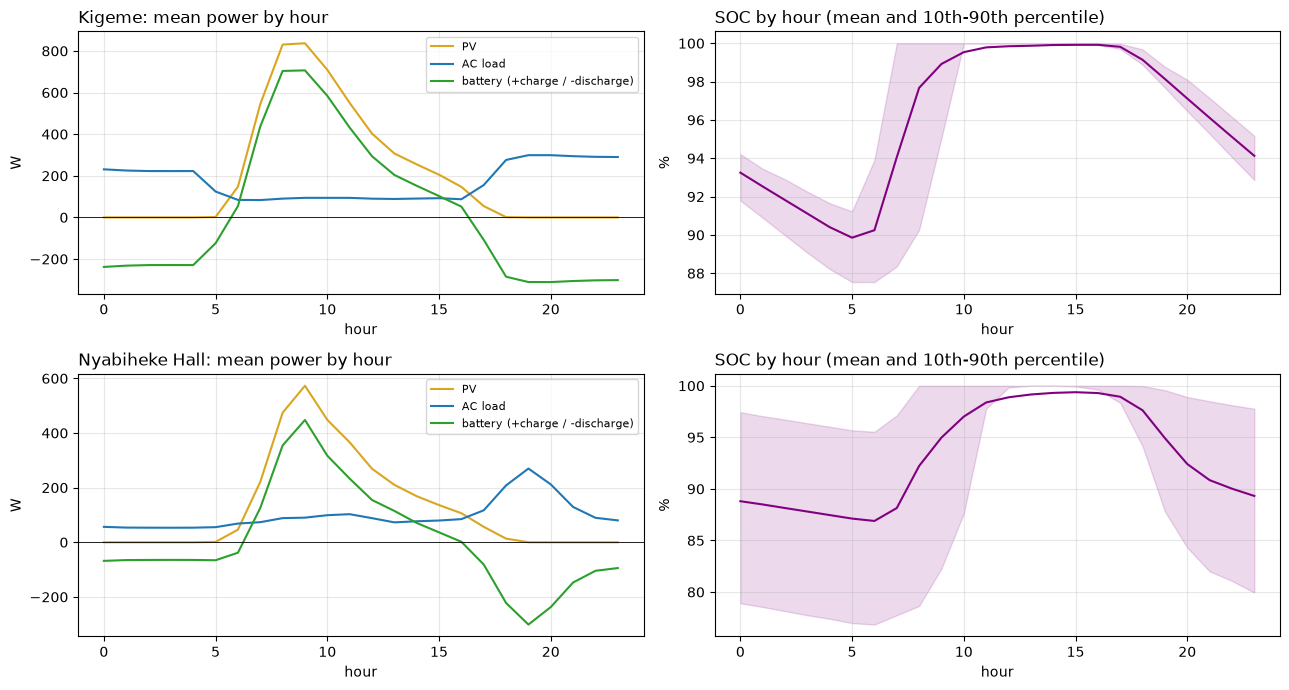

,Kigeme,Nyabiheke Hall
share of AC energy at night (18-06),0.72,0.56
share of AC energy 18-22,0.28,0.35
share of inverter input from battery,0.75,0.63
evening peak hour,20.00,19.00
evening peak W,299.06,269.89
PV peak hour,9.00,9.00
PV peak W,836.89,572.98


In [11]:
def by_hour(h, col):
    g = h.groupby("hour")[col]
    return pd.DataFrame({"mean": g.mean(), "p10": g.quantile(0.1), "p90": g.quantile(0.9)})

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
FACTS = {}
for r, n in enumerate(NAMES):
    h = HOURLY[n]
    pv, ac, pb, soc = by_hour(h, "pv"), by_hour(h, "ac"), by_hour(h, "pb"), by_hour(h, "soc")
    a = axes[r, 0]
    a.plot(pv["mean"], color="goldenrod", label="PV"); a.plot(ac["mean"], color="tab:blue", label="AC load")
    a.plot(pb["mean"], color="tab:green", label="battery (+charge / -discharge)"); a.axhline(0, color="k", lw=0.6)
    a.set_title(f"{n}: mean power by hour", loc="left"); a.set_xlabel("hour"); a.set_ylabel("W"); a.legend(fontsize=8)
    a = axes[r, 1]
    a.plot(soc["mean"], color="purple"); a.fill_between(soc.index, soc["p10"], soc["p90"], color="purple", alpha=0.15)
    a.set_title("SOC by hour (mean and 10th-90th percentile)", loc="left"); a.set_xlabel("hour"); a.set_ylabel("%")
    iv = IV[n][IV[n]["ok"]]
    night = iv[(iv["hour"] >= 18) | (iv["hour"] < 6)]
    FACTS[n] = {"share of AC energy at night (18-06)": night["E_ac"].sum() / iv["E_ac"].sum(),
                "share of AC energy 18-22": iv[(iv["hour"] >= 18) & (iv["hour"] < 22)]["E_ac"].sum() / iv["E_ac"].sum(),
                "share of inverter input from battery": min(iv["E_dis"].sum() / iv["E_inv"].sum(), 1),
                "evening peak hour": int(ac["mean"].idxmax()), "evening peak W": ac["mean"].max(),
                "PV peak hour": int(pv["mean"].idxmax()), "PV peak W": pv["mean"].max()}
show_fig("04_hourly_profiles")
FACTS = pd.DataFrame(FACTS)
display(FACTS)
save(FACTS, "04_profile_facts")

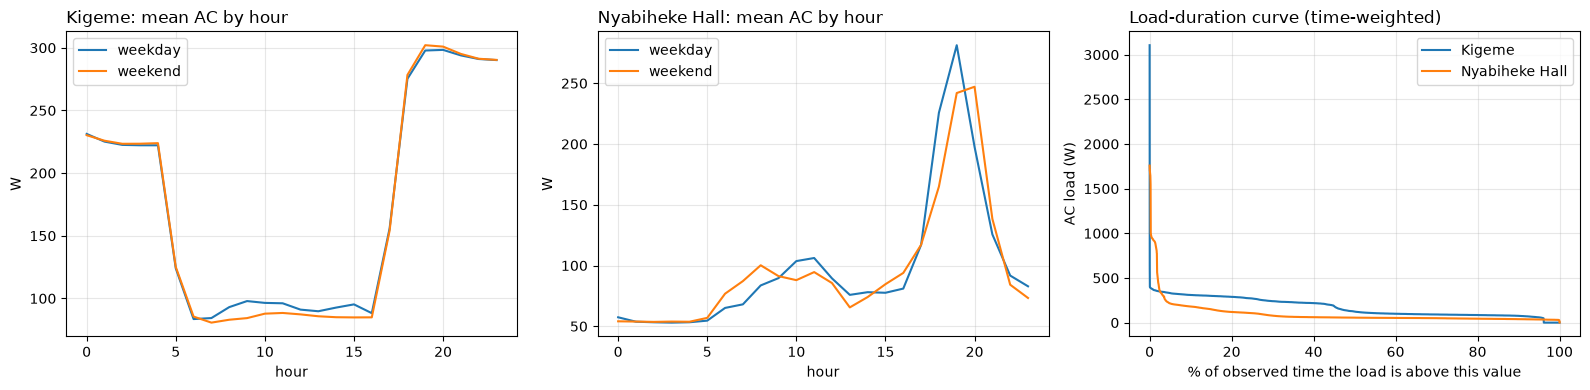

,Kigeme,Nyabiheke Hall
weekday kWh/day,4.19,2.36
weekend kWh/day,4.10,2.34
weekday 18-21 mean W,291.34,207.59
weekend 18-21 mean W,294.10,198.10


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
WEEK = {}
for i, n in enumerate(NAMES):
    h = HOURLY[n]
    wd = h[h["dow"] < 5].groupby("hour")["ac"].mean()
    we = h[h["dow"] >= 5].groupby("hour")["ac"].mean()
    axes[i].plot(wd, label="weekday"); axes[i].plot(we, label="weekend")
    axes[i].set_title(f"{n}: mean AC by hour", loc="left"); axes[i].set_xlabel("hour"); axes[i].set_ylabel("W"); axes[i].legend()
    day = DAILY[n][DAILY[n]["complete"]]
    WEEK[n] = {"weekday kWh/day": day[day.index.dayofweek < 5]["AC"].mean(), "weekend kWh/day": day[day.index.dayofweek >= 5]["AC"].mean(),
               "weekday 18-21 mean W": wd.loc[18:21].mean(), "weekend 18-21 mean W": we.loc[18:21].mean()}
    x = IV[n][IV[n]["ok"]].sort_values("ac", ascending=False)
    axes[2].plot(x["dt_h"].cumsum() / x["dt_h"].sum() * 100, x["ac"], label=n, color=SITES[n]["color"])
axes[2].set_xlabel("% of observed time the load is above this value"); axes[2].set_ylabel("AC load (W)")
axes[2].set_title("Load-duration curve (time-weighted)", loc="left"); axes[2].legend()
show_fig("04_weekday_ldc")
display(pd.DataFrame(WEEK))

**Findings.** PV peaks around 09:00 (the array is assumed north-facing at a shallow tilt) and load peaks in the evening (20:00 at Kigeme, 19:00 at the Hall). The battery is the main source after dark: about three quarters of the Kigeme inverter input and about 60% at the Hall come from the battery. Weekdays and weekends are almost identical, which fits street lights and standing meter loads more than activity-driven demand.

## 5. Battery use (Q1, Q2)
- Share of time at each SOC level, and at 99% or more (float, where the controller throttles PV).
- Daily swing and equivalent full cycles per day.
- **Apparent capacity:** at night PV is zero, so energy drawn divided by the SOC drop gives $C_{eff}=E_{dis}/\Delta SOC$.
- Cycle-life bracket: the GEL datasheet gives 375 to 540 full-cycle equivalents.

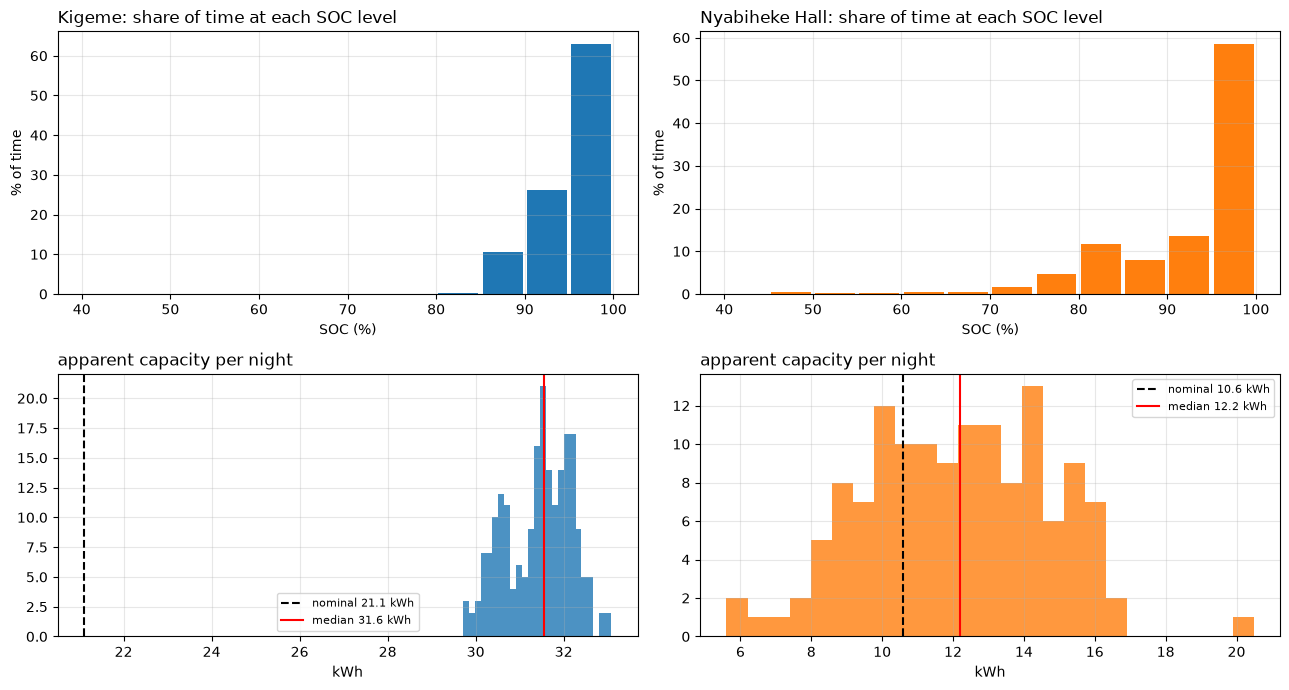

,Kigeme,Nyabiheke Hall
time at SOC >= 99 %,0.47,0.40
lowest SOC (%),78.80,42.30
median daily SOC swing (pts),10.50,14.35
95th pct daily swing (pts),13.10,27.20
full cycles per day,0.16,0.16
discharge kWh/year,"1,204.90",631.65
"apparent capacity, median kWh",31.55,12.21
apparent / nominal,1.50,1.15
nights used for capacity,212.00,135.00
"throughput life, low (years)",6.57,6.29


In [13]:
def nightly(iv):
    x = iv[iv["gap_ok"] & ((iv["hour"] >= 18) | (iv["hour"] < 6))].copy()
    x["night"] = (x["mid"] - pd.Timedelta(hours=18)).dt.normalize()
    g = x.groupby("night")
    n = pd.DataFrame({"cov_h": g["dt_h"].sum(), "dis_kWh": g["E_dis"].sum() / 1000, "chg_kWh": g["E_chg"].sum() / 1000,
                      "ac_W": g["ac"].mean(), "soc_start": g["soc0"].first(), "soc_end": g["soc1"].last()})
    n = n[n["cov_h"] >= 10.8].copy()
    n["soc_drop"] = n["soc_start"] - n["soc_end"]
    n["C_eff"] = np.where(n["soc_drop"] >= 8, (n["dis_kWh"] - n["chg_kWh"]) / (n["soc_drop"] / 100), np.nan)
    return n

NIGHT = {n: nightly(IV[n]) for n in NAMES}
BATT = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for j, n in enumerate(NAMES):
    cfg = SITES[n]
    x = IV[n][IV[n]["gap_ok"] & IV[n]["soc_mid"].notna()]
    day = DAILY[n][DAILY[n]["complete"]]
    ce = NIGHT[n]["C_eff"].dropna()
    bins = np.arange(40, 101, 5)
    w, _ = np.histogram(x["soc_mid"], bins=bins, weights=x["dt_h"])
    axes[0, j].bar(bins[:-1] + 2.5, w / w.sum() * 100, width=4.5, color=cfg["color"])
    axes[0, j].set_title(f"{n}: share of time at each SOC level", loc="left"); axes[0, j].set_xlabel("SOC (%)"); axes[0, j].set_ylabel("% of time")
    axes[1, j].hist(ce, bins=25, color=cfg["color"], alpha=0.8)
    axes[1, j].axvline(cfg["batt_kwh"], color="k", ls="--", label=f"nominal {cfg['batt_kwh']} kWh")
    if len(ce):
        axes[1, j].axvline(ce.median(), color="r", label=f"median {ce.median():.1f} kWh")
    axes[1, j].set_title("apparent capacity per night", loc="left"); axes[1, j].set_xlabel("kWh"); axes[1, j].legend(fontsize=8)
    annual = day["Dis"].mean() * 365
    BATT[n] = {"time at SOC >= 99 %": x.loc[x["soc_mid"] >= 99, "dt_h"].sum() / x["dt_h"].sum(),
               "lowest SOC (%)": DF[n]["soc"].min(),
               "median daily SOC swing (pts)": (day["soc_max"] - day["soc_min"]).median(),
               "95th pct daily swing (pts)": (day["soc_max"] - day["soc_min"]).quantile(0.95),
               "full cycles per day": day["Dis"].mean() / cfg["batt_kwh"],
               "discharge kWh/year": annual,
               "apparent capacity, median kWh": ce.median() if len(ce) else np.nan,
               "apparent / nominal": ce.median() / cfg["batt_kwh"] if len(ce) else np.nan,
               "nights used for capacity": len(ce),
               "throughput life, low (years)": GEL_FULL_CYCLES[0] * cfg["batt_kwh"] / annual,
               "throughput life, high (years)": GEL_FULL_CYCLES[1] * cfg["batt_kwh"] / annual}
show_fig("05_battery_use")
BATT = pd.DataFrame(BATT)
display(BATT)
save(BATT, "05_battery")

In [14]:
for n in NAMES:
    nt = NIGHT[n].copy()
    nt["month"] = nt.index.to_period("M")
    t = nt.groupby("month").agg(nights=("soc_end", "size"), median_end_SOC=("soc_end", "median"),
                                 pct_below_85=("soc_end", lambda x: 100 * (x < 85).mean()),
                                 pct_below_75=("soc_end", lambda x: 100 * (x < 75).mean()))
    print(n); display(t); save(t, f"05_nights_{n.split()[0]}")

Kigeme


,nights,median_end_SOC,pct_below_85,pct_below_75
month,,,,
2019-08,27,87.80,0.00,0.00
2019-09,24,87.70,0.00,0.00
2019-10,31,87.60,0.00,0.00
2019-11,30,89.75,0.00,0.00
2019-12,31,89.90,0.00,0.00
2020-01,31,89.60,3.23,0.00
2020-02,29,90.10,0.00,0.00
2020-03,30,89.90,0.00,0.00


Nyabiheke Hall


,nights,median_end_SOC,pct_below_85,pct_below_75
month,,,,
2019-07,12,96.75,0.00,0.00
2019-08,31,94.90,3.23,3.23
2019-09,30,93.75,3.33,0.00
2019-10,31,92.70,0.00,0.00
2019-11,30,82.85,60.00,16.67
2019-12,30,80.10,83.33,16.67
2020-01,31,82.40,64.52,19.35
2020-02,29,80.50,93.10,6.90
2020-03,30,84.85,50.00,0.00


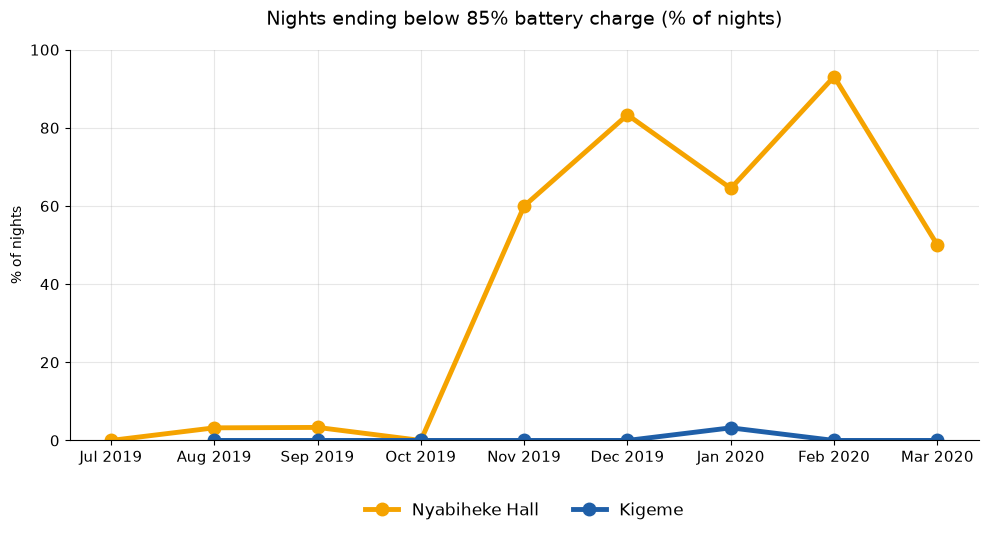

In [15]:
BLUE, AMBER = "#1F5FA8", "#F5A300"
pct85 = {n: NIGHT[n].groupby(NIGHT[n].index.to_period("M"))["soc_end"].apply(lambda s: 100 * (s < 85).mean()) for n in NAMES}
months = sorted(set(pct85[NAMES[0]].index) | set(pct85[NAMES[1]].index))
fig, ax = plt.subplots(figsize=(10, 5.5))
for n, col in zip(["Nyabiheke Hall", "Kigeme"], [AMBER, BLUE]):
    s = pct85[n].reindex(months)
    ax.plot([m.strftime("%b %Y") for m in months], s.values, "o-", color=col, lw=3.5, ms=9, label=n)
ax.set_ylim(0, 100); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel("% of nights")
ax.tick_params(labelsize=11)
ax.set_title("Nights ending below 85% battery charge (% of nights)", pad=18, fontsize=14)
ax.set_axisbelow(True); ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=12)
show_fig("slide_hall_nights_below_85")

**Findings.** Kigeme never falls below 78.8% and uses a small slice of a large battery. The Hall is the stressed one: it reaches 42.3% at its lowest, and from November to February 60 to 93% of nights end below 85%, against almost none from July to October.

Apparent capacity comes out **above** nominal at both sites (Kigeme 31.6 kWh, 1.5x the 21.1 kWh nameplate; Hall 1.15x). A real battery cannot do this, so the SOC estimate or the monitor's capacity setting is off (the Kigeme nameplate itself reads 21.1 kWh in the case table and 19.2 kWh on the datasheet). A stable apparent capacity shows the monitor is consistent, not that the battery is healthy, and nine months is too short to see lead-acid ageing. Reported SOC is therefore treated as plus or minus 10 points.

## 6. PV potential, calibration and unused solar (Q1, Q3)
Both arrays are large compared with the load. Once the battery is full the controller cuts PV to what the load needs, so measured PV can sit far below what the array could produce, and a raw comparison with PVGIS would mostly measure this throttling.

Steps: (1) PVGIS hourly output (10 degree tilt, north-facing, 0% extra loss; cached in `pvgis_cache/`); (2) clock-alignment test; (3) fit a multiplier *k* on **un-throttled** hours only (battery below 95%, net charging above 50 W, almost no discharge, model at least 100 W); (4) cross-validate by date and bootstrap over dates; (5) unused PV = calibrated potential minus measured PV in hours when the battery is full.

In [16]:
PVGIS_URL = "https://re.jrc.ec.europa.eu/api/v5_3/seriescalc"
CACHE = Path("pvgis_cache")
CACHE.mkdir(exist_ok=True)

def get_pvgis(name, cfg, y0, y1):
    f = CACHE / (name.replace(" ", "_") + ".json")
    if f.exists():
        js = json.load(open(f))
    else:
        import requests
        pars = {"lat": cfg["lat"], "lon": cfg["lon"], "startyear": y0, "endyear": y1, "pvcalculation": 1,
                "peakpower": cfg["kwp"], "pvtechchoice": "crystSi", "mountingplace": "free", "loss": 0,
                "trackingtype": 0, "angle": 10, "aspect": 180, "usehorizon": 1,
                "raddatabase": "PVGIS-SARAH3", "localtime": 1, "outputformat": "json"}
        r = requests.get(PVGIS_URL, params=pars, timeout=120)
        r.raise_for_status()
        js = r.json()
        json.dump(js, open(f, "w"))
    d = pd.DataFrame(js["outputs"]["hourly"])
    t = pd.to_datetime(d["time"].astype(str), format="%Y%m%d:%H%M")
    s = pd.Series(pd.to_numeric(d["P"], errors="coerce").values, index=pd.DatetimeIndex(t).floor("h"))
    return s[~s.index.duplicated()].sort_index()

PVG = {}
for n in NAMES:
    try:
        y0, y1 = int(DF[n]["time"].dt.year.min()), int(DF[n]["time"].dt.year.max())
        PVG[n] = get_pvgis(n, SITES[n], y0, y1)
        print(f"PVGIS OK for {n}: {len(PVG[n]):,} hourly values")
    except Exception as e:
        PVG[n] = None
        print(f"PVGIS not available for {n} ({type(e).__name__}) -> an empirical envelope will be used instead (a lower bound)")

PVGIS OK for Kigeme: 17,544 hourly values
PVGIS OK for Nyabiheke Hall: 17,544 hourly values


In [17]:
def uncurtailed(h):
    return (h["soc_max"] < 95) & (h["pb"] > 50) & (h["E_dis"] <= 10)

def fit_k(measured, model):
    return float((measured * model).sum() / (model * model).sum())

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

rng = np.random.default_rng(42)
POT, KFIT, LAGS, METHOD = {}, {}, {}, {}
for n in NAMES:
    h = HOURLY[n]
    full = pd.date_range(h.index.min().normalize(), h.index.max().ceil("h"), freq="h")
    pvg = PVG[n]
    if pvg is not None:
        base = h[uncurtailed(h) & h["hour"].between(6, 17)]
        rows = []
        for lag in [-2, -1, 0, 1, 2]:
            s = pvg.shift(lag, freq="h").reindex(base.index)
            ok = s.notna()
            r = np.corrcoef(base.loc[ok, "pv"], s[ok])[0, 1] if ok.sum() > 10 else np.nan
            rows.append((lag, r, int(ok.sum())))
        LAGS[n] = pd.DataFrame(rows, columns=["shift (h)", "correlation", "hours"]).set_index("shift (h)")
        lag = int(LAGS[n]["correlation"].idxmax())
        shifted = pvg.shift(lag, freq="h")
        h["pvgis"] = shifted.reindex(h.index)
        sel = h[uncurtailed(h) & (h["pvgis"] >= 100)].dropna(subset=["pv", "pvgis"])
        if len(sel) >= 30:
            k = fit_k(sel["pv"], sel["pvgis"])
            dates = np.array(sorted(sel["date"].unique()))
            fold = dict(zip(dates, rng.integers(0, 5, len(dates))))
            sel = sel.assign(fold=sel["date"].map(fold))
            before, after = [], []
            for f in range(5):
                train, test = sel[sel["fold"] != f], sel[sel["fold"] == f]
                if len(train) == 0 or len(test) == 0:
                    continue
                kf = fit_k(train["pv"], train["pvgis"])
                before.append((test["pv"] - test["pvgis"]) ** 2)
                after.append((test["pv"] - kf * test["pvgis"]) ** 2)
            boots = []
            for _ in range(200):
                pick = rng.choice(dates, len(dates))
                b = sel[sel["date"].isin(pick)]
                boots.append(fit_k(b["pv"], b["pvgis"]))
            morning, later = sel[sel["hour"] <= 10], sel[sel["hour"] >= 11]
            loose = h[(h["soc_max"] < 95) & (h["pvgis"] >= 100) & (h["hour"] >= 11)].dropna(subset=["pv", "pvgis"])
            KFIT[n] = {"clock shift (h)": lag, "k": k, "k 95% low": np.percentile(boots, 2.5), "k 95% high": np.percentile(boots, 97.5),
                       "hours used": len(sel), "days used": len(dates),
                       "RMSE before (W)": np.sqrt(pd.concat(before).mean()), "RMSE after, cross-validated (W)": np.sqrt(pd.concat(after).mean()),
                       "k morning only": fit_k(morning["pv"], morning["pvgis"]) if len(morning) > 5 else np.nan, "morning hours": len(morning),
                       "k hour>=11 (selected)": fit_k(later["pv"], later["pvgis"]) if len(later) > 5 else np.nan, "hours>=11": len(later),
                       "k hour>=11 (battery not full)": fit_k(loose["pv"], loose["pvgis"]) if len(loose) > 5 else np.nan, "loose hours>=11": len(loose)}
            h["selected"] = False
            h.loc[sel.index, "selected"] = True
            POT[n] = (k * shifted.reindex(full)).fillna(0).clip(lower=0)
            METHOD[n] = "PVGIS x k"
    if n not in POT:
        m = h[uncurtailed(h)]
        env = m.groupby("hour")["pv"].quantile(0.9)
        POT[n] = pd.Series(env.reindex(full.hour).fillna(0).values, index=full)
        METHOD[n] = "empirical envelope (lower bound)"
    print(n, "-> potential method:", METHOD[n])

for n, t in LAGS.items():
    print(f"\nClock alignment test, {n}"); display(t)
KF = pd.DataFrame(KFIT)
display(KF)
if len(KF):
    save(KF, "06_pv_calibration")

Kigeme -> potential method: PVGIS x k
Nyabiheke Hall -> potential method: PVGIS x k

Clock alignment test, Kigeme


,correlation,hours
shift (h),,
-2,0.11,121
-1,0.26,121
0,0.51,121
1,0.79,121
2,0.61,121



Clock alignment test, Nyabiheke Hall


,correlation,hours
shift (h),,
-2,0.10,274
-1,0.31,274
0,0.58,274
1,0.88,274
2,0.82,274


,Kigeme,Nyabiheke Hall
clock shift (h),1.00,1.00
k,0.71,0.69
k 95% low,0.66,0.68
k 95% high,0.76,0.71
hours used,120.00,273.00
days used,81.00,108.00
RMSE before (W),218.14,309.89
"RMSE after, cross-validated (W)",151.59,155.90
k morning only,0.71,0.69
morning hours,114.00,237.00


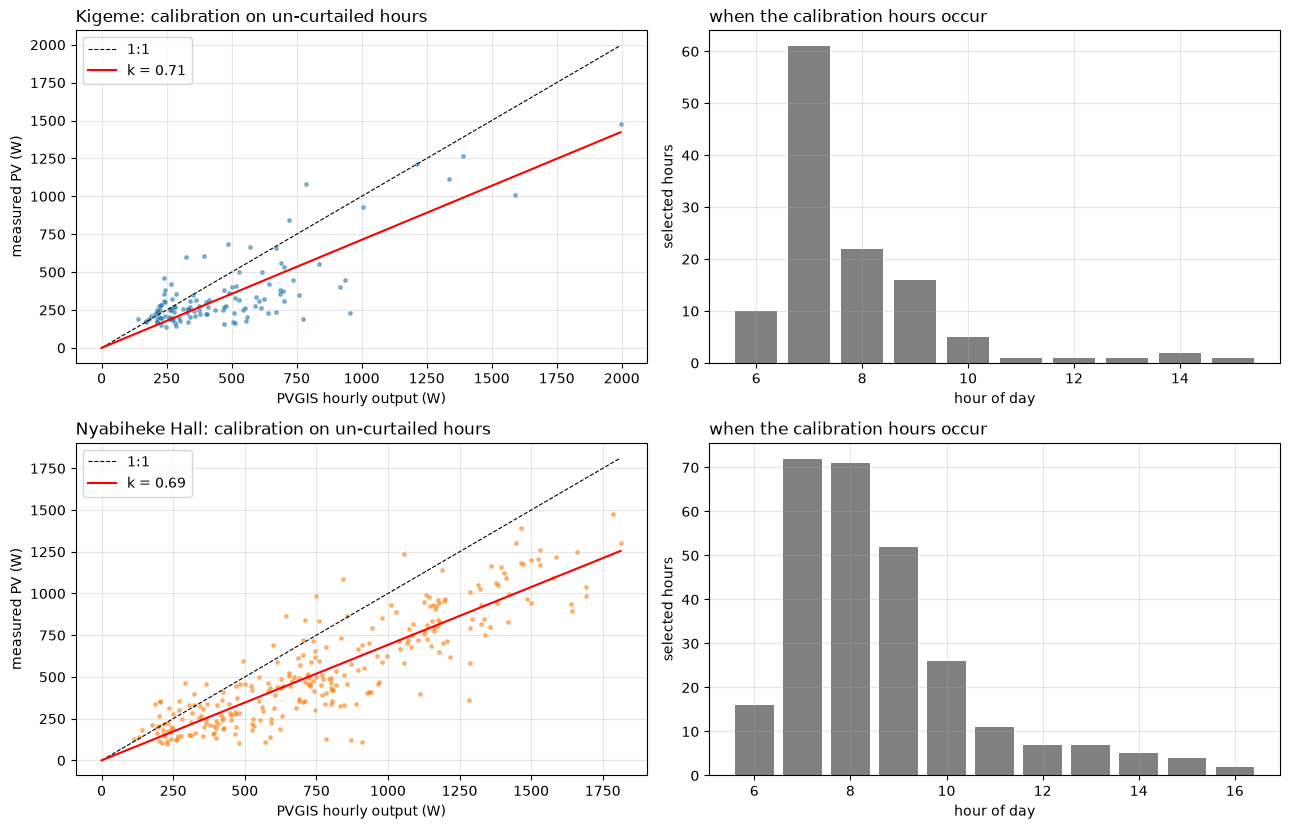

In [18]:
if KFIT:
    fig, axes = plt.subplots(len(KFIT), 2, figsize=(13, 4.2 * len(KFIT)), squeeze=False)
    for r, n in enumerate(KFIT):
        h = HOURLY[n]; s = h[h["selected"]]; k = KFIT[n]["k"]
        a = axes[r, 0]
        a.scatter(s["pvgis"], s["pv"], s=6, alpha=0.5, color=SITES[n]["color"])
        top = max(s["pvgis"].max(), s["pv"].max())
        a.plot([0, top], [0, top], "k--", lw=0.8, label="1:1")
        a.plot([0, top], [0, k * top], "r", label=f"k = {k:.2f}")
        a.set_xlabel("PVGIS hourly output (W)"); a.set_ylabel("measured PV (W)"); a.set_title(f"{n}: calibration on un-curtailed hours", loc="left"); a.legend()
        c = s.groupby("hour").size()
        axes[r, 1].bar(c.index, c.values, color="grey")
        axes[r, 1].set_xlabel("hour of day"); axes[r, 1].set_ylabel("selected hours"); axes[r, 1].set_title("when the calibration hours occur", loc="left")
    show_fig("06_calibration")

**Findings (calibration).** With a +1 h clock shift (r = 0.79 and 0.88), measured PV is about 70% of PVGIS at both sites: k = 0.71 (0.66 to 0.76) at Kigeme and 0.69 (0.68 to 0.71) at the Hall. Cross-validated RMSE falls from 218 to 152 W (Kigeme) and 310 to 156 W (Hall). The same factor at two sites points to a shared modelling cause (assumed geometry, no shading or soiling data) rather than two failing arrays, but soiling, shading and ageing cannot be excluded without a site survey. Calibration hours are mostly before 10:00; the Hall has 36 later hours and k holds there, while Kigeme has only 6, so midday potential at Kigeme is an extrapolation.

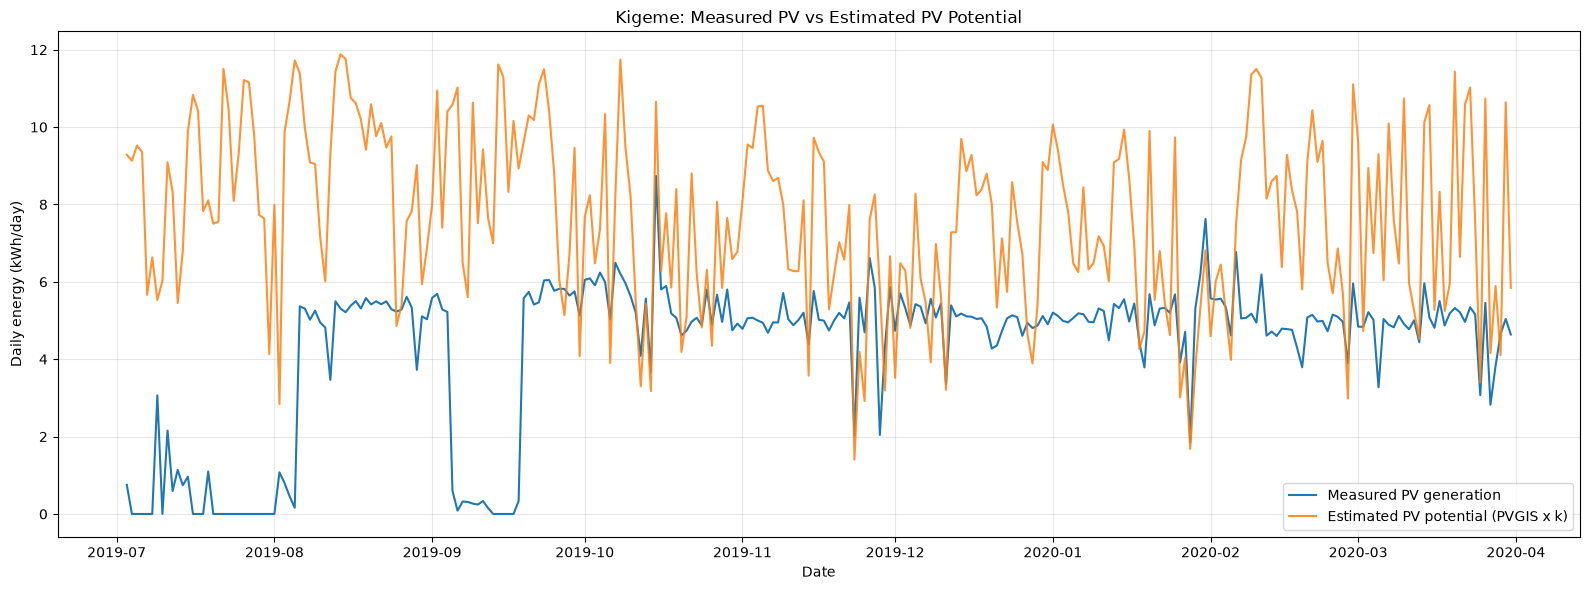


Kigeme
Mean measured PV: 4.27 kWh/day
Mean estimated potential: 7.67 kWh/day
Estimation method: PVGIS x k


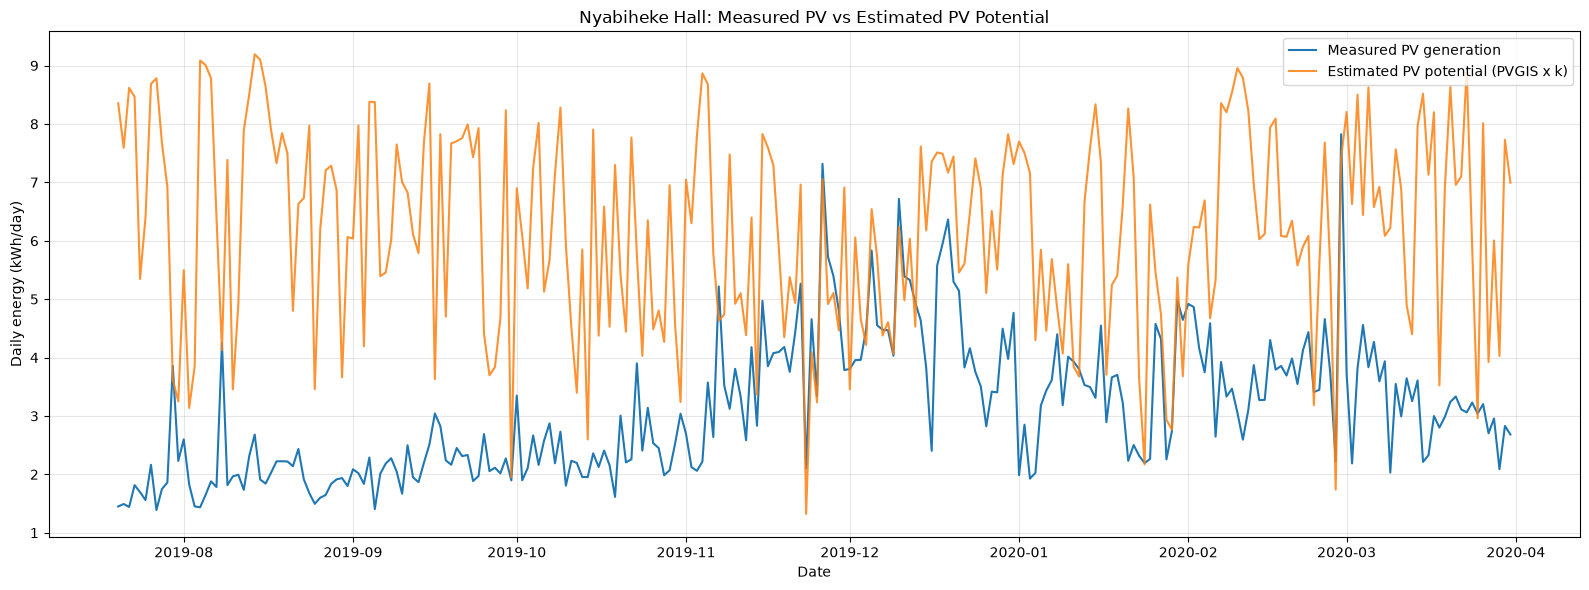


Nyabiheke Hall
Mean measured PV: 3.09 kWh/day
Mean estimated potential: 6.17 kWh/day
Estimation method: PVGIS x k


In [19]:
for n in NAMES:
    h = HOURLY[n].copy()

    measured_daily = h["pv"].resample("D").sum() / 1000

    potential_daily = POT[n].resample("D").sum() / 1000

    fig, ax = plt.subplots(figsize=(16, 6))

    ax.plot(
        measured_daily.index,
        measured_daily,
        label="Measured PV generation",
        linewidth=1.5
    )

    ax.plot(
        potential_daily.index,
        potential_daily,
        label=f"Estimated PV potential ({METHOD[n]})",
        linewidth=1.5,
        alpha=0.85
    )

    ax.set_title(f"{n}: Measured PV vs Estimated PV Potential")
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily energy (kWh/day)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()

    print(f"\n{n}")
    print(f"Mean measured PV: {measured_daily.mean():.2f} kWh/day")
    print(f"Mean estimated potential: {potential_daily.mean():.2f} kWh/day")
    print(f"Estimation method: {METHOD[n]}")

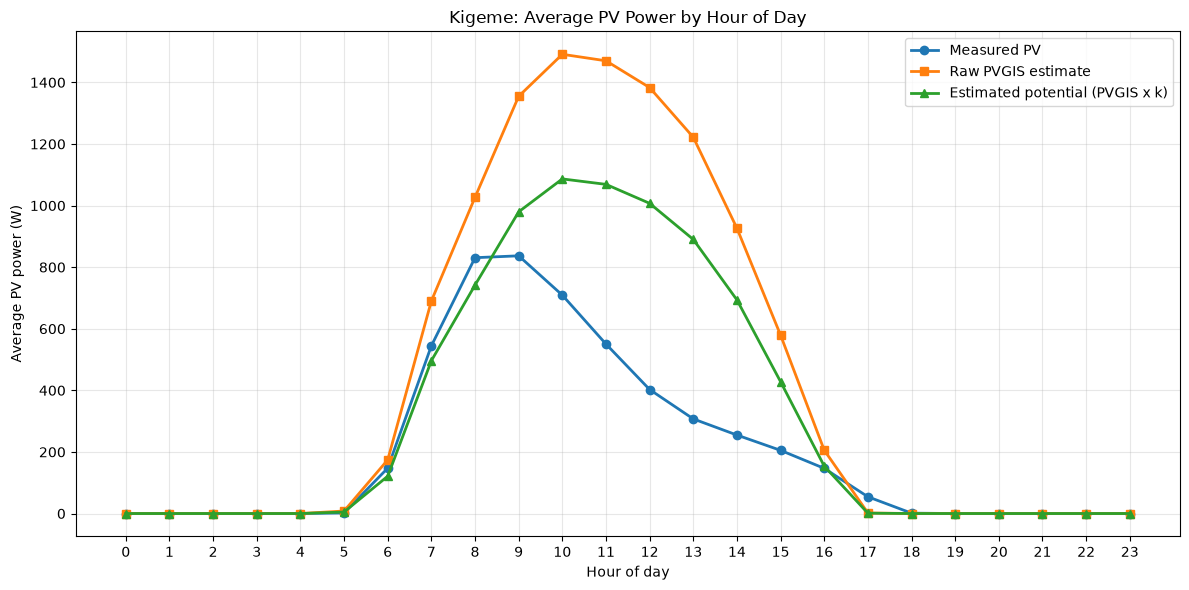

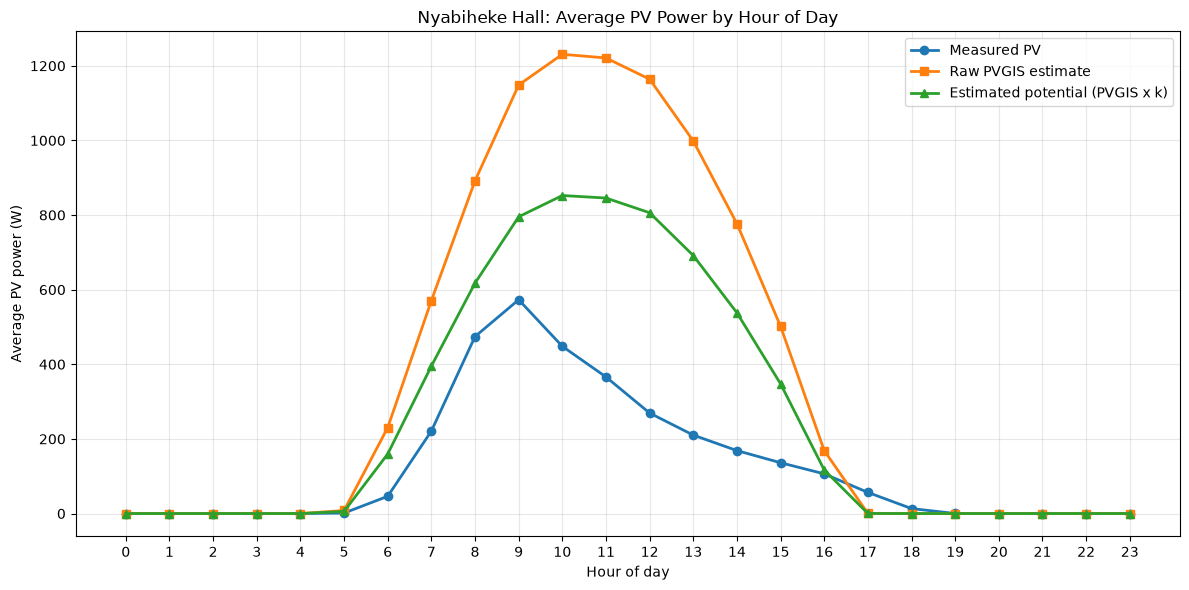

In [20]:
for n in NAMES:
    h = HOURLY[n].copy()

    measured_hourly = h.groupby("hour")["pv"].mean()

    potential_hourly = POT[n].groupby(POT[n].index.hour).mean()

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        measured_hourly.index,
        measured_hourly.values,
        marker="o",
        linewidth=2,
        label="Measured PV"
    )

    if "pvgis" in h.columns:
        pvgis_hourly = h.groupby("hour")["pvgis"].mean()

        ax.plot(
            pvgis_hourly.index,
            pvgis_hourly.values,
            marker="s",
            linewidth=2,
            label="Raw PVGIS estimate"
        )

    ax.plot(
        potential_hourly.index,
        potential_hourly.values,
        marker="^",
        linewidth=2,
        label=f"Estimated potential ({METHOD[n]})"
    )

    ax.set_title(f"{n}: Average PV Power by Hour of Day")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Average PV power (W)")
    ax.set_xticks(range(24))
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()

### 6.1 Unused solar and where the PV energy goes

In [21]:
CURT = {}
for n in NAMES:
    h = HOURLY[n]
    h["pot"] = POT[n].reindex(h.index).values
    full = h["soc_max"] >= 98
    h["pv_Wh"] = h["pv"] * h["cov_h"]
    h["pot_Wh"] = h["pot"] * h["cov_h"]
    h["unused_Wh"] = np.where(full, (h["pot"] - h["pv"]).clip(lower=0) * h["cov_h"], 0.0)
    comp = h["date"].map(DAILY[n]["complete"]).fillna(False).astype(bool)
    m = h[comp].groupby("month")[["pv_Wh", "pot_Wh", "unused_Wh"]].sum() / 1000
    m.columns = ["measured kWh", "potential kWh", "unused kWh (battery full)"]
    m.index = m.index.astype(str)
    m.loc["TOTAL"] = m.sum()
    m["unused % of potential"] = 100 * m["unused kWh (battery full)"] / m["potential kWh"]
    CURT[n] = m
    print(f"\n{n}: PV potential vs measured, complete days ({METHOD[n]})")
    display(m)
    save(m, f"06_unused_pv_{n.split()[0]}")

DEMAND = {}
for n in NAMES:
    if PVG[n] is None:
        continue
    pvd = (PVG[n].groupby(PVG[n].index.normalize()).sum() / 1000).rename("pvgis")
    d = DAILY[n][DAILY[n]["complete"]].join(pvd, how="inner")
    DEMAND[n] = {"corr(PV, AC load)": d["PV"].corr(d["AC"]), "corr(PV, PVGIS sunshine)": d["PV"].corr(d["pvgis"]), "days": len(d)}
if DEMAND:
    display(pd.DataFrame(DEMAND))


Kigeme: PV potential vs measured, complete days (PVGIS x k)


,measured kWh,potential kWh,unused kWh (battery full),unused % of potential
month,,,,
2019-08,134.41,235.19,105.80,44.99
2019-09,91.47,179.71,98.49,54.81
2019-10,169.88,212.70,70.12,32.97
2019-11,147.89,214.18,93.84,43.81
2019-12,154.47,209.49,81.34,38.83
2020-01,157.25,209.38,73.62,35.16
2020-02,146.15,226.97,99.89,44.01
2020-03,149.11,233.47,99.51,42.62
TOTAL,"1,150.63","1,721.08",722.63,41.99



Nyabiheke Hall: PV potential vs measured, complete days (PVGIS x k)


,measured kWh,potential kWh,unused kWh (battery full),unused % of potential
month,,,,
2019-07,22.72,83.81,58.46,69.75
2019-08,62.21,206.51,135.24,65.49
2019-09,65.10,191.02,115.77,60.61
2019-10,74.84,174.69,98.46,56.36
2019-11,115.57,172.78,67.44,39.03
2019-12,139.24,187.27,54.96,29.35
2020-01,101.51,168.47,70.75,41.99
2020-02,111.75,188.41,81.79,43.41
2020-03,97.61,207.52,111.11,53.54


,Kigeme,Nyabiheke Hall
"corr(PV, AC load)",0.72,0.74
"corr(PV, PVGIS sunshine)",0.28,-0.05
days,230.00,256.00


,Kigeme,Nyabiheke Hall
Unused (battery full),570.45,789.83
Controller loss,29.39,23.68
Battery loss + stored,114.92,60.13
Inverter loss,47.66,103.58
AC delivered,958.66,603.27


,Kigeme,Nyabiheke Hall
Unused (battery full),33.10,50.00
Controller loss,1.70,1.50
Battery loss + stored,6.70,3.80
Inverter loss,2.80,6.60
AC delivered,55.70,38.20


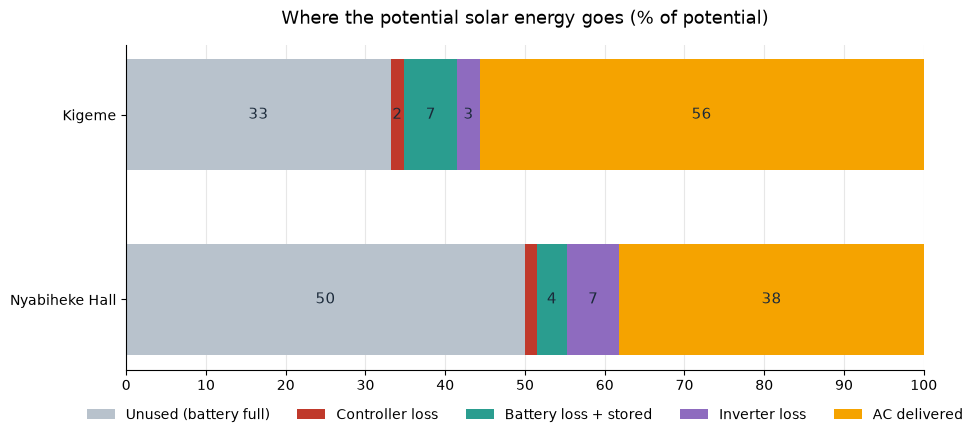

In [22]:
FLOW = {}
for n in NAMES:
    d = DAILY[n][DAILY[n]["complete"]]
    t = d[["PV", "Pc", "InvDC", "AC", "Chg", "Dis"]].sum()
    potential = CURT[n].loc["TOTAL", "potential kWh"]
    FLOW[n] = {"Unused (battery full)": max(potential - t["PV"], 0),
               "Controller loss": t["PV"] - t["Pc"],
               "Battery loss + stored": t["Chg"] - t["Dis"],
               "Inverter loss": t["InvDC"] - t["AC"],
               "AC delivered": t["AC"]}
FL = pd.DataFrame(FLOW)
FLP = 100 * FL / FL.sum()
display(FL); display(FLP.round(1))

COLORS = ["#B8C2CC", "#C0392B", "#2A9D8F", "#8E6BBF", "#F5A300"]
fig, ax = plt.subplots(figsize=(10, 4.5))
left = np.zeros(len(NAMES))
for lab, col in zip(FLP.index, COLORS):
    w = FLP.loc[lab, NAMES].values
    bars = ax.barh(NAMES, w, left=left, color=col, label=lab, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}" if v >= 1.5 else "" for v in w],
                 label_type="center", fontsize=11, color="#1b2a3a")
    left += w

ax.set(xlim=(0, 100), xlabel="")
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="")
ax.set_xticks(range(0, 101, 10))
ax.set_title("Where the potential solar energy goes (% of potential)", pad=15, fontsize=13)
ax.set_axisbelow(True); ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False, fontsize=10)

show_fig("06_energy_flow")

**Findings.** About 42% (Kigeme) and 50% (Hall) of calibrated PV potential goes unused because the battery is full, about 3.1 kWh/day at both sites. At the Hall the share falls from 55 to 70% in July to October to about 30 to 40% in November and December, as load grows. PV tracks AC load more closely than modelled sunshine, the signature of a demand-limited system. The usual performance ratio would therefore measure curtailment, not faults, and is not used as a health measure.

### 6.2 When the surplus is available
Unused PV inside each 4-hour daytime window; six laptops for four hours need 1.2 kWh.

In [23]:
WINDOWS = {}
for n in NAMES:
    h = HOURLY[n]
    comp = h["date"].map(DAILY[n]["complete"]).fillna(False).astype(bool)
    hc = h[comp]
    rows = []
    for s in range(7, 14):
        w = hc[(hc["hour"] >= s) & (hc["hour"] < s + 4)]
        per_day = w.groupby("date")["unused_Wh"].sum() / 1000
        rows.append({"window": f"{s:02d}:00-{s + 4:02d}:00", "median kWh/day": per_day.median(), "10th pct kWh/day": per_day.quantile(0.1),
                     "% days >= 1.2 kWh": 100 * (per_day >= 1.2).mean(), "% days >= 0.6 kWh": 100 * (per_day >= 0.6).mean()})
    WINDOWS[n] = pd.DataFrame(rows).set_index("window")
    print(f"\n{n}: unused PV inside each 4-hour window (six laptops for 4 h need 1.2 kWh)")
    display(WINDOWS[n]); save(WINDOWS[n], f"06_windows_{n.split()[0]}")


Kigeme: unused PV inside each 4-hour window (six laptops for 4 h need 1.2 kWh)


,median kWh/day,10th pct kWh/day,% days >= 1.2 kWh,% days >= 0.6 kWh
window,,,,
07:00-11:00,0.53,0.00,16.96,46.09
08:00-12:00,1.05,0.08,45.22,64.78
09:00-13:00,1.57,0.17,59.57,75.65
10:00-14:00,1.99,0.26,68.70,82.61
11:00-15:00,2.11,0.25,70.43,83.04
12:00-16:00,1.89,0.18,64.78,78.26
13:00-17:00,1.31,0.12,51.74,70.87



Nyabiheke Hall: unused PV inside each 4-hour window (six laptops for 4 h need 1.2 kWh)


,median kWh/day,10th pct kWh/day,% days >= 1.2 kWh,% days >= 0.6 kWh
window,,,,
07:00-11:00,0.74,0.00,34.38,54.30
08:00-12:00,1.27,0.00,51.17,66.41
09:00-13:00,1.67,0.08,60.16,77.73
10:00-14:00,1.87,0.22,70.31,81.25
11:00-15:00,2.04,0.22,70.70,81.64
12:00-16:00,1.78,0.28,64.84,78.91
13:00-17:00,1.14,0.19,48.44,73.05


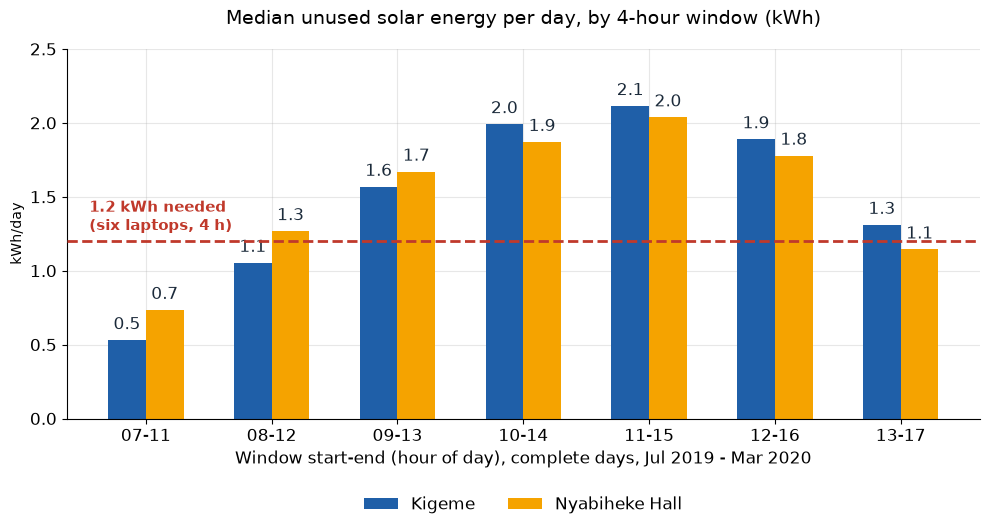

In [24]:
BLUE, AMBER, RED = "#1F5FA8", "#F5A300", "#C0392B"
win = list(WINDOWS[NAMES[0]].index)
x, w = np.arange(len(win)), 0.3
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (n, col) in enumerate(zip(NAMES, [BLUE, AMBER])):
    b = ax.bar(x + (i - 0.5) * w, WINDOWS[n].loc[win, "median kWh/day"].values, w, color=col, label=n)
    ax.bar_label(b, fmt="%.1f", padding=5, fontsize=12, color="#1b2a3a")
ax.axhline(1.2, color=RED, ls="--", lw=2, zorder=5)
ax.text(-0.45, 1.24, "1.2 kWh needed\n(six laptops, 4 h)", ha="left", va="bottom", color=RED, fontsize=11, fontweight="bold", zorder=6)
ax.set_ylim(0, 2.5); ax.set_xticks(x); ax.set_xticklabels([s.replace(":00", "") for s in win])
ax.tick_params(labelsize=12)
ax.set_xlabel("Window start-end (hour of day), complete days, Jul 2019 - Mar 2020", fontsize=12)
ax.set_ylabel("kWh/day")
ax.set_title("Median unused solar energy per day, by 4-hour window (kWh)", pad=18, fontsize=14)
ax.set_axisbelow(True); ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False, fontsize=12)
show_fig("slide_spare_solar_by_window")

**Findings.** The best window is 11:00 to 15:00: median 2.11 kWh (Kigeme) and 2.04 kWh (Hall), with at least 1.2 kWh on 70 to 71% of days. On the worst day in ten only about 0.2 kWh is spare, so a 1.2 kWh daytime service needs an operating rule, not a guarantee. The 07:00 to 11:00 window holds only about 0.5 to 0.7 kWh.

## 7. Reliability: recorded zeros, missing data, SOC jumps and low-SOC episodes (Q1, Q2)
These are screens, not root causes: there is no battery-voltage, inverter-alarm or maintenance channel. Both sites carry a standing night load, so a genuine AC zero means the inverter output was off. A zero at high SOC points to a non-energy cause (inverter, breaker, logger); a zero at low SOC would fit a low-voltage disconnect.

In [25]:
def find_runs(d, mask, gap_min):
    mask = mask.fillna(False).astype(bool)
    start = mask & (~mask.shift(fill_value=False) | (d["time"].diff() > pd.Timedelta(minutes=gap_min)))
    run_id = start.cumsum().where(mask)
    x = d[mask].assign(run=run_id[mask])
    g = x.groupby("run")
    ev = pd.DataFrame({"start": g["time"].min(), "end": g["time"].max(), "soc_start": g["soc"].first(), "soc_min": g["soc"].min(),
                       "pv_mean_W": g["pv"].mean(), "ac_mean_W": g["ac"].mean()})
    ev["hours"] = (ev["end"] - ev["start"]).dt.total_seconds() / 3600
    return ev

ZERO, AVAIL = {}, {}
for n in NAMES:
    d = DF[n]
    step_h = d["time"].diff().dt.total_seconds().median() / 3600
    ev = find_runs(d, (d["ac"] <= 5) & d["ac"].notna(), SITES[n]["gap_min"])
    if len(ev):
        ev["hours"] = ev["hours"] + step_h
        ev = ev[ev["hours"] >= 0.25].copy()
        ev["reading"] = np.where(ev["soc_start"] >= 70, "SOC high -> not an energy shortage",
                                 np.where(ev["soc_min"] <= 45, "SOC low -> fits low-voltage cut-off", "unclear"))
        ev = ev.sort_values("hours", ascending=False)
    ZERO[n] = ev
    seen = IV[n]["cov_h"].sum()
    zero_h = ev["hours"].sum() if len(ev) else 0.0
    AVAIL[n] = {"zero-AC events (>= 15 min)": len(ev), "zero-AC hours": zero_h, "observed hours": seen,
                "availability (observed hours)": 1 - zero_h / seen, "longest zero (h)": ev["hours"].max() if len(ev) else 0.0,
                "events with SOC high": int((ev["reading"].str.startswith("SOC high")).sum()) if len(ev) else 0}
    print(f"\n{n}: longest zero-AC events"); display(ev.head(8) if len(ev) else "none")
AVAIL = pd.DataFrame(AVAIL)
display(AVAIL)
save(AVAIL, "07_availability")


Kigeme: longest zero-AC events


,start,end,soc_start,soc_min,pv_mean_W,ac_mean_W,hours,reading
run,,,,,,,,
74.00,2019-09-06 15:23:16,2019-09-11 11:18:35,100.00,100.00,12.10,0.00,115.94,SOC high -> not an energy shortage
75.00,2019-09-11 11:19:58,2019-09-12 11:03:21,100.00,100.00,13.74,0.00,23.74,SOC high -> not an energy shortage
72.00,2019-09-04 19:13:38,2019-09-05 18:56:50,100.00,100.00,25.70,0.00,23.74,SOC high -> not an energy shortage
65.00,2019-08-11 08:45:25,2019-08-11 18:20:20,89.00,89.00,484.74,0.00,9.60,SOC high -> not an energy shortage
85.00,2019-12-11 00:22:40,2019-12-11 09:13:41,93.00,93.00,81.69,0.00,8.87,SOC high -> not an energy shortage
68.00,2019-09-04 11:55:04,2019-09-04 18:35:34,100.00,100.00,134.41,0.00,6.69,SOC high -> not an energy shortage
82.00,2019-10-28 09:33:08,2019-10-28 15:52:55,100.00,100.00,515.71,0.00,6.35,SOC high -> not an energy shortage
90.00,2020-01-18 12:11:13,2020-01-18 18:28:14,100.00,100.00,357.86,0.00,6.30,SOC high -> not an energy shortage



Nyabiheke Hall: longest zero-AC events


,start,end,soc_start,soc_min,pv_mean_W,ac_mean_W,hours,reading
run,,,,,,,,
1.00,2019-09-22 11:46:00,2019-09-22 13:31:00,100.00,100.00,87.25,0.00,2.00,SOC high -> not an energy shortage
4.00,2020-03-15 17:45:48,2020-03-15 19:00:48,100.00,99.90,9.38,0.00,1.50,SOC high -> not an energy shortage
2.00,2019-09-23 17:42:00,2019-09-23 17:42:00,100.00,100.00,89.00,0.00,0.25,SOC high -> not an energy shortage
3.00,2019-12-06 10:01:20,2019-12-06 10:01:20,88.00,88.00,308.00,0.00,0.25,SOC high -> not an energy shortage


,Kigeme,Nyabiheke Hall
zero-AC events (>= 15 min),25.00,4.00
zero-AC hours,217.58,4.00
observed hours,"5,657.34","6,139.58"
availability (observed hours),0.96,1.00
longest zero (h),115.94,2.00
events with SOC high,25.00,4.00


### 7.1 September 2019: recorded zero versus missing data
Blank and absent records are kept separate from recorded zeros, day by day, at both sites.

In [26]:
def september_check(raw):
    s = raw[(raw["time"] >= "2019-09-01") & (raw["time"] < "2019-09-23")]
    g = s.groupby(s["time"].dt.normalize())
    t = pd.DataFrame({"rows": g.size(), "AC blank": g["ac"].apply(lambda x: int(x.isna().sum())),
                      "AC recorded 0": g["ac"].apply(lambda x: int((x == 0).sum())),
                      "AC max W": g["ac"].max(), "PV max W": g["pv"].max(), "SOC max": g["soc"].max()})
    t = t.reindex(pd.date_range("2019-09-01", "2019-09-22"))
    t["rows"] = t["rows"].fillna(0)
    share_zero = t["AC recorded 0"] / t["rows"].replace(0, np.nan)
    t["status"] = np.where(t["rows"] == 0, "NO RECORDS (missing)",
                  np.where(t["AC blank"] == t["rows"], "AC blank",
                  np.where(share_zero > 0.9, "AC recorded as 0 all day",
                  np.where(share_zero > 0.05, "part of day at 0", "AC present"))))
    return t

SEP = {n: september_check(RAW[n]) for n in NAMES}
for n in NAMES:
    print(n); display(SEP[n]); save(SEP[n], f"07_september_{n.split()[0]}")

Kigeme


,rows,AC blank,AC recorded 0,AC max W,PV max W,SOC max,status
2019-09-01,"1,651.00",0.00,0.00,359.00,"1,842.00",100.00,AC present
2019-09-02,"1,604.00",0.00,0.00,348.00,"1,602.00",100.00,AC present
2019-09-03,"1,534.00",0.00,0.00,352.00,"2,612.00",100.00,AC present
2019-09-04,"1,523.00",45.00,716.00,318.00,"2,021.00",100.00,part of day at 0
2019-09-05,"1,500.00",303.00,"1,197.00",0.00,156.00,100.00,part of day at 0
2019-09-06,"1,496.00",959.00,537.00,0.00,440.00,100.00,part of day at 0
2019-09-07,"1,615.00",0.00,"1,615.00",0.00,148.00,100.00,AC recorded as 0 all day
2019-09-08,"1,510.00",0.00,"1,510.00",0.00,115.00,100.00,AC recorded as 0 all day
2019-09-09,"1,515.00",0.00,"1,515.00",0.00,122.00,100.00,AC recorded as 0 all day
2019-09-10,"1,503.00",0.00,"1,503.00",0.00,125.00,100.00,AC recorded as 0 all day


Nyabiheke Hall


,rows,AC blank,AC recorded 0,AC max W,PV max W,SOC max,status
2019-09-01,122,0,0,206.00,567,100.00,AC present
2019-09-02,127,0,0,185.00,878,100.00,AC present
2019-09-03,177,0,0,211.00,774,100.00,AC present
2019-09-04,169,0,0,186.00,972,100.00,AC present
2019-09-05,169,0,0,131.00,584,100.00,AC present
2019-09-06,127,0,0,181.00,859,100.00,AC present
2019-09-07,167,0,0,204.00,1259,100.00,AC present
2019-09-08,145,0,0,204.00,867,100.00,AC present
2019-09-09,199,0,0,70.00,772,100.00,AC present
2019-09-10,131,0,0,209.00,727,100.00,AC present


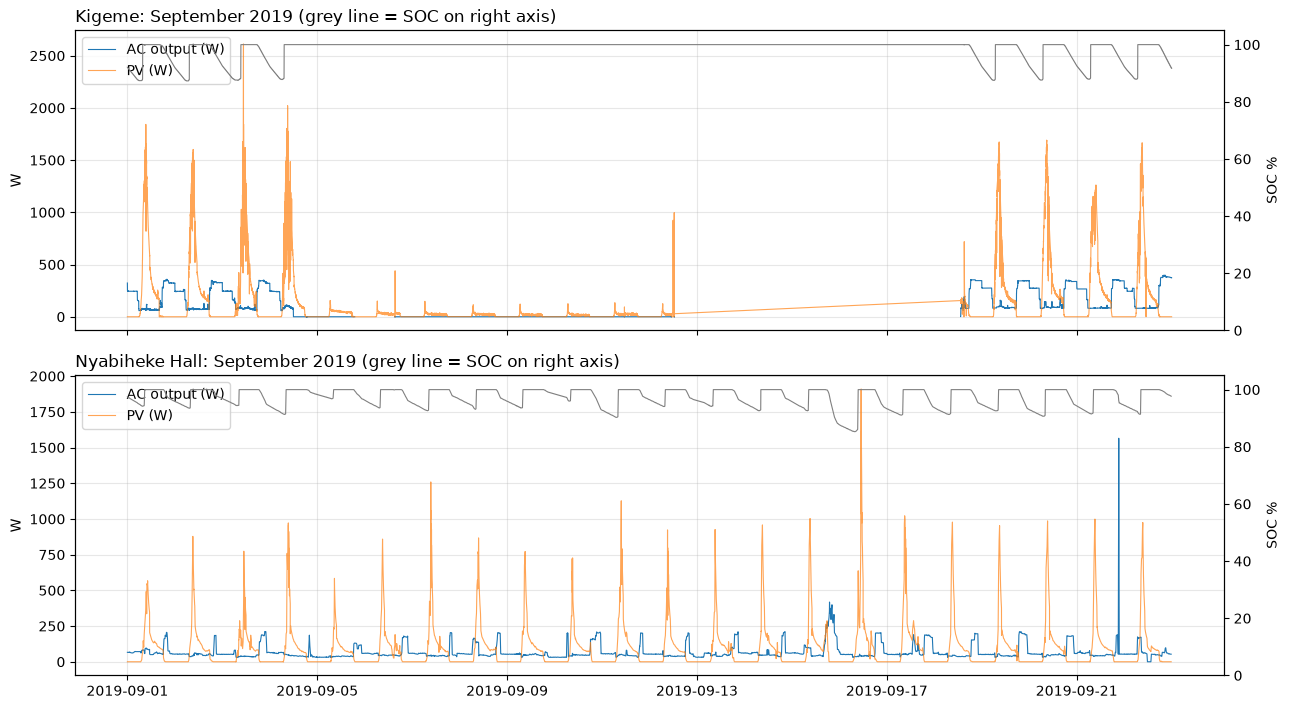

In [27]:
fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 3.6 * len(NAMES)), sharex=True)
for ax, n in zip(axes, NAMES):
    s = RAW[n][(RAW[n]["time"] >= "2019-09-01") & (RAW[n]["time"] < "2019-09-23")]
    ax.plot(s["time"], s["ac"], lw=0.8, label="AC output (W)")
    ax.plot(s["time"], s["pv"], lw=0.8, alpha=0.7, label="PV (W)")
    ax.set_ylabel("W"); ax.set_title(f"{n}: September 2019 (grey line = SOC on right axis)", loc="left")
    a2 = ax.twinx(); a2.plot(s["time"], s["soc"], color="grey", lw=0.8); a2.set_ylim(0, 105); a2.set_ylabel("SOC %"); a2.grid(False)
    ax.legend(loc="upper left")
show_fig("07_september")

**Findings.** The Hall has AC on every day of this window. At Kigeme, AC is recorded as exactly zero from 4 September to 12 September (about 170 h) with SOC at 100%, and then there are **no records at all** from 12 to 18 September (one 144.7 h gap). These are two different things: a recorded outage, and an unobserved period. With the battery full, the outage is not an energy shortage or a low-voltage disconnect; likely causes are a switched-off or tripped inverter, a breaker, or a fault, and the zero and the gap may be one event or two. Only the site logbook can confirm.

Outside that event, availability is 99.1% at Kigeme (96.2% including it) and 99.9% at the Hall, and every other zero occurs at high SOC.

### 7.2 SOC jumps: stored energy or monitor re-sync?

In [28]:
def soc_jumps(d, cap_kwh, jump=8.0, max_h=0.25):
    x = d[["time", "soc", "pb"]].copy()
    x["dt_h"] = x["time"].diff().dt.total_seconds() / 3600
    x["dSOC"] = x["soc"].diff()
    x["pb_prev"] = x["pb"].shift(1)
    j = x[(x["dSOC"].abs() >= jump) & (x["dt_h"] <= max_h)].copy()
    j["implied kWh"] = cap_kwh * j["dSOC"] / 100
    j["integrated kWh"] = (j["pb"] + j["pb_prev"]) / 2 * j["dt_h"] / 1000
    j["verdict"] = np.where((j["implied kWh"] - j["integrated kWh"]).abs() > 0.5 * j["implied kWh"].abs(), "re-sync (energy does not match)", "consistent with energy")
    return j[["time", "dt_h", "dSOC", "implied kWh", "integrated kWh", "verdict"]]

JUMPS = {n: soc_jumps(DF[n], SITES[n]["batt_kwh"]) for n in NAMES}
for n in NAMES:
    j = JUMPS[n]
    print(f"\n{n}: {len(j)} SOC jumps of 8+ points within 15 min; {int((j['verdict'].str.startswith('re-sync')).sum())} do not match the energy flow")
    print("typical jump hour:", j["time"].dt.hour.median() if len(j) else "n/a")
    display(j.head(6))


Kigeme: 226 SOC jumps of 8+ points within 15 min; 226 do not match the energy flow
typical jump hour: 7.0


,time,dt_h,dSOC,implied kWh,integrated kWh,verdict
235,2019-07-03 08:25:57,0.25,10.60,2.24,0.20,re-sync (energy does not match)
399,2019-07-04 08:25:55,0.25,11.00,2.32,0.17,re-sync (energy does not match)
758,2019-07-06 08:25:52,0.25,11.20,2.36,0.17,re-sync (energy does not match)
919,2019-07-07 09:55:49,0.25,11.40,2.41,0.11,re-sync (energy does not match)
1288,2019-07-09 10:25:45,0.25,10.30,2.17,0.15,re-sync (energy does not match)
1470,2019-07-10 07:55:43,0.25,11.70,2.47,0.12,re-sync (energy does not match)



Nyabiheke Hall: 90 SOC jumps of 8+ points within 15 min; 90 do not match the energy flow
typical jump hour: 8.0


,time,dt_h,dSOC,implied kWh,integrated kWh,verdict
5354,2019-09-04 08:16:00,0.25,8.50,0.90,0.02,re-sync (energy does not match)
6219,2019-09-11 08:16:00,0.25,9.50,1.01,0.04,re-sync (energy does not match)
6797,2019-09-16 09:31:00,0.25,13.90,1.47,0.09,re-sync (energy does not match)
6921,2019-09-17 08:16:00,0.25,8.60,0.91,0.07,re-sync (energy does not match)
7041,2019-09-18 08:31:00,0.25,8.30,0.88,0.07,re-sync (energy does not match)
7265,2019-09-20 08:08:00,0.12,9.00,0.95,0.02,re-sync (energy does not match)


**Findings.** SOC jumps of 8 to 16 points within 15 minutes occur on most mornings (226 at Kigeme, 90 at the Hall), claiming 1 to 2 kWh while only a few hundredths of a kWh flow. This is the monitor re-synchronising, not energy being recovered. Reported morning SOC can be off by about 10 points, which also explains the above-nominal apparent capacity in Section 5.

### 7.3 Low-SOC episodes: weather or demand?

In [29]:
EPIS = {}
for n in NAMES:
    d = DF[n]
    ev = find_runs(d, d["soc"] < SITES[n]["low_soc"], 60)
    if len(ev) == 0:
        print(f"{n}: SOC never below {SITES[n]['low_soc']} % -> no episodes"); EPIS[n] = ev; continue
    sun = None
    if PVG[n] is not None:
        sun = PVG[n].groupby(PVG[n].index.normalize()).sum()
        sun_typ = sun[sun > 0].median()
    ac_day = DAILY[n]["AC"].where(DAILY[n]["complete"])
    ac_typ = ac_day.rolling(30, min_periods=10).median().shift(1)
    rows = []
    for _, e in ev.iterrows():
        day = e["start"].normalize()
        days3 = pd.date_range(day - pd.Timedelta(days=3), day)
        sun_idx = sun.reindex(days3).mean() / sun_typ if sun is not None else np.nan
        typ = ac_typ.reindex([day]).iloc[0]
        dem_idx = ac_day.reindex(days3).mean() / typ if pd.notna(typ) else np.nan
        low_sun = pd.notna(sun_idx) and sun_idx < 0.85
        high_load = pd.notna(dem_idx) and dem_idx > 1.15
        cause = "low sun and high load" if (low_sun and high_load) else "low sun" if low_sun else "high load" if high_load else "neither clear"
        rows.append({"start": e["start"], "end": e["end"], "hours": e["hours"], "lowest SOC": e["soc_min"],
                     "sun index (3 days before)": sun_idx, "load index (3 days before)": dem_idx, "likely driver": cause})
    EPIS[n] = pd.DataFrame(rows).sort_values("lowest SOC").reset_index(drop=True)
    print(f"\n{n}: episodes with SOC below {SITES[n]['low_soc']} %"); display(EPIS[n].head(10))

Kigeme: SOC never below 70 % -> no episodes

Nyabiheke Hall: episodes with SOC below 65 %


,start,end,hours,lowest SOC,sun index (3 days before),load index (3 days before),likely driver
0,2019-11-24 18:01:00,2019-11-26 10:16:00,40.25,42.30,0.66,1.66,low sun and high load
1,2020-02-28 20:19:58,2020-02-29 09:45:06,13.42,49.40,0.78,1.17,low sun and high load
2,2019-11-23 21:46:00,2019-11-24 13:31:00,15.75,54.90,0.71,1.58,low sun and high load
3,2020-01-26 23:50:33,2020-01-27 09:35:34,9.75,60.60,0.68,1.10,low sun
4,2020-01-30 00:35:03,2020-01-30 08:05:01,7.50,63.30,0.60,1.22,low sun and high load
5,2020-01-29 06:35:00,2020-01-29 07:20:00,0.75,64.90,0.60,1.47,low sun and high load


**Findings.** The only serious low-SOC period is at the Hall on 23 to 26 November (lowest 42.3% on 25 November): the preceding days had about 30% less modelled sunshine while load ran about 60% above its recent median. Later episodes show the same pattern in milder form. The battery recovered and no AC zero occurred at low SOC, so the margin shrank but service was not lost. Kigeme never falls below 70%.

### 7.4 Inverter loading against its rating

In [30]:
OVL = {}
for n in NAMES:
    x = IV[n][IV[n]["ok"]]
    w = x["dt_h"].values
    OVL[n] = {"max AC (W)": x["ac"].max(), "99.9th percentile (W)": x["ac"].quantile(0.999), "rating at 25 C (W)": SITES[n]["limit_25"],
              "% of time above 80 % of rating": 100 * np.average(x["ac"].values > 0.8 * SITES[n]["limit_25"], weights=w),
              "% of time above rating": 100 * np.average(x["ac"].values > SITES[n]["limit_25"], weights=w)}
OVL = pd.DataFrame(OVL)
display(OVL)
if OVL.loc["max AC (W)", "Kigeme"] > 1.2 * OVL.loc["rating at 25 C (W)", "Kigeme"]:
    print("Kigeme: the AC channel peaks far above the assumed 960 W continuous rating, but the 99.9th percentile is much lower, so these look like rare spikes, or the rating in the case table is incomplete. Kigeme power conclusions are provisional.")

,Kigeme,Nyabiheke Hall
max AC (W),"3,106.00","1,758.00"
99.9th percentile (W),401.50,"1,686.17"
rating at 25 C (W),960.00,"2,400.00"
% of time above 80 % of rating,0.02,0.00
% of time above rating,0.01,0.00


Kigeme: the AC channel peaks far above the assumed 960 W continuous rating, but the 99.9th percentile is much lower, so these look like rare spikes, or the rating in the case table is incomplete. Kigeme power conclusions are provisional.


Kigeme's 99.9th-percentile draw is about 400 W, but isolated spikes reach 3,106 W against a 960 W continuous rating. These are rare (well under 0.1% of time) and consistent with an appliance such as an iron, but the dataset has no appliance log, so Kigeme power conclusions are provisional. The Hall shows no overload.

---
# Part B. Device level: which circuits have failed? (Q1, Q2)
System totals show whether energy is flowing; they cannot show which room has no light. This part builds a per-circuit fault table from the CPE (lighting) and socket meters.

**Method.** Sparse readings become held-state intervals (capped at 6 hours). Each device-week gets a dark fraction (share of observed time at exactly 0 W) and each device a baseline (its median weekly dark fraction). A device-week is **anomalous** if it has at least 2 days of coverage, is dark more than 95% of the time, and is more than 25 percentage points above its own baseline.

In [31]:
MAX_HOLD = pd.Timedelta(hours=6)

def intervals_from_series(ts, power):
    starts, ends = ts[:-1], ts[1:]
    capped_ends = np.minimum(ends, starts + np.timedelta64(MAX_HOLD))
    duration_s = (capped_ends - starts) / np.timedelta64(1, "s")
    return starts, duration_s, power[:-1]

def process_cpe_file(path, location):
    df = pd.read_csv(path, parse_dates=["Timestamp (Africa/Kigali)"]).rename(
        columns={"Timestamp (Africa/Kigali)": "ts", "ID": "circuit"})
    rows = []
    for led, col in [("LED1","LED1_P (W)"), ("LED2","LED2_P (W)"), ("LED3","LED3_P (W)")]:
        for circuit, g in df[["ts","circuit",col]].dropna(subset=[col]).groupby("circuit"):
            g = g.sort_values("ts")
            s, d, p = intervals_from_series(g["ts"].to_numpy(), g[col].to_numpy())
            rows.append(pd.DataFrame({"start": s, "duration_s": d, "power": p,
                                       "device": f"{circuit} {led}", "location": location, "kind": "light"}))
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

def process_socket_file(path, location):
    df = pd.read_csv(path, parse_dates=["Timestamp (Africa/Kigali)"]).rename(
        columns={"Timestamp (Africa/Kigali)": "ts", "ID": "circuit"})
    col = [c for c in df.columns if "vRELAY" in c][0]
    rows = []
    for circuit, g in df[["ts","circuit",col]].dropna(subset=[col]).groupby("circuit"):
        g = g.sort_values("ts")
        s, d, p = intervals_from_series(g["ts"].to_numpy(), g[col].to_numpy())
        rows.append(pd.DataFrame({"start": s, "duration_s": d, "power": p,
                                   "device": circuit, "location": location, "kind": "socket"}))
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

jobs = (
    [("cpe", MG_DIR / f"{loc}_CPE_data.csv", loc, "Microgrid")
     for loc in ["Nursery1A","Nursery1B","Nursery1C","Nursery2A","Nursery2B","Nursery2C","Playground","Streetlight"]]
    + [("sock", MG_DIR / f"{loc}_sockets_data.csv", loc, "Microgrid")
       for loc in ["Nursery1A","Nursery1B","Nursery1C","Nursery2A","Nursery2B","Nursery2C","Playground"]]
    + [("cpe", HL_DIR / f"Hall_CPE{i}_data.csv", f"Hall_CPE{i}", "Hall") for i in range(1, 8)]
    + [("sock", HL_DIR / f"Hall_S{i}_data.csv", f"Hall_S{i}", "Hall") for i in range(1, 5)]
)
all_intervals = []
for kind, path, loc, site in jobs:
    iv = process_cpe_file(path, loc) if kind == "cpe" else process_socket_file(path, loc)
    iv["site"] = site
    all_intervals.append(iv)
intervals = pd.concat(all_intervals, ignore_index=True)
intervals["is_zero"] = intervals["power"] == 0
intervals["week"] = pd.to_datetime(intervals["start"]).dt.to_period("W-MON")

MIN_COVERAGE_S = 2*24*3600
weekly = (intervals.groupby(["site","location","kind","device","week"])
          .apply(lambda d: pd.Series({"observed_s": d.duration_s.sum(),
                                       "zero_s": d.loc[d.is_zero,"duration_s"].sum()}), include_groups=False)
          .reset_index())
weekly["dark_frac"] = weekly.zero_s / weekly.observed_s
weekly["coverage_ok"] = weekly.observed_s >= MIN_COVERAGE_S
weekly["week_start"] = pd.PeriodIndex(weekly.week, freq="W-MON").start_time
baseline = weekly[weekly.coverage_ok].groupby("device")["dark_frac"].median().rename("baseline")
weekly = weekly.merge(baseline, on="device", how="left")
weekly["excess"] = weekly.dark_frac - weekly.baseline
weekly["anomaly"] = weekly.coverage_ok & (weekly.dark_frac > 0.95) & (weekly.excess > 0.25)

print(f"{len(intervals):,} intervals, {len(weekly):,} device-weeks, {weekly.anomaly.sum()} anomalies "
      f"({weekly[weekly.site=='Microgrid'].anomaly.sum()} Kigeme / {weekly[weekly.site=='Hall'].anomaly.sum()} Hall)")

6,220,065 intervals, 3,397 device-weeks, 63 anomalies (59 Kigeme / 4 Hall)


## B.1 Nursery 2B fixture `CPE10`
This fixture has been dark since the week of 29 Oct 2019 and was still dark in the last week of data (March 2020), despite appearing in the December, February and March checksheets.

In [32]:
cpe10 = weekly[(weekly.device.isin(["Nur 2B CPE10 LED1","Nur 2B CPE10 LED2","Nur 2B CPE10 LED3"]))]
print("Weeks this fixture has been confirmed dark (anomaly flag True):", cpe10.anomaly.sum(), "/", len(cpe10))
print("First anomalous week:", cpe10[cpe10.anomaly].week_start.min().date(),
      "| Last anomalous week:", cpe10[cpe10.anomaly].week_start.max().date())

Weeks this fixture has been confirmed dark (anomaly flag True): 27 / 93
First anomalous week: 2019-10-29 | Last anomalous week: 2020-03-24


## B.2 Faults cluster in Nursery 2 and the playground
This is a building-level pattern, so it supports an audit of the Nursery 2 installation, not only single repairs.

In [33]:
mg = weekly[weekly.site=="Microgrid"]
counts = mg[mg.anomaly].groupby("location").size().reindex(
    ["Nursery1A","Nursery1B","Nursery1C","Nursery2A","Nursery2B","Nursery2C","Playground","Streetlight"], fill_value=0)
n2_plus_outdoor = counts[["Nursery2A","Nursery2B","Nursery2C","Playground"]].sum()
n1 = counts[["Nursery1A","Nursery1B","Nursery1C"]].sum()
print(counts)
print(f"\nNursery 2 + outdoor areas: {n2_plus_outdoor} anomalies ({n2_plus_outdoor/counts.sum()*100:.0f}%) | Nursery 1: {n1} anomalies")

location
Nursery1A       0
Nursery1B       5
Nursery1C       2
Nursery2A      16
Nursery2B      27
Nursery2C       1
Playground      8
Streetlight     0
dtype: int64

Nursery 2 + outdoor areas: 52 anomalies (88%) | Nursery 1: 7 anomalies


## B.3 Playground
The playground has 8 anomalous device-weeks (4 lighting, 4 socket) and is named in the 23 March checksheet (10 lights not working).

In [34]:
pg = weekly[(weekly.location=="Playground") & weekly.anomaly]
print(pg[["device","kind","week_start","dark_frac","baseline"]].sort_values("week_start").to_string(index=False))

              device   kind week_start  dark_frac  baseline
       Playground S1 socket 2019-08-27       1.00      0.68
       Playground S1 socket 2019-09-17       1.00      0.68
       Playground S1 socket 2019-09-24       1.00      0.68
       Playground S1 socket 2019-10-08       1.00      0.68
Playground CPE4 LED2  light 2020-01-28       0.97      0.52
Playground CPE4 LED2  light 2020-02-04       1.00      0.52
Playground CPE4 LED2  light 2020-02-11       1.00      0.52
Playground CPE4 LED2  light 2020-02-25       1.00      0.52


## B.4 Streetlights need a schedule-aware baseline
The general rule finds no streetlight anomalies, yet the 23 March checksheet reports 3 lights out. Streetlights are meant to be dark by day, so the dark fraction is computed only over the scheduled 18:00 to 06:00 window, with its own baseline.

In [35]:
streetlight = intervals[intervals.location == "Streetlight"].copy()
streetlight["hour"] = pd.to_datetime(streetlight["start"]).dt.hour
streetlight["is_night"] = (streetlight.hour >= 18) | (streetlight.hour < 6)
night = streetlight[streetlight.is_night].copy()
night["is_zero"] = night["power"] == 0
night["week"] = pd.to_datetime(night["start"]).dt.to_period("W-MON")

night_weekly = (night.groupby(["device","week"])
                .apply(lambda d: pd.Series({"observed_s": d.duration_s.sum(),
                                             "zero_s": d.loc[d.is_zero,"duration_s"].sum()}), include_groups=False)
                .reset_index())
night_weekly["dark_frac_night"] = night_weekly.zero_s / night_weekly.observed_s
night_weekly["week_start"] = pd.PeriodIndex(night_weekly.week, freq="W-MON").start_time
night_weekly["coverage_ok"] = night_weekly.observed_s >= 24*3600
night_base = night_weekly[night_weekly.coverage_ok].groupby("device")["dark_frac_night"].median().rename("baseline_night")
night_weekly = night_weekly.merge(night_base, on="device", how="left")
night_weekly["excess"] = night_weekly.dark_frac_night - night_weekly.baseline_night

print("Night-only baseline dark fraction (how often each streetlight channel is dark *during its own")
print("scheduled operating hours* -- near-zero is expected for a healthy circuit):")
print(night_weekly.groupby("device")["baseline_night"].first().round(3))

mar = night_weekly[(night_weekly.week_start >= "2020-03-01") & night_weekly.device.str.contains("Streetlight 1")]
print()
print("Streetlight 1 (the pole named in the Mar 23 report), March 2020:")
print(mar[["device","week_start","dark_frac_night","baseline_night","excess"]].sort_values("week_start").round(3))

Night-only baseline dark fraction (how often each streetlight channel is dark *during its own
scheduled operating hours* -- near-zero is expected for a healthy circuit):
device
Streetlight 1 CPE LED1   0.08
Streetlight 1 CPE LED2   0.08
Streetlight 1 CPE LED3   0.08
Streetlight 2 CPE LED1   0.09
Streetlight 2 CPE LED2   0.09
Streetlight 2 CPE LED3   0.10
Streetlight 3 CPE LED1   0.08
Streetlight 3 CPE LED2   0.08
Streetlight 3 CPE LED3   0.08
Name: baseline_night, dtype: float64

Streetlight 1 (the pole named in the Mar 23 report), March 2020:
                     device week_start  dark_frac_night  baseline_night  excess
33   Streetlight 1 CPE LED1 2020-03-03             0.81            0.08    0.73
70   Streetlight 1 CPE LED2 2020-03-03             0.19            0.08    0.11
107  Streetlight 1 CPE LED3 2020-03-03             0.19            0.08    0.10
34   Streetlight 1 CPE LED1 2020-03-10             0.40            0.08    0.32
71   Streetlight 1 CPE LED2 2020-03-10            

With a night-only baseline of about 8%, `Streetlight 1` LED1 and LED3 rise well above baseline in March 2020 (LED1 81% in the week of 3 March, LED3 81% in the week of 17 March), matching the checksheet. Room lamps and streetlights need separate baselines.

## B.5 Is the Kigeme-Hall fault-rate gap real?
Weekly flags from the same device are not independent (a broken lamp stays broken for weeks). The naive z-test treats device-weeks as independent and is shown for reference only. The bootstrap resamples **whole devices** within each site, so each device's weeks stay together.

In [36]:
cov = weekly[weekly.coverage_ok]
FAULT = {}
for site in ["Microgrid", "Hall"]:
    s = cov[cov.site == site]
    FAULT[site] = {"device-weeks": len(s), "anomalies": int(s.anomaly.sum()), "rate %": 100 * s.anomaly.mean()}
FAULT = pd.DataFrame(FAULT)
display(FAULT)

x1, n1 = FAULT.loc["anomalies", "Microgrid"], FAULT.loc["device-weeks", "Microgrid"]
x2, n2 = FAULT.loc["anomalies", "Hall"], FAULT.loc["device-weeks", "Hall"]
p_pool = (x1 + x2) / (n1 + n2)
z = (x1 / n1 - x2 / n2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_naive = 2 * stats.norm.sf(abs(z))
print(f"Naive z = {z:.2f}, p = {p_naive:.1e} (NOT valid: weeks are not independent)")

rng_b = np.random.default_rng(42)
per_dev = cov.groupby(["site", "device"]).agg(weeks=("anomaly", "size"), anom=("anomaly", "sum")).reset_index()
dev = {s: per_dev[per_dev.site == s][["weeks", "anom"]].to_numpy() for s in ["Microgrid", "Hall"]}
B = 5000
diffs = np.empty(B)
for b in range(B):
    r = {}
    for s, arr in dev.items():
        pick = arr[rng_b.integers(0, len(arr), len(arr))]
        r[s] = pick[:, 1].sum() / pick[:, 0].sum()
    diffs[b] = 100 * (r["Microgrid"] - r["Hall"])
lo, hi = np.percentile(diffs, [2.5, 97.5])
BOOT = {"observed gap (pts)": FAULT.loc["rate %", "Microgrid"] - FAULT.loc["rate %", "Hall"], "95% low": lo, "95% high": hi,
        "Kigeme devices": len(dev["Microgrid"]), "Hall devices": len(dev["Hall"]), "share of resamples with gap <= 0": float((diffs <= 0).mean())}
display(pd.Series(BOOT).round(3))
print("Clustered interval EXCLUDES zero -> gap holds after allowing for dependence." if lo > 0
      else "Clustered interval INCLUDES zero -> treat the Kigeme-Hall gap as suggestive only.")

,Microgrid,Hall
device-weeks,"2,261.00",870.00
anomalies,59.00,4.00
rate %,2.61,0.46


Naive z = 3.84, p = 1.2e-04 (NOT valid: weeks are not independent)


observed gap (pts)                  2.15
95% low                             0.43
95% high                            4.26
Kigeme devices                     70.00
Hall devices                       25.00
share of resamples with gap <= 0    0.01
dtype: float64

Clustered interval EXCLUDES zero -> gap holds after allowing for dependence.


**Findings.** Kigeme has 59 anomalies in 2,261 device-weeks (2.6%) against 4 in 870 at the Hall (0.5%). The device-clustered 95% interval for the gap is 0.43 to 4.26 percentage points, which excludes zero, so the difference holds after allowing for dependence. The test cannot say why: Kigeme has more circuits and buildings and more outdoor exposure, and faults may be easier to notice in the Hall's single building.

---
# Part C. Is it meeting service needs? Supply versus service (Q2)
Electricity **supply** (the battery has energy, the inverter is on) and **service** (a child has light in the room, a phone can charge) are different. Aggregate energy cannot show who had access. The electrical record can show whether load steps at the documented lighting times, how much load is a standing base, whether demand is growing, and how each meter behaves.

## 8. Load timing and growth

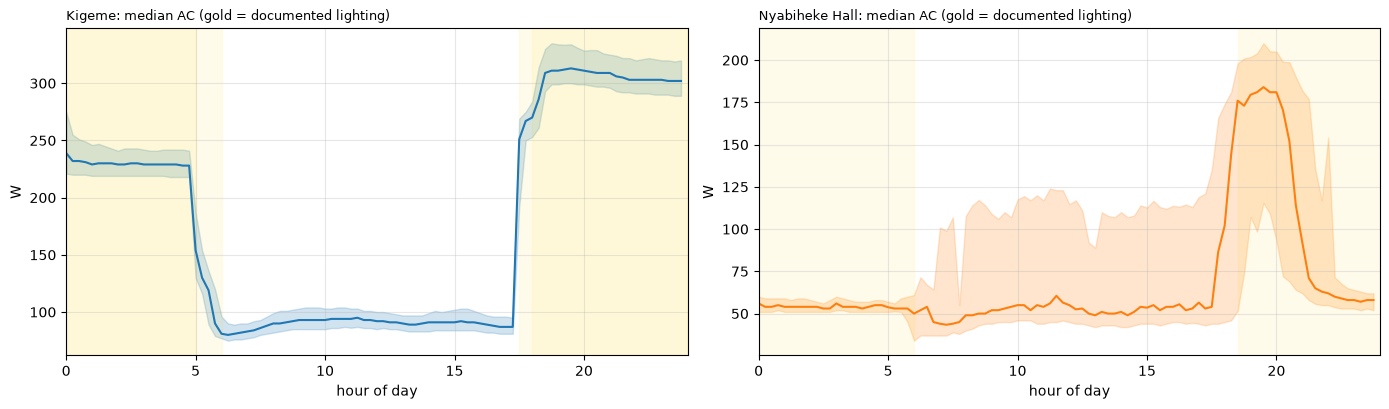

Kigeme - largest 15-minute steps in the median load


,clock time,step in median load (W)
0,05:00,-74.00
1,05:45,-29.00
2,17:30,164.00
3,18:30,23.00


Nyabiheke Hall - largest 15-minute steps in the median load


,clock time,step in median load (W)
0,17:45,32.50
1,18:15,42.00
2,20:45,-38.00
3,21:00,-22.00


In [37]:
def time_of_day(d):
    x = d[d["ac"] > 5].copy()
    x["tod"] = (x["time"].dt.hour * 60 + x["time"].dt.minute) // 15 * 15 / 60
    g = x.groupby("tod")["ac"]
    return pd.DataFrame({"median": g.median(), "p25": g.quantile(0.25), "p75": g.quantile(0.75)})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
STEPS = {}
for a, n in zip(axes, NAMES):
    p = time_of_day(DF[n])
    a.plot(p.index, p["median"], color=SITES[n]["color"]); a.fill_between(p.index, p["p25"], p["p75"], alpha=0.2, color=SITES[n]["color"])
    for label, s, e in SCHEDULES[n]:
        if e > 24:
            a.axvspan(s, 24, color="gold", alpha=0.08); a.axvspan(0, e - 24, color="gold", alpha=0.08)
        else:
            a.axvspan(s, e, color="gold", alpha=0.08)
    a.set_xlim(0, 24); a.set_xlabel("hour of day"); a.set_ylabel("W"); a.set_title(f"{n}: median AC (gold = documented lighting)", loc="left", fontsize=9)
    step = p["median"].diff().dropna()
    big = pd.concat([step.nlargest(2), step.nsmallest(2)]).sort_index()
    STEPS[n] = pd.DataFrame({"clock time": [f"{int(t):02d}:{int(round((t % 1) * 60)):02d}" for t in big.index], "step in median load (W)": big.values})
show_fig("08_time_of_day")
for n in NAMES:
    print(n, "- largest 15-minute steps in the median load"); display(STEPS[n])

In [38]:
SVC = {}
for n in NAMES:
    d = DF[n]
    pre_dawn = d[(d["ac"] > 5) & d["time"].dt.hour.between(1, 3)]["ac"].median()
    day = DAILY[n][DAILY[n]["complete"]]
    weekly_ac = day["AC"].resample("W").mean().dropna()
    slope = np.polyfit(np.arange(len(day)), day["AC"].values, 1)[0] * 30 if len(day) > 20 else np.nan
    nt = NIGHT[n]
    typical = nt["ac_W"].rolling(21, center=True, min_periods=7).median()
    low_nights = nt.index[nt["ac_W"] < 0.6 * typical]
    SVC[n] = {"01-03h median load (W)": pre_dawn, "that load x 24 h (kWh/day)": pre_dawn * 24 / 1000,
              "...as share of mean daily AC": pre_dawn * 24 / 1000 / day["AC"].mean(),
              "load trend (kWh/day per 30 days)": slope, "first weekly mean (kWh/day)": weekly_ac.iloc[0], "last weekly mean (kWh/day)": weekly_ac.iloc[-1],
              "nights with load < 60 % of normal": len(low_nights), "nights assessed": len(nt)}
    print(n, "- unusually low-load nights:", [str(x.date()) for x in low_nights][:14])
SVC = pd.DataFrame(SVC)
display(SVC)
save(SVC, "08_service_facts")

Kigeme - unusually low-load nights: ['2019-09-04', '2019-09-05', '2019-09-06', '2019-09-07', '2019-09-08', '2019-09-09', '2019-09-10', '2019-09-11', '2019-11-27', '2020-03-04', '2020-03-25', '2020-03-26', '2020-03-27']
Nyabiheke Hall - unusually low-load nights: ['2019-08-25', '2019-09-04', '2019-09-09', '2019-10-18', '2019-11-21', '2019-12-25', '2020-01-02', '2020-01-24', '2020-02-05', '2020-02-09', '2020-02-14', '2020-03-02', '2020-03-06', '2020-03-14']


,Kigeme,Nyabiheke Hall
01-03h median load (W),230.00,54.00
that load x 24 h (kWh/day),5.52,1.30
...as share of mean daily AC,1.32,0.55
load trend (kWh/day per 30 days),0.01,0.19
first weekly mean (kWh/day),3.82,0.95
last weekly mean (kWh/day),4.04,2.15
nights with load < 60 % of normal,13.00,15.00
nights assessed,233.00,254.00


**Findings.** At Kigeme the median load steps up 164 W at 17:30 and down 74 W at 05:00, matching the documented playground and nursery lighting times, so the timetable is being delivered. The Hall steps up at 17:45 and 18:15, shortly before its documented 18:30 outdoor lighting; its 06:00 switch-off is not visible. The Hall's pre-dawn base is about 1.3 kWh/day, about half its daily use. **Hall demand more than doubled** from 0.95 to 2.15 kWh/day between the first and last weeks, which is why its battery was comfortable until October and stressed from November. Kigeme demand was flat (3.82 to 4.04 kWh/day).

## 8.1 Individual meters
Meters are compared with system AC, never added to it.

In [39]:
def device_kind(name):
    low = name.lower()
    if low.startswith("system"):
        return None
    if "cpe" in low:
        return "lighting (CPE)"
    if "socket" in low or re.match(r"hall_s_?\d+_data", low):
        return "socket"
    return None

def device_energy(t, p, gap_min):
    x = pd.DataFrame({"t": t, "p": p}).dropna().groupby("t", as_index=False).mean()
    dt = x["t"].diff().dt.total_seconds() / 3600
    mean_p = (x["p"] + x["p"].shift()) / 2
    ok = (dt > 0) & (dt <= gap_min / 60)
    x["Wh"] = (mean_p * dt).where(ok, 0)
    x["cov_h"] = dt.where(ok, 0)
    x["date"] = x["t"].dt.normalize()
    return x, x.groupby("date")[["Wh", "cov_h"]].sum()

DEV_ROWS, DEV_DAILY = [], []
for n, cfg in SITES.items():
    for path in sorted((DATA / cfg["folder"]).glob("*.csv")):
        kind = device_kind(path.name)
        if kind is None:
            continue
        raw = pd.read_csv(path)
        tcol = [c for c in raw.columns if str(c).strip().lower().startswith("timestamp")][0]
        t = pd.to_datetime(raw[tcol], errors="coerce")
        if t.dt.tz is not None:
            t = t.dt.tz_localize(None)
        if kind == "socket":
            cols = [c for c in raw.columns if "vRELAY1_LVL" in str(c)]
            if not cols:
                print("skipped (no socket power column):", path.name); continue
            p = pd.to_numeric(raw[cols[0]], errors="coerce")
        else:
            cols = [c for c in raw.columns if re.match(r"LED\d_P", str(c).strip())]
            p = raw[cols].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=1)
        x, daily = device_energy(t, p, cfg["gap_min"])
        daily["site"], daily["kind"], daily["device"] = n, kind, path.stem.replace("_data", "")
        DEV_DAILY.append(daily.reset_index())
        DEV_ROWS.append({"site": n, "kind": kind, "device": path.stem.replace("_data", ""), "readings": len(x),
                         "energy kWh": x["Wh"].sum() / 1000, "covered hours": x["cov_h"].sum(),
                         "mean W": x["p"].mean(), "max W": x["p"].max(),
                         "% of readings above 5 W": 100 * (x["p"] > 5).mean()})
DEVICES = pd.DataFrame(DEV_ROWS)
DEV_DAILY = pd.concat(DEV_DAILY, ignore_index=True) if DEV_DAILY else pd.DataFrame()
print("Meter files read:", len(DEVICES), "(README expects 15 at Kigeme and 11 at the Hall for CPE + sockets)")
display(DEVICES.sort_values(["site", "kind", "energy kWh"], ascending=[True, True, False]))
save(DEVICES.set_index(["site", "kind", "device"]), "08_device_summary")

Meter files read: 26 (README expects 15 at Kigeme and 11 at the Hall for CPE + sockets)


,site,kind,device,readings,energy kWh,covered hours,mean W,max W,% of readings above 5 W
14,Kigeme,lighting (CPE),Streetlight_CPE,490336,11.84,"5,813.08",1.65,15.33,5.23
12,Kigeme,lighting (CPE),Playground_CPE,852738,8.87,"6,077.77",1.36,11.99,3.56
8,Kigeme,lighting (CPE),Nursery2B_CPE,233206,6.65,"5,292.88",1.13,13.14,7.48
10,Kigeme,lighting (CPE),Nursery2C_CPE,204308,2.82,"5,048.12",0.48,8.75,4.59
6,Kigeme,lighting (CPE),Nursery2A_CPE,299686,2.59,"5,556.82",0.37,8.88,2.46
4,Kigeme,lighting (CPE),Nursery1C_CPE,333461,2.55,"5,947.51",0.35,8.56,3.14
2,Kigeme,lighting (CPE),Nursery1B_CPE,362973,2.44,"5,823.84",0.33,8.64,2.94
0,Kigeme,lighting (CPE),Nursery1A_CPE,462586,1.49,"5,820.77",0.20,8.77,1.83
3,Kigeme,socket,Nursery1B_sockets,57112,7.09,"5,761.10",1.31,"3,756.00",3.20
7,Kigeme,socket,Nursery2A_sockets,79267,5.30,"5,335.75",0.98,26.00,3.71


                               energy kWh  covered hours
site           kind                                     
Kigeme         lighting (CPE)       39.25      45,380.78
               socket               22.74      32,465.53
Nyabiheke Hall lighting (CPE)        6.80      33,461.48
               socket              191.12      21,079.28


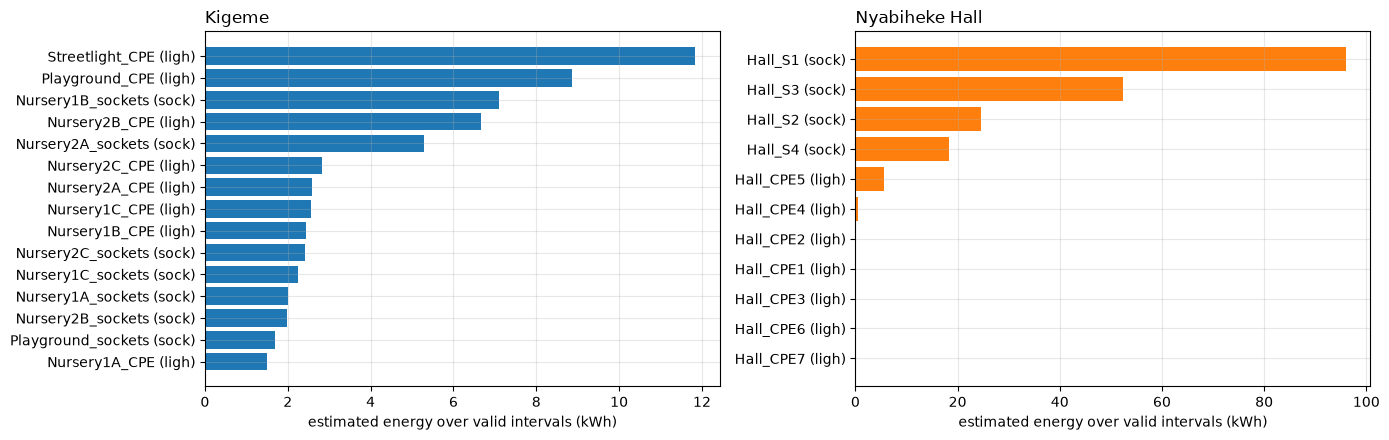

,days compared,median meters / system AC
site,,
Kigeme,225,0.05
Nyabiheke Hall,256,0.23


Meters read as a subset of the AC load, so a ratio below 1 is expected (unmetered loads, meter self-consumption, gaps).


In [40]:
if len(DEVICES):
    print(DEVICES.groupby(["site", "kind"])[["energy kWh", "covered hours"]].sum())
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for a, n in zip(axes, NAMES):
        s = DEVICES[DEVICES["site"] == n].sort_values("energy kWh")
        a.barh(s["device"] + " (" + s["kind"].str[:4] + ")", s["energy kWh"], color=SITES[n]["color"])
        a.set_xlabel("estimated energy over valid intervals (kWh)"); a.set_title(n, loc="left")
    show_fig("08_device_energy")

    rows = []
    for n in NAMES:
        dd = DEV_DAILY[DEV_DAILY["site"] == n].groupby("date")["Wh"].sum() / 1000
        sysd = DAILY[n][DAILY[n]["complete"]]["AC"]
        j = pd.concat([dd.rename("meters"), sysd.rename("system AC")], axis=1).dropna()
        rows.append({"site": n, "days compared": len(j), "median meters / system AC": (j["meters"] / j["system AC"]).median()})
    CROSS = pd.DataFrame(rows).set_index("site")
    display(CROSS)
    print("Meters read as a subset of the AC load, so a ratio below 1 is expected (unmetered loads, meter self-consumption, gaps).")

Meters explain only 5% of Kigeme system AC (Hall 23%), so about 95% of Kigeme load is not attributed to any metered device.

## C.1 Site totals cannot locate a failure
While `CPE10` was dark, did the site AC total point to the room? October (before) is compared with November (after), using integrated energy on complete days.

In [41]:
kig_day = DAILY["Kigeme"][DAILY["Kigeme"]["complete"]]["AC"]
before = kig_day.loc["2019-10-01":"2019-10-28"].mean()
after = kig_day.loc["2019-11-05":"2019-12-01"].mean()
print(f"Kigeme mean daily AC, Oct 2019 (before CPE10 failed): {before:.2f} kWh/day  ({kig_day.loc['2019-10-01':'2019-10-28'].size} complete days)")
print(f"Kigeme mean daily AC, Nov 2019 (after CPE10 failed):  {after:.2f} kWh/day  ({kig_day.loc['2019-11-05':'2019-12-01'].size} complete days)")
print(f"Change: {(after - before) / before * 100:+.1f}%")

Kigeme mean daily AC, Oct 2019 (before CPE10 failed): 4.67 kWh/day  (28 complete days)
Kigeme mean daily AC, Nov 2019 (after CPE10 failed):  4.19 kWh/day  (27 complete days)
Change: -10.3%


Site AC fell 10.3% (4.67 to 4.19 kWh/day), but a change of that size fits many explanations (attendance, weather, ordinary variation). The aggregate says something changed; only circuit-level data says what and where.

## C.2 Socket use
Use is the share of observed time a socket draws nonzero power.

In [42]:
sock = weekly[(weekly.kind == "socket") & weekly.coverage_ok].copy()
sock["active_frac"] = 1 - sock["dark_frac"]

print("Socket active-fraction (share of time something is actually drawing power), by site:")
print(sock.groupby("site")["active_frac"].describe()[["count","mean","50%","min","max"]].round(3))
print()
dev_util = sock.groupby(["site","location","device"])["active_frac"].mean().reset_index().sort_values("active_frac")
display(dev_util)

Socket active-fraction (share of time something is actually drawing power), by site:
           count  mean  50%  min  max
site                                 
Hall      135.00  0.31 0.18 0.01 1.00
Microgrid 296.00  0.22 0.18 0.00 1.00



,site,location,device,active_frac
7,Microgrid,Nursery1C,Nur 1C S1,0.07
5,Microgrid,Nursery1A,Nur 1A S2,0.07
10,Microgrid,Nursery2B,Nur 2B S1,0.09
11,Microgrid,Nursery2C,Nur 2C S1,0.11
2,Hall,Hall_S3,Hall S3,0.13
3,Hall,Hall_S4,Hall S4,0.13
1,Hall,Hall_S2,Hall S2,0.21
4,Microgrid,Nursery1A,Nur 1A S1,0.22
8,Microgrid,Nursery2A,Nur 2A S1,0.27
6,Microgrid,Nursery1B,Nur 1B S1,0.29


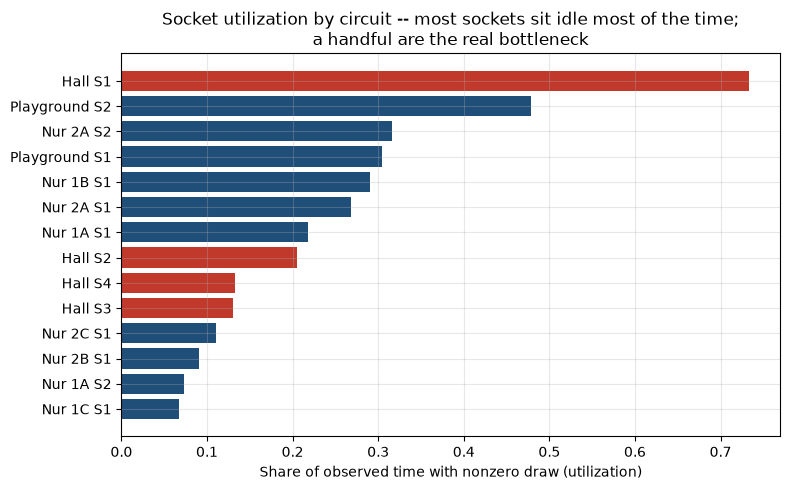

In [43]:
fig, ax = plt.subplots(figsize=(8,5))
colors = ["#c0392b" if s=="Hall" else "#1f4e79" for s in dev_util.site]
ax.barh(dev_util.device, dev_util.active_frac, color=colors)
ax.set_xlabel("Share of observed time with nonzero draw (utilization)")
ax.set_title("Socket utilization by circuit -- most sockets sit idle most of the time;\na handful are the real bottleneck")
plt.tight_layout()
plt.show()

**Findings.** Median socket use is about 18% at both sites, so there is no case for more sockets everywhere. Two circuits stand apart: **Hall S1 (73%)** and **Playground S2 (48%)**. Hall sockets carry most of the Hall's metered energy (191 kWh against 6.8 kWh for lighting), so S1 may be driving the Hall's demand growth; this should be checked before sizing any Hall expansion. Requests for a sound system and chairs are facilities needs that power data cannot size.

**What Part C says about Q2.** Supply is adequate at both sites. Service is impaired by specific failed fixtures and sockets, not by lack of energy. Needs cannot be judged per device at Kigeme until the unmetered 95% of load is identified.

---
# Part D. Spare capacity for additional services (Q3)
A new load is supported only if it passes three tests:
1. **Power:** AC load plus the new load stays under the 40 C inverter rating (and the VA rating) for at least 99% of the hours it runs. Headroom $H=P_{limit}-P_{AC}$ is reported as the time-weighted 5th percentile before the load is added. Start-up surges cannot be seen in 1 to 15 minute averages.
2. **Storage:** the battery carries it without breaching the reserve floor.
3. **Refill:** PV refills the battery by the next day.

Tests 2 and 3 use an **hourly replay**: measured load and calibrated PV are replayed with and without the new load, restarted from observed SOC each week, in a normal and a low-sun case (PV x 0.7). Comparing with and without cancels most model bias. A load is FEASIBLE if, in both cases, extra unserved energy is at most 0.5 kWh, days below floor rise by at most 2 points and full-recharge days fall by at most 5 points. Scenario loads follow the documented requests (laptops, phone charging, sound system, irons). A simple operating rule is also tested: run the load only while SOC is at least 85%.

## 9. Power test

In [44]:
SCENARIOS = [
    {"name": "6 laptops 09-13", "parts": [(300, 9, 4, 0.6)], "sites": NAMES, "rule": None},
    {"name": "6 laptops 09-13, only if SOC >= 85 %", "parts": [(300, 9, 4, 0.6)], "sites": NAMES, "rule": 85},
    {"name": "6 laptops 18-22", "parts": [(300, 18, 4, 0.6)], "sites": NAMES, "rule": None},
    {"name": "Phone charging 16-20 (20 x 8 W)", "parts": [(160, 16, 4, 0.6)], "sites": NAMES, "rule": None},
    {"name": "Sound system 200 W, 18-23", "parts": [(200, 18, 5, 0.8)], "sites": ["Nyabiheke Hall"], "rule": None},
    {"name": "1 iron 12-13", "parts": [(1000, 12, 1, 1.0)], "sites": NAMES, "rule": None},
    {"name": "2 irons 12-13", "parts": [(2000, 12, 1, 1.0)], "sites": NAMES, "rule": None},
]

def added_profile(sc):
    w, va = np.zeros(24), np.zeros(24)
    for watts, start, hrs, pf in sc["parts"]:
        for k in range(hrs):
            w[(start + k) % 24] += watts
            va[(start + k) % 24] += watts / pf
    return w, va

def weighted_quantile(x, weights, q):
    x, weights = np.asarray(x, float), np.asarray(weights, float)
    ok = np.isfinite(x) & (weights > 0)
    x, weights = x[ok], weights[ok]
    order = np.argsort(x)
    cum = np.cumsum(weights[order]) / weights.sum()
    return float(np.interp(q, cum, x[order]))

def power_check(n, sc):
    cfg = SITES[n]
    w, va = added_profile(sc)
    x = IV[n][IV[n]["ok"]]
    x = x[w[x["hour"].values] > 0]
    add, add_va, dt, ac = w[x["hour"].values], va[x["hour"].values], x["dt_h"].values, x["ac"].values
    return {"% time over 25C rating": 100 * np.average(ac + add > cfg["limit_25"], weights=dt),
            "% time over 40C rating": 100 * np.average(ac + add > cfg["limit_40"], weights=dt),
            "% time over VA rating": 100 * np.average(ac / PF_SYSTEM + add_va > cfg["va"], weights=dt),
            "5th pct headroom at 40C (W)": weighted_quantile(cfg["limit_40"] - ac, dt, 0.05)}

POWER_TAB = {}
for sc in SCENARIOS:
    for n in sc["sites"]:
        POWER_TAB[(n, sc["name"])] = power_check(n, sc)
POWER_TAB = pd.DataFrame(POWER_TAB).T
POWER_TAB.index.names = ["site", "scenario"]
display(POWER_TAB)
save(POWER_TAB, "09_power_check")

% time over 25C rating  % time over 40C rating  % time over VA rating  5th pct headroom at 40C (W)
site           scenario                                                                                                                                
Kigeme         6 laptops 09-13                                         0.09                    0.10                   0.10                       766.50
Nyabiheke Hall 6 laptops 09-13                                         0.00                    0.00                   0.00                     1,882.00
Kigeme         6 laptops 09-13, only if SOC >= 85 %                    0.09                    0.10                   0.10                       766.50
Nyabiheke Hall 6 laptops 09-13, only if SOC >= 85 %                    0.00                    0.00                   0.00                     1,882.00
Kigeme         6 laptops 18-22                                         0.00                    0.00                   0.00                       534.50
Nyabiheke Hall 6 laptops 18-22                                         0.00                    0.00                   0.00                     1,277.00
Kigeme         Phone charging 16-20 (20 x 8 W)                         0.00                    0.00                   0.00                       549.00
Nyabiheke Hall Phone charging 16-20 (20 x 8 W)                         0.00                    0.00                   0.00                     1,316.65
               Sound system 200 W, 18-23                               0.00                    0.00                   0.00                     1,287.50
Kigeme         1 iron 12-13                                          100.00                  100.00                   1.19                       781.00
Nyabiheke Hall 1 iron 12-13                                            0.01                    0.01                   0.00                     1,895.61
Kigeme         2 irons 12-13                                         100.00                  100.00                 100.00                       781.00
Nyabiheke Hall 2 irons 12-13                                           2.04                    7.32                   0.92                     1,895.61

### 9.1 Replay model
Each hour, PV potential x controller efficiency feeds the load first; surplus charges the battery until full and the rest is curtailed; any deficit is drawn from the battery, and below the 20% cut-off the energy is unserved. An effective-capacity multiplier and a charging efficiency are chosen by minimising the baseline SOC error against observed SOC.

,Kigeme,Nyabiheke Hall
cap_wh,"31,650.00","13,780.00"
cap_mult,1.50,1.30
eta_inv,0.95,0.85
eta_c,0.97,0.97
eta_chg,1.00,1.00
SOC RMSE (pts),3.36,3.73
SOC bias (pts),-1.67,-0.60


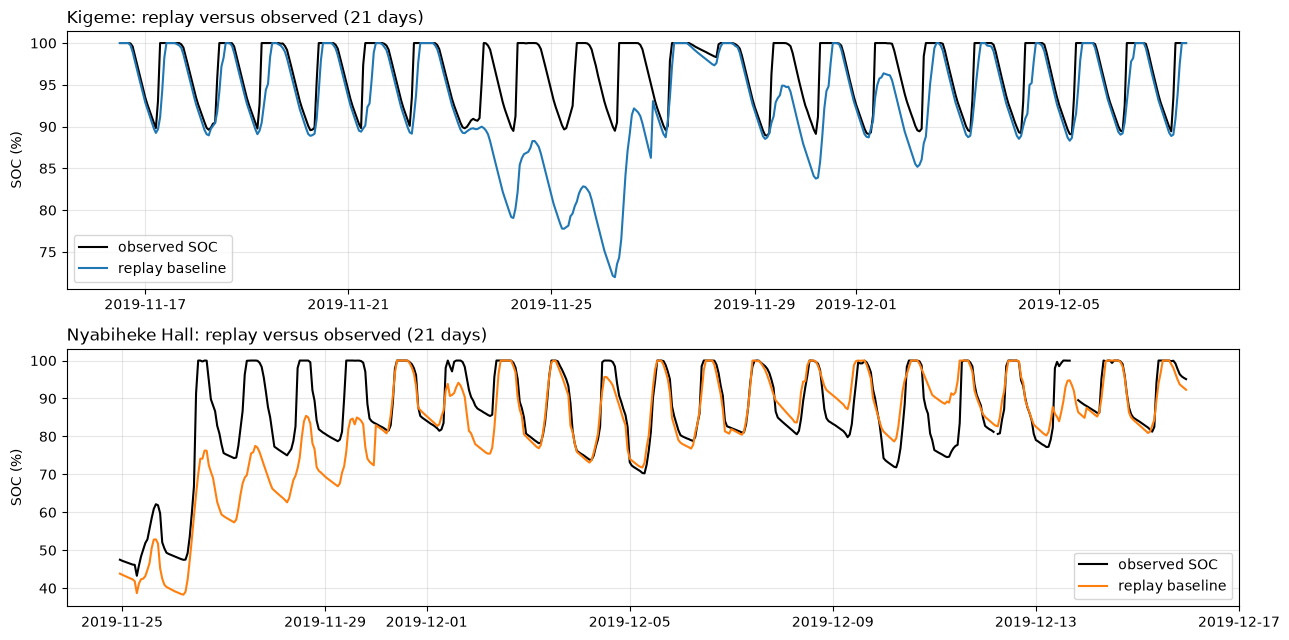

In [45]:
def replay_inputs(n):
    h = HOURLY[n]
    idx = pd.date_range(h.index.min().normalize(), h.index.max().ceil("h"), freq="h")
    b = h.reindex(idx)
    typical = h.groupby(["month", "hour"])["ac"].median().rename("typ")
    frame = pd.DataFrame({"month": idx.to_period("M"), "hour": idx.hour}, index=idx)
    fill = frame.join(typical, on=["month", "hour"])["typ"]
    ac = b["ac"].fillna(fill).fillna(h["ac"].median())
    return pd.DataFrame({"ac": ac, "pot": POT[n].reindex(idx).fillna(0), "soc": b["soc"]})

def simulate(inp, cap_wh, eta_inv, eta_c, eta_chg, add=None, pv_scale=1.0, rule=None):
    n = len(inp)
    ac, pot, obs = inp["ac"].values, inp["pot"].values * pv_scale, inp["soc"].values
    if add is None:
        add = np.zeros(n)
    soc = np.full(n, np.nan)
    unserved, extra_used, from_batt = np.zeros(n), np.zeros(n), np.zeros(n)
    cur = None
    for start in range(0, n, RESYNC_H):
        end = min(start + RESYNC_H, n)
        first = None
        for i in range(start, min(start + 48, end)):
            if not np.isnan(obs[i]):
                first = i
                break
        if first is None:
            if cur is None:
                continue
            first = start
        else:
            cur = obs[first]
        stored = cur / 100 * cap_wh
        for i in range(first, end):
            extra = add[i]
            if rule is not None and extra > 0 and stored / cap_wh * 100 < rule:
                extra = 0.0
            need = (ac[i] + extra) / eta_inv
            avail = pot[i] * eta_c
            direct = min(avail, need)
            surplus, deficit = avail - direct, need - direct
            if surplus > 0:
                stored += min(surplus, (cap_wh - stored) / eta_chg) * eta_chg
            if deficit > 0:
                give = min(deficit, max(stored - SOC_CUTOFF / 100 * cap_wh, 0))
                stored -= give
                from_batt[i] = give
                unserved[i] = (deficit - give) * eta_inv
            extra_used[i] = extra
            soc[i] = stored / cap_wh * 100
        cur = soc[end - 1] if not np.isnan(soc[end - 1]) else cur
    return pd.DataFrame({"soc": soc, "unserved": unserved, "extra_used": extra_used, "from_batt": from_batt}, index=inp.index)

INP, PARAMS = {}, {}
for n in NAMES:
    INP[n] = replay_inputs(n)
    cap0 = SITES[n]["batt_kwh"] * 1000
    rows = []
    for cm in [0.8, 1.0, 1.2, 1.3, 1.4, 1.5]:
        for ec in [0.85, 0.90, 0.95, 1.0]:
            s = simulate(INP[n], cap0 * cm, ETA_INV[n], ETA_C[n], ec)
            j = pd.concat([s["soc"], INP[n]["soc"]], axis=1, keys=["sim", "obs"]).dropna()
            rows.append({"cap_mult": cm, "eta_chg": ec, "rmse": rmse(j["sim"], j["obs"]), "bias": float((j["sim"] - j["obs"]).mean())})
    t = pd.DataFrame(rows)
    best = t.sort_values("rmse").iloc[0]
    PARAMS[n] = {"cap_wh": cap0 * best["cap_mult"], "cap_mult": best["cap_mult"], "eta_inv": ETA_INV[n], "eta_c": ETA_C[n],
                 "eta_chg": best["eta_chg"], "SOC RMSE (pts)": best["rmse"], "SOC bias (pts)": best["bias"]}
display(pd.DataFrame(PARAMS))

fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 6.5))
for a, n in zip(axes, NAMES):
    p = PARAMS[n]
    s = simulate(INP[n], p["cap_wh"], p["eta_inv"], p["eta_c"], p["eta_chg"])
    mid = INP[n].index[len(INP[n]) // 2]
    win = slice(mid, mid + pd.Timedelta(days=21))
    a.plot(INP[n]["soc"][win], color="k", label="observed SOC"); a.plot(s["soc"][win], color=SITES[n]["color"], label="replay baseline")
    a.set_ylabel("SOC (%)"); a.set_title(f"{n}: replay versus observed (21 days)", loc="left"); a.legend()
show_fig("09_replay_check")

In [46]:
def day_stats(sim):
    s = sim["soc"].dropna()
    g = s.groupby(s.index.normalize())
    cnt = g.size()
    return g.min()[cnt >= 20], g.max()[cnt >= 20]

def metrics(sim):
    lo, hi = day_stats(sim)
    return {"below floor %": 100 * (lo < FLOOR * 100).mean(), "recharged to 95 %": 100 * (hi >= 95).mean(),
            "unserved kWh": sim["unserved"].sum() / 1000, "battery kWh": sim["from_batt"].sum() / 1000,
            "lowest daily min (5th pct)": lo.quantile(0.05), "days": len(lo)}

rows = []
for n in NAMES:
    p = PARAMS[n]
    base = {}
    for lab, scale in [("normal", 1.0), ("stress", STRESS_PV)]:
        base[lab] = simulate(INP[n], p["cap_wh"], p["eta_inv"], p["eta_c"], p["eta_chg"], None, scale)
    for sc in SCENARIOS:
        if n not in sc["sites"]:
            continue
        prof, _ = added_profile(sc)
        add = prof[INP[n].index.hour.values]
        out = {}
        for lab, scale in [("normal", 1.0), ("stress", STRESS_PV)]:
            s = simulate(INP[n], p["cap_wh"], p["eta_inv"], p["eta_c"], p["eta_chg"], add, scale, sc["rule"])
            out[lab] = (metrics(s), metrics(base[lab]), s)
        m, b, s = out["normal"]
        ms, bs, _ = out["stress"]
        asked_kwh = add.sum() / 1000
        served = 100 * s["extra_used"].sum() / 1000 / asked_kwh if asked_kwh else np.nan
        pw = POWER_TAB.loc[(n, sc["name"])]

        def fails(m, b):
            f = []
            if m["unserved kWh"] - b["unserved kWh"] > 0.5: f.append("extra unserved > 0.5 kWh")
            if m["below floor %"] - b["below floor %"] > 2: f.append("days below floor up > 2 pts")
            if m["recharged to 95 %"] < b["recharged to 95 %"] - 5: f.append("full-recharge days down > 5 pts")
            return f

        fn, fs = fails(m, b), fails(ms, bs)
        power_ok = pw["% time over 40C rating"] <= 1 and pw["% time over VA rating"] <= 1
        if not power_ok:
            verdict = "POWER-LIMITED"
        elif not fn and not fs:
            verdict = "FEASIBLE"
        elif not fn:
            verdict = "FEASIBLE, fragile in low-sun weeks"
        else:
            verdict = "ENERGY-LIMITED"
        rows.append({"site": n, "scenario": sc["name"], "added kWh/day": sum(w_ * h_ for w_, s_, h_, pf_ in sc["parts"]) / 1000,
                     "% time over 40C limit": pw["% time over 40C rating"], "extra load actually served %": served,
                     "days below floor % (base)": b["below floor %"], "(with)": m["below floor %"],
                     "full-recharge % (base)": b["recharged to 95 %"], "(with) ": m["recharged to 95 %"],
                     "extra unserved kWh": m["unserved kWh"] - b["unserved kWh"],
                     "STRESS days below floor %": ms["below floor %"], "STRESS extra unserved kWh": ms["unserved kWh"] - bs["unserved kWh"],
                     "verdict": verdict})
RESULT = pd.DataFrame(rows).set_index(["site", "scenario"])
display(RESULT)
save(RESULT, "09_scenario_results")
print("Verdict rules: POWER-LIMITED if the load pushes AC above the 40 C rating (or VA rating) for more than 1 % of the time it runs. Otherwise FEASIBLE needs, in both the normal and stress replay: extra unserved energy <= 0.5 kWh, days-below-floor up by <= 2 points, and full-recharge days down by <= 5 points.")

added kWh/day  % time over 40C limit  extra load actually served %  days below floor % (base)  (with)  full-recharge % (base)  (with)   \
site           scenario                                                                                                                                                                       
Kigeme         6 laptops 09-13                                1.20                   0.10                         98.99                       0.00    0.00                   95.17    84.01   
               6 laptops 09-13, only if SOC >= 85 %           1.20                   0.10                         93.32                       0.00    0.00                   95.17    86.25   
               6 laptops 18-22                                1.20                   0.00                         99.63                       0.00    0.00                   95.17    84.39   
               Phone charging 16-20 (20 x 8 W)                0.64                   0.00                         99.63                       0.00    0.00                   95.17    90.71   
               1 iron 12-13                                   1.00                 100.00                         99.27                       0.00    0.00                   95.17    86.99   
               2 irons 12-13                                  2.00                 100.00                         99.27                       0.00    0.00                   95.17    78.07   
Nyabiheke Hall 6 laptops 09-13                                1.20                   0.00                        100.00                       1.56    6.64                   94.53    80.47   
               6 laptops 09-13, only if SOC >= 85 %           1.20                   0.00                         85.06                       1.56    1.56                   94.53    86.72   
               6 laptops 18-22                                1.20                   0.00                        100.00                       1.56    7.42                   94.53    82.03   
               Phone charging 16-20 (20 x 8 W)                0.64                   0.00                        100.00                       1.56    4.30                   94.53    91.41   
               Sound system 200 W, 18-23                      1.00                   0.00                        100.00                       1.56    5.47                   94.53    86.33   
               1 iron 12-13                                   1.00                   0.01                        100.00                       1.56    4.30                   94.53    84.38   
               2 irons 12-13                                  2.00                   7.32                        100.00                       1.56   12.11                   94.53    67.19   

                                                     extra unserved kWh  STRESS days below floor %  STRESS extra unserved kWh                             verdict  
site           scenario                                                                                                                                            
Kigeme         6 laptops 09-13                                     0.00                       2.97                       0.00                      ENERGY-LIMITED  
               6 laptops 09-13, only if SOC >= 85 %                0.00                       0.00                       0.00                      ENERGY-LIMITED  
               6 laptops 18-22                                     0.00                       3.35                       0.00                      ENERGY-LIMITED  
               Phone charging 16-20 (20 x 8 W)                     0.00                       0.00                       0.00  FEASIBLE, fragile in low-sun weeks  
               1 iron 12-13                                        0.00                       1.86                       0.00                       POWER-LIMITED  
               2 irons 12-13           

Verdict rules: POWER-LIMITED if the load pushes AC above the 40 C rating (or VA rating) for more than 1 % of the time it runs. Otherwise FEASIBLE needs, in both the normal and stress replay: extra unserved energy <= 0.5 kWh, days-below-floor up by <= 2 points, and full-recharge days down by <= 5 points.


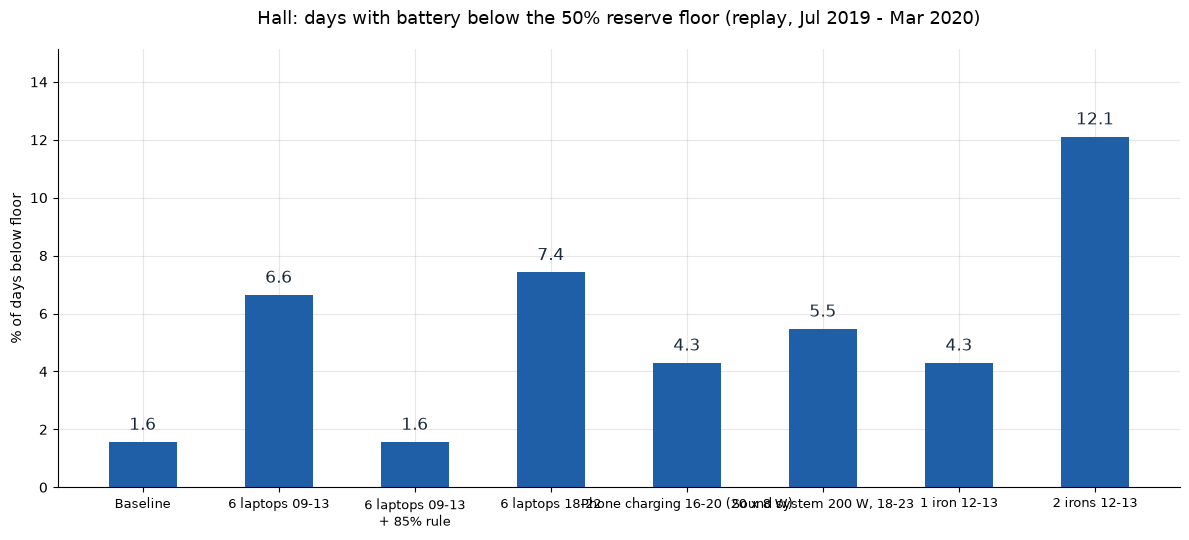

In [47]:
hall = RESULT.loc["Nyabiheke Hall"]
labels = ["Baseline"] + [s.replace(", only if SOC >= 85 %", "\n+ 85% rule") for s in hall.index]
vals = [hall["days below floor % (base)"].iloc[0]] + list(hall["(with)"].values)
fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(labels, vals, color="#1F5FA8", width=0.5)
ax.bar_label(bars, fmt="%.1f", padding=6, fontsize=12, color="#1b2a3a")
ax.set_ylim(0, max(vals) * 1.25); ax.set_ylabel("% of days below floor")
ax.tick_params(axis="x", labelsize=9)
ax.set_title(f"Hall: days with battery below the {FLOOR:.0%} reserve floor (replay, Jul 2019 - Mar 2020)", pad=18, fontsize=13)
ax.set_axisbelow(True); ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
show_fig("slide_hall_days_below_floor")

**Findings.** The replay tracks observed SOC within 3.4 points (Kigeme) and 3.7 points (Hall).
- **Kigeme:** no scenario breaches the floor or leaves unserved energy, but daytime laptops cut full-recharge days from 95% to 84%, so the strict rule classes them energy-limited. Phone charging is feasible but fragile in low-sun weeks. Irons are power-limited: one 1,000 W iron already exceeds the 781 W headroom.
- **Hall:** six laptops without a rule raise days below the 50% floor from 1.6% to 6.6% and leave 2.2 kWh unserved; in low sun, 20% of days fall below the floor with 30 kWh unserved. The 85% rule holds days below floor at 1.6% with no unserved energy and still delivers 85% of the service, but full-recharge days fall from 94.5% to 86.7%, so it is a mitigation, not a pass. Every evening load and both iron cases are energy- or power-limited.

### 9.2 Reserve-floor sensitivity (the one assumption flipped)
Spare energy at dawn = (morning SOC minus floor) x capacity x inverter efficiency, for the Hall, with everything else fixed.

morning SOC,10th pct,5th pct,median
floor,,,
0.50,2.43,2.12,3.65
0.60,1.52,1.21,2.75
0.70,0.62,0.31,1.85


256 mornings; median 90.4 %, 5th percentile 73.4 %; inverter efficiency used 0.85 (lecture example 0.90).


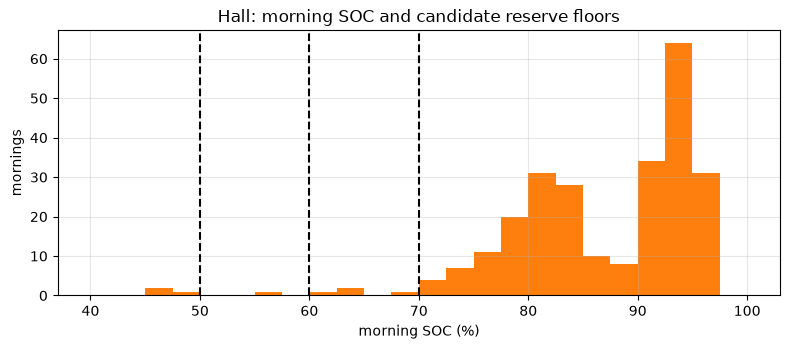

In [48]:
n = "Nyabiheke Hall"
mor = morning_soc = DF[n][(DF[n]["time"].dt.hour >= 5) & (DF[n]["time"].dt.hour < 9) & (DF[n]["pv"] >= 20)]
mor = mor.groupby(mor["time"].dt.normalize())["soc"].first()
cap = SITES[n]["batt_kwh"]
rows = []
for floor in [0.5, 0.6, 0.7]:
    for lab, q in [("median", 0.5), ("10th pct", 0.10), ("5th pct", 0.05)]:
        s = mor.quantile(q) / 100
        add = ETA_INV[n] * cap * max(s - floor, 0)
        rows.append({"floor": floor, "morning SOC": lab, "SOC %": s * 100, "spare AC kWh": add, "covers 1.2 kWh": add >= 1.2})
FLOOR_TAB = pd.DataFrame(rows)
display(FLOOR_TAB.pivot(index="floor", columns="morning SOC", values="spare AC kWh"))
print(f"{len(mor)} mornings; median {mor.median():.1f} %, 5th percentile {mor.quantile(0.05):.1f} %; inverter efficiency used {ETA_INV[n]:.2f} (lecture example 0.90).")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(mor, bins=np.arange(40, 101, 2.5), color="tab:orange")
for f in (0.5, 0.6, 0.7):
    ax.axvline(f * 100, ls="--", color="k")
ax.set_xlabel("morning SOC (%)"); ax.set_ylabel("mornings"); ax.set_title("Hall: morning SOC and candidate reserve floors")
show_fig("09_morning_soc")

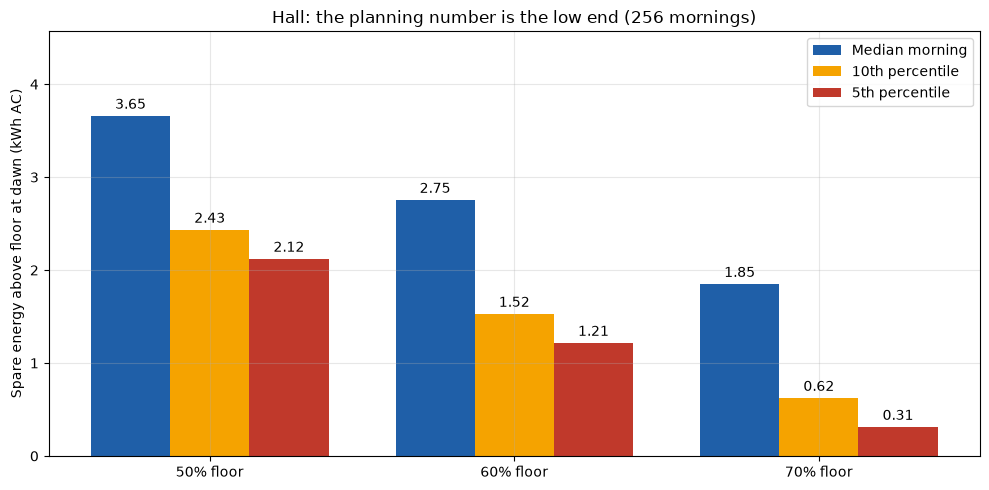

In [49]:
BLUE, AMBER, RED = "#1F5FA8", "#F5A300", "#C0392B"
piv = FLOOR_TAB.pivot(index="floor", columns="morning SOC", values="spare AC kWh")
x, w = np.arange(len(piv)), 0.26
fig, ax = plt.subplots(figsize=(10, 5))
bs = [ax.bar(x + (i - 1) * w, piv[col].values, w, color=c, label=l)
      for i, (col, c, l) in enumerate([("median", BLUE, "Median morning"), ("10th pct", AMBER, "10th percentile"), ("5th pct", RED, "5th percentile")])]
ax.set_ylim(0, piv.values.max() * 1.25); ax.set_xticks(x); ax.set_xticklabels([f"{f:.0%} floor" for f in piv.index])
ax.set_ylabel("Spare energy above floor at dawn (kWh AC)")
ax.set_title(f"Hall: the planning number is the low end ({len(mor)} mornings)"); ax.legend()
for b in bs:
    label_bars(ax, b, "{:.2f}")
show_fig("slide_hall_headroom_by_floor")

**Findings.** With a median morning SOC of 90.4% and a 5th percentile of 73.4%, moving the floor from 50% to 70% cuts the 5th-percentile spare energy from 2.12 to 0.31 kWh, turning "six laptops fit" into "they do not". The planning range is 0.31 to 3.65 kWh, and a 1.2 kWh load is the same size as the roughly 1 kWh uncertainty from plus or minus 10 SOC points.

### 9.3 Daytime surplus by a second method
Each day's surplus (measured PV minus AC) is split at the moment the battery first reaches 99% SOC. After that point the controller is throttling, so the surplus is free. Measured PV is already throttled, so this understates the Hall; at Kigeme it can exceed the calibrated-potential estimate, which rests on a factor fitted mostly on mornings. Neither bounds the other, so the two are quoted as a range.

In [50]:
def load_full(path):
    df = pd.read_csv(path, parse_dates=["Timestamp (Africa/Kigali)"]).rename(columns={
        "Timestamp (Africa/Kigali)": "ts", "Solar Charger PV Power (W)": "pv_w",
        "System Overview AC Consumption (W)": "ac_w", "Battery Monitor State of Charge (%)": "soc",
        "System Overview Battery Power (W)": "batt_w"})
    return df[["ts","pv_w","ac_w","soc","batt_w"]].dropna(subset=["pv_w","ac_w","soc"])

mg_full = load_full(MG_DIR / "System_data.csv")
hl_full = load_full(HL_DIR / "System_data.csv")

def saturation_budget(d):
    d = d.sort_values("ts").copy()
    d["date"] = d.ts.dt.date
    d["surplus_w"] = d.pv_w - d.ac_w
    recs = []
    for date, g in d.groupby("date"):
        g = g.sort_values("ts")
        day = g[(g.ts.dt.hour >= 5) & (g.ts.dt.hour <= 18)]
        if len(day) < 20:
            continue
        sat_rows = day[day.soc >= 99]
        sat_time = sat_rows.ts.min() if len(sat_rows) else pd.NaT
        day = day.copy()
        day["dt_h"] = day.ts.diff().dt.total_seconds().fillna(0) / 3600
        day.loc[day.dt_h > 1, "dt_h"] = np.nan
        before = day[day.ts < sat_time] if pd.notna(sat_time) else day
        after = day[day.ts >= sat_time] if pd.notna(sat_time) else day.iloc[0:0]
        free_kwh = (after.surplus_w.clip(lower=0) * after.dt_h).sum() / 1000
        soft_kwh = (before.surplus_w.clip(lower=0) * before.dt_h).sum() / 1000
        recs.append({"date": date, "saturates": pd.notna(sat_time),
                     "sat_hour": sat_time.hour + sat_time.minute/60 if pd.notna(sat_time) else np.nan,
                     "free_kwh": free_kwh, "soft_kwh": soft_kwh})
    return pd.DataFrame(recs)

mg_sat = saturation_budget(mg_full)
hl_sat = saturation_budget(hl_full)

for name, r in [("Kigeme (Microgrid)", mg_sat), ("Nyabiheke (Hall)", hl_sat)]:
    print(f"--- {name} ---")
    print(f"Days analyzed: {len(r)} | battery reaches >=99% SOC during the day on "
          f"{r.saturates.mean()*100:.0f}% of them")
    print(f"Median time of day the battery first hits ~full: {r[r.saturates].sat_hour.median():.1f}h")
    print(f"FREE surplus (after the battery is already full): {r.free_kwh.mean():.2f} kWh/day")
    print(f"SOFT surplus (before saturation, still charging the battery): {r.soft_kwh.mean():.2f} kWh/day")
    print()

--- Kigeme (Microgrid) ---
Days analyzed: 269 | battery reaches >=99% SOC during the day on 100% of them
Median time of day the battery first hits ~full: 7.8h
FREE surplus (after the battery is already full): 3.70 kWh/day
SOFT surplus (before saturation, still charging the battery): 0.33 kWh/day

--- Nyabiheke (Hall) ---
Days analyzed: 256 | battery reaches >=99% SOC during the day on 98% of them
Median time of day the battery first hits ~full: 8.4h
FREE surplus (after the battery is already full): 1.58 kWh/day
SOFT surplus (before saturation, still charging the battery): 0.67 kWh/day



The battery is full by a median of 07:48 (Kigeme) and 08:24 (Hall). This method gives 3.70 kWh/day at Kigeme and 1.58 kWh/day at the Hall, so unused solar is **3.1 to 3.7 kWh/day at Kigeme and 1.6 to 3.1 at the Hall**.

### 9.4 Night-time reserve at dawn, by month
The nine-month mean above a generous 30% floor hides the Hall's seasonal squeeze, so headroom is also broken down by month and floor.

In [51]:
NAMEPLATE_KWH = {"Microgrid": 21.1, "Hall": 10.6}
RESERVE_FLOOR = 30

def night_budget(d, name):
    d = d.sort_values("ts").set_index("ts")
    hourly_soc = d["soc"].resample("h").mean()
    hourly_ac = d["ac_w"].resample("h").mean()
    evening = hourly_soc[hourly_soc.index.hour == 18].rename("soc_evening")
    dawn = hourly_soc[hourly_soc.index.hour == 6].rename("soc_dawn")
    night_ac = [hourly_ac.loc[ts: ts + pd.Timedelta(hours=12)].mean() for ts in evening.index]
    ev = pd.DataFrame({"soc_evening": evening.values, "night_mean_ac_w": night_ac}, index=evening.index)
    dn = dawn.to_frame(); dn.index = dn.index - pd.Timedelta(hours=12)
    m = ev.join(dn, how="inner").dropna()
    m["night_ac_kwh"] = m.night_mean_ac_w * 12 / 1000
    m["headroom_kwh"] = (m.soc_dawn - RESERVE_FLOOR).clip(lower=0) / 100 * NAMEPLATE_KWH[name]
    return m

mg_night = night_budget(mg_full, "Microgrid")
hl_night = night_budget(hl_full, "Hall")

for name, m, key in [("Kigeme", mg_night, "Microgrid"), ("Nyabiheke", hl_night, "Hall")]:
    print(f"--- {name} (nameplate {NAMEPLATE_KWH[key]} kWh, {RESERVE_FLOOR}% reserve floor) ---")
    print(f"Nights analyzed: {len(m)} | Mean dawn SOC: {m.soc_dawn.mean():.1f}%")
    print(f"Mean current night AC draw: {m.night_ac_kwh.mean():.2f} kWh/night")
    print(f"Mean unused headroom above the reserve floor, at dawn: {m.headroom_kwh.mean():.2f} kWh")
    print(f"Nights where dawn SOC already fell below the floor: {(m.soc_dawn < RESERVE_FLOOR).mean()*100:.1f}%")
    print()

--- Kigeme (nameplate 21.1 kWh, 30% reserve floor) ---
Nights analyzed: 266 | Mean dawn SOC: 90.0%
Mean current night AC draw: 2.86 kWh/night
Mean unused headroom above the reserve floor, at dawn: 12.66 kWh
Nights where dawn SOC already fell below the floor: 0.0%

--- Nyabiheke (nameplate 10.6 kWh, 30% reserve floor) ---
Nights analyzed: 255 | Mean dawn SOC: 86.8%
Mean current night AC draw: 1.29 kWh/night
Mean unused headroom above the reserve floor, at dawn: 6.02 kWh
Nights where dawn SOC already fell below the floor: 0.0%



In [52]:
for name, m, key in [("Kigeme", mg_night, "Microgrid"), ("Nyabiheke Hall", hl_night, "Hall")]:
    mm = m.copy()
    mm["month"] = mm.index.to_period("M")
    tab = mm.groupby("month").agg(
        nights=("soc_dawn", "size"),
        mean_dawn_soc=("soc_dawn", "mean"),
        headroom_kwh_at_30pct=("headroom_kwh", "mean"),
        pct_nights_dawn_below_85=("soc_dawn", lambda s: (s < 85).mean() * 100),
    ).round(2)
    print(f"--- {name}: by month ---")
    print(tab.to_string())
    print(f"--- {name}: mean unused energy at dawn for different reserve floors (nameplate {NAMEPLATE_KWH[key]} kWh) ---")
    for floor in (30, 50, 70):
        h_ = ((m.soc_dawn - floor).clip(lower=0) / 100 * NAMEPLATE_KWH[key]).mean()
        print(f"  floor {floor}%: {h_:.2f} kWh")
    print()

--- Kigeme: by month ---
         nights  mean_dawn_soc  headroom_kwh_at_30pct  pct_nights_dawn_below_85
month                                                                          
2019-07      30          88.29                  12.30                      0.00
2019-08      31          88.40                  12.32                      0.00
2019-09      23          91.77                  13.03                      0.00
2019-10      31          88.84                  12.42                      0.00
2019-11      30          91.81                  13.04                      0.00
2019-12      31          90.98                  12.87                      0.00
2020-01      31          89.55                  12.56                      3.23
2020-02      29          90.27                  12.72                      0.00
2020-03      30          90.74                  12.82                      0.00
--- Kigeme: mean unused energy at dawn for different reserve floors (nameplate 21.1 kWh) ---
  

**Findings.** Kigeme's headroom is large and flat across months. The Hall's mean headroom of 6.0 kWh above a 30% floor drops to 5.3 to 5.5 kWh from November to February, when 60 to 93% of dawns start below 85%. The planning number for the Hall is the low end, not the mean.

**What Part D says about Q3.** Daytime 10:00 to 15:00 is the opportunity. Kigeme can take daytime loads without unserved energy, at the cost of fewer full-recharge days. The Hall needs the 85% rule and is tight from November to February. Evening loads draw straight from the battery and are the worst option. Irons are out at Kigeme, and two irons are out at the Hall. Each extra metered socket uses 50 to 75 Wh/day.

---
# Part E. Findings, answers and recommendations
## 10. Key results from this run

In [53]:
L = []
for n in NAMES:
    L.append(f"**{n}** | PV {HEAD.loc['PV kWh/day', n]:.1f} vs AC {HEAD.loc['AC kWh/day', n]:.1f} kWh/day (PV/AC {HEAD.loc['PV / AC', n]:.2f}); "
             f"Y_A {HEAD.loc['Y_A kWh/kWp/day', n]:.2f}, Y_F {HEAD.loc['Y_F kWh/kWp/day', n]:.2f} kWh/kWp/day; "
             f"controller {100 * HEAD.loc['eta controller', n]:.0f} %, inverter {100 * HEAD.loc['eta inverter (inferred)', n]:.0f} %, BoS {100 * HEAD.loc['eta BoS', n]:.0f} %.")
    L.append(f"   Battery: lowest SOC {BATT.loc['lowest SOC (%)', n]:.1f} %, time at 99 %+ {100 * BATT.loc['time at SOC >= 99 %', n]:.0f} %, "
             f"apparent capacity {BATT.loc['apparent / nominal', n]:.2f} x nominal. Availability (observed) {100 * AVAIL.loc['availability (observed hours)', n]:.1f} %, "
             f"longest zero-AC event {AVAIL.loc['longest zero (h)', n]:.0f} h.")
    L.append(f"   Unused PV: {CURT[n].loc['TOTAL', 'unused % of potential']:.0f} % of potential ({METHOD[n]}).")
    if n in KFIT:
        L.append(f"   PV factor k = {KFIT[n]['k']:.2f} (95 % CI {KFIT[n]['k 95% low']:.2f}-{KFIT[n]['k 95% high']:.2f}); RMSE {KFIT[n]['RMSE before (W)']:.0f} W -> {KFIT[n]['RMSE after, cross-validated (W)']:.0f} W.")
    best = WINDOWS[n]["median kWh/day"].idxmax()
    L.append(f"   Best 4-hour surplus window {best}: median {WINDOWS[n].loc[best, 'median kWh/day']:.2f} kWh/day, at least 1.2 kWh on {WINDOWS[n].loc[best, '% days >= 1.2 kWh']:.0f} % of days.")
L.append("")
for (n, name), r in RESULT.iterrows():
    L.append(f"- {n}, {name}: **{r['verdict']}**; adds {r['added kWh/day']:.2f} kWh/day, served {r['extra load actually served %']:.0f} % of the requested hours, "
             f"extra unserved {r['extra unserved kWh']:.2f} kWh (stress {r['STRESS extra unserved kWh']:.2f} kWh), time over 40 C limit {r['% time over 40C limit']:.1f} %.")
display(Markdown("\n\n".join(L)))

**Kigeme** | PV 5.0 vs AC 4.2 kWh/day (PV/AC 1.20); Y_A 2.00, Y_F 1.67 kWh/kWp/day; controller 97 %, inverter 95 %, BoS 83 %.

   Battery: lowest SOC 78.8 %, time at 99 %+ 47 %, apparent capacity 1.50 x nominal. Availability (observed) 96.2 %, longest zero-AC event 116 h.

   Unused PV: 42 % of potential (PVGIS x k).

   PV factor k = 0.71 (95 % CI 0.66-0.76); RMSE 218 W -> 152 W.

   Best 4-hour surplus window 11:00-15:00: median 2.11 kWh/day, at least 1.2 kWh on 70 % of days.

**Nyabiheke Hall** | PV 3.1 vs AC 2.4 kWh/day (PV/AC 1.31); Y_A 1.51, Y_F 1.16 kWh/kWp/day; controller 97 %, inverter 85 %, BoS 76 %.

   Battery: lowest SOC 42.3 %, time at 99 %+ 40 %, apparent capacity 1.15 x nominal. Availability (observed) 99.9 %, longest zero-AC event 2 h.

   Unused PV: 50 % of potential (PVGIS x k).

   PV factor k = 0.69 (95 % CI 0.68-0.71); RMSE 310 W -> 156 W.

   Best 4-hour surplus window 11:00-15:00: median 2.04 kWh/day, at least 1.2 kWh on 71 % of days.



- Kigeme, 6 laptops 09-13: **ENERGY-LIMITED**; adds 1.20 kWh/day, served 99 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 0.1 %.

- Kigeme, 6 laptops 09-13, only if SOC >= 85 %: **ENERGY-LIMITED**; adds 1.20 kWh/day, served 93 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 0.1 %.

- Kigeme, 6 laptops 18-22: **ENERGY-LIMITED**; adds 1.20 kWh/day, served 100 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 0.0 %.

- Kigeme, Phone charging 16-20 (20 x 8 W): **FEASIBLE, fragile in low-sun weeks**; adds 0.64 kWh/day, served 100 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 0.0 %.

- Kigeme, 1 iron 12-13: **POWER-LIMITED**; adds 1.00 kWh/day, served 99 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 100.0 %.

- Kigeme, 2 irons 12-13: **POWER-LIMITED**; adds 2.00 kWh/day, served 99 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 100.0 %.

- Nyabiheke Hall, 6 laptops 09-13: **ENERGY-LIMITED**; adds 1.20 kWh/day, served 100 % of the requested hours, extra unserved 2.24 kWh (stress 29.98 kWh), time over 40 C limit 0.0 %.

- Nyabiheke Hall, 6 laptops 09-13, only if SOC >= 85 %: **ENERGY-LIMITED**; adds 1.20 kWh/day, served 85 % of the requested hours, extra unserved 0.00 kWh (stress 0.00 kWh), time over 40 C limit 0.0 %.

- Nyabiheke Hall, 6 laptops 18-22: **ENERGY-LIMITED**; adds 1.20 kWh/day, served 100 % of the requested hours, extra unserved 3.40 kWh (stress 33.36 kWh), time over 40 C limit 0.0 %.

- Nyabiheke Hall, Phone charging 16-20 (20 x 8 W): **ENERGY-LIMITED**; adds 0.64 kWh/day, served 100 % of the requested hours, extra unserved 0.00 kWh (stress 12.46 kWh), time over 40 C limit 0.0 %.

- Nyabiheke Hall, Sound system 200 W, 18-23: **ENERGY-LIMITED**; adds 1.00 kWh/day, served 100 % of the requested hours, extra unserved 0.85 kWh (stress 25.06 kWh), time over 40 C limit 0.0 %.

- Nyabiheke Hall, 1 iron 12-13: **ENERGY-LIMITED**; adds 1.00 kWh/day, served 100 % of the requested hours, extra unserved 0.85 kWh (stress 23.18 kWh), time over 40 C limit 0.0 %.

- Nyabiheke Hall, 2 irons 12-13: **POWER-LIMITED**; adds 2.00 kWh/day, served 100 % of the requested hours, extra unserved 19.27 kWh (stress 87.81 kWh), time over 40 C limit 7.3 %.

## E.1 Answers to the case questions

### Q1. Is the system performing as expected?
**The energy system performs as expected; the service built on it does not fully.**
- Controller about 97% at both sites; Kigeme inverter 95%; integrated energy matches the counters.
- Low PV yield is throttling, not a fault: 42 to 50% of calibrated potential goes unused, and in un-throttled hours PV is about 70% of PVGIS at both sites, pointing first to model geometry.

Needs action:
1. Nursery 2B `CPE10` dark from 29 Oct 2019 to March 2020 (27 of 93 weeks).
2. Nursery 2 and the playground hold 88% of Kigeme anomalies; playground CPE4 and sockets and Streetlight 1 match the 23 March checksheet.
3. Kigeme outage: about 170 h of recorded zero AC at 100% SOC (4 to 12 Sept), then a 144.7 h data gap.
4. Hall inverter about 85% (inferred); light load explains part, not all.
5. Kigeme load spikes to 3.1 kW against a 960 W continuous rating.
6. Battery monitor unreliable: morning re-syncs of 8 to 16 points, apparent capacity 1.5x nominal.

### Q2. Is it meeting current service needs?
**Supply: yes at both sites. Service: partly. The data cannot show who had access.**
- Kigeme never below 78.8% SOC; the lighting timetable is visible in the load.
- Hall supply held, but the margin is shrinking: demand rose from 0.95 to 2.15 kWh/day, most Nov to Feb nights end below 85%, and the 42.3% low on 25 Nov came from weak sun plus high demand.
- Service gaps are maintenance gaps: specific fixtures and sockets are out, and fault reports stayed open across three checksheets.
- Median socket use about 18%; only Hall S1 (73%) and Playground S2 (48%) are under pressure.

### Q3. Could spare capacity support additional services with limited investment?
**Yes for daytime services, through operating rules and repairs rather than hardware. No for evening loads or irons without changes.**
- Unused PV peaks 11:00 to 15:00 (median about 2 kWh/day); 1.2 kWh is available on about 70% of days at both sites.
- Kigeme absorbs daytime loads with no unserved energy; the Hall needs the 85% rule and is tight from November to February.
- The cheapest extra capacity is the service already lost to unrepaired faults.

## E.2 Recommendations, cheapest first

| # | Recommendation | Audience | Basis | Confidence |
|---|---|---|---|---|
| 1 | Repair `CPE10`, playground CPE4 and sockets, Streetlight 1; audit Nursery 2 wiring | O&M staff | B.1 to B.4 | Evidenced |
| 2 | Add a repair-closure step to checksheets; give streetlights a night-only baseline | O&M staff | B.4 | Judgment |
| 3 | Schedule new flexible load for 10:00 to 15:00; at the Hall run it only while SOC is at least 85% | Facility managers | 6.2, 9.1 | Evidenced |
| 4 | Avoid evening loads (laptops 18:00 to 22:00, sound system) | Facility managers | 9.1 | Evidenced |
| 5 | Add sockets only at Hall S1 and Playground S2; budget 50 to 75 Wh/day per extra meter | Facility managers | C.2 | Evidenced |
| 6 | Investigate the Kigeme 4 to 18 Sept outage (logbook, inverter event log, breaker) | O&M staff | 7.1 | Evidenced |
| 7 | Measure the Hall inverter at its DC terminals; check the model (48/3000 vs 24/3000 curve) | Technical support | 3.1 | Cause unknown |
| 8 | Check the battery monitor capacity setting against the nameplate; run a direct capacity test; plan with plus or minus 10 SOC points | Technical support | 5, 7.2 | Evidenced |
| 9 | No irons at Kigeme without a larger inverter; never two at once at the Hall | Facility managers | 7.4, 9 | Provisional |
| 10 | Do not buy trackers, panels or storage now; re-assess the Hall after a second Nov to Feb season | Funders | 6, 9.4 | Judgment |
| 11 | Pilot new daytime services at Kigeme first | Facility managers | 9.1, 9.4 | Judgment |
| 12 | Map the unmetered 95% of Kigeme load; collect logbooks and user feedback | Technical support | 8.1 | Evidenced gap |

## E.3 Limitations and the evidence that would resolve them

| Limitation | Evidence that would resolve it |
|---|---|
| No battery-voltage or inverter-alarm channel; a low-voltage cut-off cannot be confirmed | Battery terminal voltage, inverter event log |
| SOC is a monitor estimate that re-syncs; apparent capacity exceeds nameplate | Monitor capacity setting, nameplate, direct capacity test |
| PVGIS geometry assumed (10 degrees, north); coordinates approximate | Surveyed tilt and azimuth, shading and soiling records |
| Unused PV is modelled, not measured | Controller state or curtailment log |
| Calibration hours are morning-heavy (Kigeme: 6 hours after 11:00) | Irradiance measurements, a full year of data |
| Kigeme AC peaks exceed the stated rating; battery 21.1 vs 19.2 kWh | Inverter and battery nameplates, installation record |
| Replay is hourly: no start-up surges or intra-hour peaks | Manufacturer surge ratings, sub-minute load data |
| Appliance loads are illustrative | Counts, ratings and hours agreed with users |
| Fault rule is a threshold (more than 95% dark and 25 points above baseline) | Checksheet confirmation of flagged weeks |
| Service quality and access are not visible electrically | Checksheets, logbooks, user feedback, opening hours |
| Only 9 months; Hall demand still rising | A second November to February season |

**Sources.** Nixon et al. (2021) and system diagrams; Zenodo record 4304799; PVGIS (JRC); Victron inverter, GEL battery and BlueSolar datasheets; CMU 04-782 Lecture 12.

---
## Appendix. Numbers quoted in the technical report
Every figure cited in the report, recomputed in this run and saved to `outputs/report_numbers.csv`.

In [54]:
REP = []
def rep(section, item, value, unit=""):
    REP.append({"section": section, "item": item, "value": value, "unit": unit})

K, H = "Kigeme", "Nyabiheke Hall"
for n in NAMES:
    r = RAW[n]
    rep("3 Data", f"{n}: raw rows", len(r), "rows")
    rep("3 Data", f"{n}: repeated timestamps", int(AUDIT.loc["repeated timestamps", n]), "rows")
    rep("3 Data", f"{n}: readings after merging repeats", len(DF[n]), "rows")
    rep("3 Data", f"{n}: first timestamp", str(r["time"].min()))
    rep("3 Data", f"{n}: last timestamp", str(r["time"].max()))
    rep("3 Data", f"{n}: usable share of span", round(100 * AUDIT.loc["usable share of span", n], 1), "%")
    rep("3 Data", f"{n}: complete days / days observed", f"{int(DAILY[n]['complete'].sum())} / {len(DAILY[n])}")
    s = SENS.loc[n]
    base = s.loc["duplicate rule = mean", "AC kWh"]
    rep("3 Data", f"{n}: max change in AC energy from duplicate rule", round(100 * (s.filter(like="duplicate", axis=0)["AC kWh"] - base).abs().max() / base, 3), "%")
    rep("3 Data", f"{n}: median meters / system AC", round(CROSS.loc[n, "median meters / system AC"], 3))
g = longest_gaps(RAW[K]).iloc[0]
rep("3 Data", "Kigeme longest gap", f"{g['gap start']} to {g['gap end']}")
rep("3 Data", "Kigeme longest gap (h)", round(g["hours"], 2), "h")

zk = ZERO[K]
sept = zk[(zk["start"] >= "2019-09-04") & (zk["start"] < "2019-09-13")]
rep("3 Data", "Kigeme recorded-zero events in Sept window", f"{sept['start'].min()} to {sept['end'].max()}")
rep("3 Data", "Kigeme recorded-zero hours, 4-12 Sept", round(sept["hours"].sum(), 1), "h")
for n in NAMES:
    seen, zh = AVAIL.loc["observed hours", n], AVAIL.loc["zero-AC hours", n]
    rep("3 Data", f"{n}: availability, all observed hours", round(100 * AVAIL.loc["availability (observed hours)", n], 2), "%")
    if n == K:
        ex = sept["hours"].sum()
        rep("3 Data", "Kigeme availability excluding 4-12 Sept event", round(100 * (1 - (zh - ex) / (seen - ex)), 2), "%")

for n in NAMES:
    cc = counter_check(DF[n], DAILY[n])
    for ref in ["Dis", "Chg"]:
        rep("4 Computation", f"{n}: counter/integrated {ref} median (p10-p90), days",
            f"{cc.loc['median counter / integrated', ref]:.3f} ({cc.loc['10th pct', ref]:.2f}-{cc.loc['90th pct', ref]:.2f}), {int(cc.loc['days compared', ref])}")
    rep("4 Computation", f"{n}: controller efficiency", round(100 * HEAD.loc["eta controller", n], 1), "%")
    rep("4 Computation", f"{n}: controller efficiency, monthly min-max", f"{100 * KPI[n]['eta controller'].min():.1f}-{100 * KPI[n]['eta controller'].max():.1f}", "%")
    rep("4 Computation", f"{n}: inverter efficiency (inferred)", round(100 * HEAD.loc["eta inverter (inferred)", n], 1), "%")
    rep("4 Computation", f"{n}: replay SOC RMSE", round(PARAMS[n]["SOC RMSE (pts)"], 2), "pts")

for n in [m for m in NAMES if m in KFIT]:
    kf = KFIT[n]
    rep("5 Benchmark", f"{n}: clock shift / best correlation", f"{kf['clock shift (h)']} h / {LAGS[n]['correlation'].max():.2f}")
    rep("5 Benchmark", f"{n}: k (95% CI, bootstrap over dates)", f"{kf['k']:.2f} ({kf['k 95% low']:.2f}-{kf['k 95% high']:.2f})")
    rep("5 Benchmark", f"{n}: calibration hours / days / hours >= 11:00", f"{kf['hours used']} / {kf['days used']} / {kf['hours>=11']}")
    kwp_w = SITES[n]["kwp"] * 1000
    rep("5 Benchmark", f"{n}: RMSE before -> after (W)", f"{kf['RMSE before (W)']:.0f} -> {kf['RMSE after, cross-validated (W)']:.0f}")
    rep("5 Benchmark", f"{n}: RMSE before -> after (% of kWp)", f"{100 * kf['RMSE before (W)'] / kwp_w:.1f} -> {100 * kf['RMSE after, cross-validated (W)'] / kwp_w:.1f}")
    rep("5 Benchmark", f"{n}: inverter eff below 100 W / above 250 W", f"{100 * LIGHT.loc['efficiency below 100 W', n]:.0f} / {100 * LIGHT.loc['efficiency above 250 W', n]:.0f}", "%")
    rep("5 Benchmark", f"{n}: share of AC energy below 100 W", round(100 * LIGHT.loc["share of AC energy below 100 W", n], 0), "%")
for n in NAMES:
    st = STEPS[n]
    rep("5 Benchmark", f"{n}: largest median-load steps vs schedule", "; ".join(f"{a} {b:+.0f} W" for a, b in st.values))

for n in NAMES:
    cdays = int(DAILY[n]["complete"].sum())
    rep("5.1 Q1/Q2", f"{n}: lowest SOC", round(BATT.loc["lowest SOC (%)", n], 1), "%")
    rep("5.1 Q1/Q2", f"{n}: apparent capacity (median) / nominal", f"{BATT.loc['apparent capacity, median kWh', n]:.1f} kWh / {BATT.loc['apparent / nominal', n]:.2f}x")
    rep("5.1 Q1/Q2", f"{n}: SOC jumps >= 8 pts in 15 min (re-sync)", f"{len(JUMPS[n])} ({int(JUMPS[n]['verdict'].str.startswith('re-sync').sum())})")
    rep("5.1 Q1/Q2", f"{n}: first / last weekly mean AC (kWh/day)", f"{SVC.loc['first weekly mean (kWh/day)', n]:.2f} / {SVC.loc['last weekly mean (kWh/day)', n]:.2f}")
    m85 = NIGHT[n].groupby(NIGHT[n].index.to_period("M"))["soc_end"].apply(lambda s: 100 * (s < 85).mean())
    rep("5.1 Q1/Q2", f"{n}: % nights ending below 85%, Nov-Feb", " ".join(f"{p.strftime('%b')} {v:.0f}" for p, v in m85.items() if p.month in (11, 12, 1, 2)))
    rep("5.1 Q1/Q2", f"{n}: unused PV, % of potential", round(CURT[n].loc["TOTAL", "unused % of potential"], 1), "%")
    rep("5.1 Q1/Q2", f"{n}: unused PV while full (calibrated potential)", round(CURT[n].loc["TOTAL", "unused kWh (battery full)"] / cdays, 2), "kWh/day")
    best = WINDOWS[n]["median kWh/day"].idxmax()
    rep("5.1 Q1/Q2", f"{n}: best window / median / % days >= 1.2 kWh / 10th pct",
        f"{best} / {WINDOWS[n].loc[best, 'median kWh/day']:.2f} / {WINDOWS[n].loc[best, '% days >= 1.2 kWh']:.1f} / {WINDOWS[n].loc[best, '10th pct kWh/day']:.2f}")
if len(EPIS.get(H, [])):
    e = EPIS[H].iloc[0]
    rep("5.1 Q1/Q2", "Hall lowest-SOC episode", f"{e['start']} to {e['end']}, lowest {e['lowest SOC']:.1f}%, driver: {e['likely driver']}")
for nm, r in [(K, mg_sat), (H, hl_sat)]:
    rep("5.1 Q1/Q2", f"{nm}: measured PV minus AC after battery first full", round(r.free_kwh.mean(), 2), "kWh/day")

for (n, sc), r in RESULT.iterrows():
    pw = POWER_TAB.loc[(n, sc)]
    rep("Table 3", f"{n} | {sc}",
        f"H5={pw['5th pct headroom at 40C (W)']:.0f} W, over40C={pw['% time over 40C rating']:.2f}%, overVA={pw['% time over VA rating']:.2f}%, "
        f"below floor {r['days below floor % (base)']:.2f}->{r['(with)']:.2f}%, full-recharge {r['full-recharge % (base)']:.2f}->{r['(with) ']:.2f}%, "
        f"served {r['extra load actually served %']:.1f}%, extra unserved {r['extra unserved kWh']:.2f} kWh, "
        f"STRESS below floor {r['STRESS days below floor %']:.2f}% / unserved {r['STRESS extra unserved kWh']:.2f} kWh, verdict {r['verdict']}")

for n in NAMES:
    rep("6 Limits", f"{n}: 99.9th pct / max AC", f"{OVL.loc['99.9th percentile (W)', n]:.0f} / {OVL.loc['max AC (W)', n]:.0f}", "W")
rep("6 Limits", "Anomalies: total (Kigeme / Hall)", f"{int(weekly.anomaly.sum())} ({int(FAULT.loc['anomalies', 'Microgrid'])} / {int(FAULT.loc['anomalies', 'Hall'])})")
rep("6 Limits", "Device-weeks with coverage (Kigeme / Hall)", f"{int(FAULT.loc['device-weeks', 'Microgrid'])} / {int(FAULT.loc['device-weeks', 'Hall'])}")
rep("6 Limits", "Anomaly rate % (Kigeme / Hall)", f"{FAULT.loc['rate %', 'Microgrid']:.2f} / {FAULT.loc['rate %', 'Hall']:.2f}")
rep("6 Limits", "Clustered bootstrap gap, 95% interval (pts)", f"{BOOT['observed gap (pts)']:.2f} ({BOOT['95% low']:.2f} to {BOOT['95% high']:.2f})")
rep("6 Limits", "CPE10 anomalous weeks / weeks, first week", f"{int(cpe10.anomaly.sum())} / {len(cpe10)}, {cpe10[cpe10.anomaly].week_start.min().date()}")
rep("6 Limits", "Nursery 2 + playground share of Kigeme anomalies", round(100 * n2_plus_outdoor / counts.sum(), 0), "%")
su = sock.groupby("site")["active_frac"].median()
rep("6 Limits", "Socket median utilisation (Kigeme / Hall)", f"{100 * su.get('Microgrid', np.nan):.1f} / {100 * su.get('Hall', np.nan):.1f}", "%")
top = dev_util.sort_values("active_frac", ascending=False).head(3)
rep("6 Limits", "Busiest sockets", "; ".join(f"{d} {100 * a:.0f}%" for d, a in zip(top.device, top.active_frac)))

piv = FLOOR_TAB.pivot(index="floor", columns="morning SOC", values="spare AC kWh")
rep("6 Sensitivity", "Hall mornings / median / 5th pct morning SOC", f"{len(mor)} / {mor.median():.1f}% / {mor.quantile(0.05):.1f}%")
for f in piv.index:
    rep("6 Sensitivity", f"Hall spare at {f:.0%} floor: median / 10th / 5th", f"{piv.loc[f, 'median']:.2f} / {piv.loc[f, '10th pct']:.2f} / {piv.loc[f, '5th pct']:.2f}", "kWh")
rep("6 Sensitivity", "Hall mean headroom at 30% floor (nameplate)", round(hl_night.headroom_kwh.mean(), 2), "kWh")

REPORT_NUMBERS = pd.DataFrame(REP)
with pd.option_context("display.max_rows", 500, "display.max_colwidth", 400):
    display(REPORT_NUMBERS)
REPORT_NUMBERS.to_csv(OUT / "report_numbers.csv", index=False)
print("Saved:", OUT / "report_numbers.csv")

,section,item,value,unit
0,3 Data,Kigeme: raw rows,354436,rows
1,3 Data,Kigeme: repeated timestamps,0,rows
2,3 Data,Kigeme: readings after merging repeats,354436,rows
3,3 Data,Kigeme: first timestamp,2019-07-02 00:07:50,
4,3 Data,Kigeme: last timestamp,2020-03-31 23:59:37,
5,3 Data,Kigeme: usable share of span,86.40,%
6,3 Data,Kigeme: complete days / days observed,230 / 270,
7,3 Data,Kigeme: max change in AC energy from duplicate rule,0.00,%
8,3 Data,Kigeme: median meters / system AC,0.05,
9,3 Data,Nyabiheke Hall: raw rows,34090,rows


Saved: c:\Users\hp\Desktop\CMU\energy for data analytics\Case Study 3\4304799\outputs\report_numbers.csv
